In [1]:
# ## Setup
import os

# os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

In [2]:
import os, sys, gc 
import pandas as pd
import numpy as np
import random
import time
from pathlib import Path 
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, GroupKFold, StratifiedGroupKFold 
from sklearn.preprocessing import OneHotEncoder
import argparse
import collections
import yaml
from types import SimpleNamespace
import re
from sklearn.metrics import accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import SequentialSampler, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torch.utils.checkpoint
from torch.nn import CrossEntropyLoss



import transformers
from transformers import DebertaTokenizer, DebertaForTokenClassification
from transformers import AutoTokenizer, AutoModelForTokenClassification
from transformers import (
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup,
)

from functools import partial
import multiprocessing as mp
from scipy.special import softmax

from transformers import AutoTokenizer, AutoModel, AutoConfig
from transformers import (AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, 
                          TrainingArguments, 
                          Trainer,
                          TrainerCallback)
from transformers import DebertaModel, DebertaV2Model


import pytorch_lightning as pl
from pytorch_lightning import callbacks
from pytorch_lightning.callbacks.early_stopping import EarlyStopping
from pytorch_lightning.callbacks import ModelCheckpoint


import wandb
import warnings 
warnings.filterwarnings('ignore')
torch.set_warn_always(False)

print('torch.__version__:', torch.__version__)
print('transformers.__version__:', transformers.__version__)
print('PLightning.__version__:', pl.__version__)


os.environ['TOKENIZERS_PARALLELISM'] = 'false'
# os.environ["OMP_NUM_THREADS"] = "1"
# os.environ["MKL_NUM_THREADS"] = "1"
# os.environ["OPENBLAS_NUM_THREADS"] = "1"
# os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
# os.environ["NUMEXPR_NUM_THREADS"] = "1"


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.__version__: 2.2.1
transformers.__version__: 4.30.2
PLightning.__version__: 2.0.9


# Config

In [3]:
class CFG:

    exp_name = 'exp36_base' 
    task = "ner"

    n_folds = 5 # 10
    trn_folds = [2] #[0] #[1] #[3] #[2] #[1] #[0] # [0,1,2,3,4]

    model_name = "microsoft/deberta-base"

    # model_name = "microsoft/deberta-large"
    # model_name = "microsoft/deberta-v3-large"
    # model_name = "allenai/longformer-base-4096"
    # model_name = "allenai/longformer-large-4096"
    
    #'google/bigbird-roberta-base'
    
    pretrained_detector_path = '/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/Feedback/checkpoints/tasckj' #'none' # 'taskj'

    max_length = 1536 #768  
    stride = 128
    min_tokens = 6
    # TRAINING HYPERPARAMS
    batch_size = 16 #32 #4       # 16
    epochs = 6 #4 #1
    gradient_checkpointing = True 
    
    scheduler = "Linear"

    
    LR = 6e-5 #2e-5    # 4e-5    ## 3e-05
    WD = 0.01
    WARMUP = 0.1
    use_custom_trainer = False # set True for custom training loop - TODO
    fp16 = True 
    seed = 42
    train = True
    infer = False
    debug = False # set True for debugging
    wandb = True # False
    wb_project = "NLP-Rater"
    output = "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/"

    accumulate_grad_batches = 4
    GRAD_ACC = 4 #8 #1 #2 #4  #   8 # 4 ## 8
    gradient_clip_val = 1.0

    restart_epoch = 0
    early_stopping = False
    patience = 100 
    hidden_drop_prob = 0.0 
    p_drop = 0.0 
    warmup_ratio = 0.1

    rnn = 'none'
    p_aug = 0.0
    mixup_alpha=1.0
    aug_stop_epoch=999
    adv_sift = False 
    l2norm = False
    awp = False
    awp_lr=1.0 
    awp_eps=0.01
    awp_start_epoch=0
    scheduler='cosine'

    # ######
    # DATA_BASE_DIR = cfg["DATA_BASE_DIR"]
    # LR = cfg["LR"]
    # NUM_EPOCHS = cfg["NUM_EPOCHS"]
    NUM_CORES = 8 #cfg["NUM_CORES"]
    # BATCH_SIZE = cfg["BATCH_SIZE"]
    # USE_FP16 = cfg["USE_FP16"]
    # GRAD_ACCUM_STEPS = cfg["GRAD_ACCUM_STEPS"]
    # MAX_SEQ_LENGTH = cfg["MAX_SEQ_LENGTH"]
    # SPLIT_NUM = cargs.fold
    # PRETRAINED_MODEL = cargs.pretrained_model

    # TRAIN_CSV = os.path.join(DATA_BASE_DIR, 'feedback-prize-2021/train.csv')
    # TRAIN_DIR = os.path.join(DATA_BASE_DIR, 'feedback-prize-2021/train/')

    MIN_TOKENS = {
        "Lead": 6,
        "Position": 3,
        "Evidence": 20,
        "Claim": 1,
        "Concluding Statement": 3,
        "Counterclaim": 7,
        "Rebuttal": 6
    }


In [4]:
import yaml 
import importlib


# # config = yaml.safe_load(open(parser_args.config).read()) ## {CFG.exp_name}
# with open(f'/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/config/exp08.yaml', 'r') as f:
#     config = yaml.safe_load(f)

# for k, v in config.items():
#     if type(v) == dict:
#         config[k] = SimpleNamespace(**v)
# cfg = SimpleNamespace(**config)
# print(cfg)

In [5]:
os.chdir('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3')
sys.path.append('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/')
sys.path.append('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/src/')

from src.utils.utils import *
from src.fp1_sol01.utils import Log, get_f1_score, after_deal
from src.fp1_sol01.utils import get_feat, dataset, Collate


DIR = Path("/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/input/")
OUTPUT = Path(CFG.output + CFG.exp_name)
OUTPUT.mkdir(exist_ok=True, parents=True)

In [6]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

In [7]:
# seed everything
CFG.device = device
# set_seed(CFG.seed)
seed_everything(CFG.seed)

In [8]:
# if CFG.wandb:
#     api_key = os.getenv('wb_api_key_core')
#     wandb.login(key=api_key)
#     wandb.init(project=CFG.wb_project, entity="core") #
#     # anony = None

In [9]:
discourse_type = [
    'Claim', 'Evidence', 'Position', 'Concluding Statement', 'Lead', 'Counterclaim', 'Rebuttal'
    ]

# i_discourse_type = ['I-'+i for i in discourse_type]
# b_discourse_type = ['B-'+i for i in discourse_type]
# args.labels_to_ids = {k:v for v,k in enumerate(['O']+i_discourse_type+b_discourse_type)}
# args.ids_to_labels = {k:v for v,k in args.labels_to_ids.items()}

In [10]:
ner_labels = {
    'O': 0,
    'B-Lead': 1,
    'I-Lead': 2,
    'B-Position': 3,
    'I-Position': 4,
    'B-Evidence': 5,
    'I-Evidence': 6,
    'B-Claim': 7,
    'I-Claim': 8,
    'B-Concluding Statement': 9,
    'I-Concluding Statement': 10,
    'B-Counterclaim': 11,
    'I-Counterclaim': 12,
    'B-Rebuttal': 13,
    'I-Rebuttal': 14
    }

In [11]:
# ner_labels_eff = {
#     'O': 0,
#     'Non-Effective': 1,
#     'Effective': 2,
#     }

ner_labels_eff = {
    'Non-Effective': 0,
    'Effective': 1,
    }

inverted_ner_labels_eff = dict((v,k) for k,v in ner_labels_eff.items())
inverted_ner_labels_eff[-100] = 'Special Token'

In [12]:
## RATER mapping 

discourse_type_to_int = {
    'Lead': 0,
    'Position': 1,
    'Claim': 2,
    'Evidence': 3, 
    'Counterclaim': 4, 
    'Rebuttal': 5, 
    'Concluding Statement': 6, 
}

In [13]:
CLASSES = list(discourse_type_to_int.keys())

# LABEL2TYPE = ('Lead', 'Position', 'Claim', 'Counterclaim', 'Rebuttal', 'Evidence', 'Concluding Statement')
LABELS_TYPE = [
    'Lead', #0
    'Position', #1 
    'Claim', #2
    'Evidence', #3
    'Counterclaim', #4
    'Rebuttal', #5
    'Concluding Statement' #6 
]



TYPE2LABEL     = {t:l for l, t in enumerate(LABELS_TYPE)}
LABEL2TYPE = {k:v for v,k in TYPE2LABEL.items()}

In [14]:
CLASSES == LABELS_TYPE

True

# Utils

In [15]:
## FP1-06 YOLO span detector 
## from: https://www.kaggle.com/code/tascj0/a-text-span-detector

from torchvision.ops import roi_align, nms

def to_gpu(data):
    '''
    https://www.kaggle.com/code/tascj0/a-text-span-detector
    '''
    if isinstance(data, dict):
        return {k: to_gpu(v) for k, v in data.items() }
        # return {k: to_gpu(v) for k, v in data.items() if k not in ['text', 'text_id']}
    elif isinstance(data, list):
        return [to_gpu(v) for v in data]
    elif isinstance(data, torch.Tensor):
        return data.cuda()
    else:
        return data

def to_np(t):
    if isinstance(t, torch.Tensor):
        return t.data.cpu().numpy()
    else:
        return t


def aggregate_tokens_to_words(feat, word_boxes):
    feat = feat.permute(0, 2, 1).unsqueeze(2)
    output = roi_align(feat, [word_boxes], 1, aligned=True)
    return output.squeeze(-1).squeeze(-1)


def span_nms(start, end, score, nms_thr=0.5):
    boxes = torch.stack(
        [
            start,
            torch.zeros_like(start),
            end,
            torch.ones_like(start),
        ],
        dim=1,
    ).float()
    keep = nms(boxes, score, nms_thr)
    return keep

In [16]:
### INIT Helpers 
### from mcvv 

def constant_init(module, val, bias=0):
    if hasattr(module, 'weight') and module.weight is not None:
        nn.init.constant_(module.weight, val)
    if hasattr(module, 'bias') and module.bias is not None:
        nn.init.constant_(module.bias, bias)


def xavier_init(module, gain=1, bias=0, distribution='normal'):
    assert distribution in ['uniform', 'normal']
    if distribution == 'uniform':
        nn.init.xavier_uniform_(module.weight, gain=gain)
    else:
        nn.init.xavier_normal_(module.weight, gain=gain)
    if hasattr(module, 'bias') and module.bias is not None:
        nn.init.constant_(module.bias, bias)


def normal_init(module, mean=0, std=1, bias=0):
    nn.init.normal_(module.weight, mean, std)
    if hasattr(module, 'bias') and module.bias is not None:
        nn.init.constant_(module.bias, bias)


def uniform_init(module, a=0, b=1, bias=0):
    nn.init.uniform_(module.weight, a, b)
    if hasattr(module, 'bias') and module.bias is not None:
        nn.init.constant_(module.bias, bias)


def kaiming_init(module,
                 a=0,
                 mode='fan_out',
                 nonlinearity='relu',
                 bias=0,
                 distribution='normal'):
    assert distribution in ['uniform', 'normal']
    if distribution == 'uniform':
        nn.init.kaiming_uniform_(
            module.weight, a=a, mode=mode, nonlinearity=nonlinearity)
    else:
        nn.init.kaiming_normal_(
            module.weight, a=a, mode=mode, nonlinearity=nonlinearity)
    if hasattr(module, 'bias') and module.bias is not None:
        nn.init.constant_(module.bias, bias)


def caffe2_xavier_init(module, bias=0):
    # `XavierFill` in Caffe2 corresponds to `kaiming_uniform_` in PyTorch
    # Acknowledgment to FAIR's internal code
    kaiming_init(
        module,
        a=1,
        mode='fan_in',
        nonlinearity='leaky_relu',
        distribution='uniform')


def bias_init_with_prob(prior_prob):
    """initialize conv/fc bias value according to giving probablity."""
    bias_init = float(-np.log((1 - prior_prob) / prior_prob))
    return bias_init

In [17]:
def get_hf_scheduler(cfg, optimizer, total_steps):
    if cfg.scheduler == "Linear":
        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(
                cfg.WARMUP * (total_steps // cfg.batch_size)
            ),
            num_training_steps=cfg.epochs
            * (total_steps // cfg.batch_size),
        )
    else:
        scheduler = get_cosine_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(
                cfg.WARMUP * (total_steps // cfg.batch_size)
            ),
            num_training_steps=cfg.epochs
            * (total_steps // cfg.batch_size),
        )
    return scheduler



def get_cos_scheduler(args, optimizer):
    scheduler = CosineAnnealingWarmupRestarts(
        optimizer = optimizer,
        first_cycle_steps = args.num_train_steps, 
        cycle_mult = 1,
        max_lr = args.max_lr, 
        min_lr = args.min_lr, 
        warmup_steps = args.num_train_steps * 0.2,
        gamma = 1.,
        last_epoch = -1
    )
    return scheduler

In [18]:
def get_data(fold=0):
    
    df = pd.read_csv(DIR / "train_sgkf_fold5.csv")
    df['essay_id'] = df['id'] = df['essay_id_comp']
    df['discourse_effectiveness_int'] = df['discourse_effectiveness'].map(ner_labels_eff)

    ## add whole essays 
    df_texts = pd.read_csv('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/input/train_fold10_sgkf.csv')
    df_texts = df_texts[['essay_id', 'discourse_id', 'essay_text']]
    df = df.merge(df_texts, on=['essay_id', 'discourse_id'])

    if "class" not in df.columns:
        df["class"] = df["discourse_type"]

    print(df.shape)
    display(df.head())

    train_df = df[df["fold"] != fold].reset_index(drop=True)
    valid_df = df[df["fold"] == fold].reset_index(drop=True)

    # # if len(test_df) == 0:
    # #     sample_id = train_df['id'].drop_duplicates().sample(frac=0.2).values
    # #     test_df = train_df[train_df['id'].isin(sample_id)].reset_index(drop=True)
    # log('fold:', fold)
    # log('train.shape:', train_df.shape,'\t','test.shape:', valid_df.shape)
    # log('train ids:', train_df.id.nunique(),'\t','test ids:', valid_df.id.nunique())

    return train_df, valid_df
        

# Data

In [19]:
train_df, valid_df = get_data(fold=CFG.trn_folds[0])

print('train.shape:', train_df.shape,'\t','test.shape:', valid_df.shape)

(144289, 16)


,essay_id_comp,discourse_id,discourse_start,discourse_end,discourse_type,predictionstring,discourse_text,discourse_effectiveness,discourse_type_num,source_text,fold,essay_id,id,discourse_effectiveness_int,essay_text,class
0,423A1CA112E2,1.622628e+12,8,229,Lead,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,Modern humans today are always on their phone....,Non-Effective,Lead 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Lead
1,423A1CA112E2,1.622628e+12,230,312,Position,45 46 47 48 49 50 51 52 53 54 55 56 57 58 59,They are some really bad consequences when stu...,Non-Effective,Position 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Position
2,423A1CA112E2,1.622628e+12,313,400,Evidence,60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75,Some certain areas in the United States ban ph...,Non-Effective,Evidence 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Evidence
3,423A1CA112E2,1.622628e+12,401,756,Evidence,76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 9...,"When people have phones, they know about certa...",Non-Effective,Evidence 2,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Evidence
4,423A1CA112E2,1.622628e+12,757,884,Claim,139 140 141 142 143 144 145 146 147 148 149 15...,Driving is one of the way how to get around. P...,Non-Effective,Claim 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Claim


train.shape: (115434, 16) 	 test.shape: (28855, 16)


In [20]:
valid_df['fold'].unique()

array([2])

In [21]:
from transformers import AutoModel, AutoTokenizer
from transformers.models.deberta_v2 import DebertaV2TokenizerFast

# tokenizer = AutoTokenizer.from_pretrained(CFG.model_name)
# if 'deberta-v' in CFG.model_name or 'bigbird' in CFG.model_name:
#     tokenizer.add_tokens('\n')


if 'deberta-v2' in CFG.model_name or 'deberta-v3' in CFG.model_name:    
    tokenizer = DebertaV2TokenizerFast.from_pretrained(CFG.model_name, trim_offsets=False)
    special_tokens_dict = {'additional_special_tokens': ['\n\n'] + [f'[{s.upper()}]' for s in CLASSES]}
    _ = tokenizer.add_special_tokens(special_tokens_dict)
else:
    tokenizer = AutoTokenizer.from_pretrained(CFG.model_name, trim_offsets=False)
    special_tokens_dict = {'additional_special_tokens': [f'[{s.upper()}]' for s in CLASSES]} # list(relation_mapper.keys()) 
    _ = tokenizer.add_special_tokens(special_tokens_dict)

In [22]:
special_tokens_dict

{'additional_special_tokens': ['[LEAD]',
  '[POSITION]',
  '[CLAIM]',
  '[EVIDENCE]',
  '[COUNTERCLAIM]',
  '[REBUTTAL]',
  '[CONCLUDING STATEMENT]']}

In [23]:
CFG.tokenizer = tokenizer

In [27]:
# tokenizer.save_pretrained(OUTPUT / "tokenizer")

In [23]:
tokenizer

DebertaTokenizerFast(name_or_path='microsoft/deberta-base', vocab_size=50265, model_max_length=512, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'bos_token': AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'eos_token': AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'unk_token': AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'sep_token': AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'pad_token': AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'cls_token': AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=True), 'mask_token': AddedToken("[MASK]", rstrip=False, lstrip=True, single_word=False, normalized=True), 'additional_special_tokens': ['[LEAD]', '[POSITION]', '[CLAIM]', '[EVIDENCE]', '[COUNTERCLAIM]', '[REBUTTAL]', '[CONCLUDING STATEMENT]']

# Dataset 

In [29]:
from src.fp1_sol01.utils import get_offset_mapping, is_head


def encode2(text, tokenizer, data, labels_to_ids, labels_to_ids2):
    if 'deberta-v' in tokenizer.name_or_path:
        encoding = tokenizer.encode_plus(text)
        tokens = tokenizer.convert_ids_to_tokens(encoding['input_ids'])
        encoding['offset_mapping'] = get_offset_mapping(text, tokens)
    else:
        encoding = tokenizer.encode_plus(text, return_offsets_mapping=True)
    input_ids      = encoding['input_ids']
    attention_mask = encoding['attention_mask']
    offset_mapping = encoding['offset_mapping']
    
    unmask_length   = sum(attention_mask)
    token_label     = [0] * unmask_length

    token_label_eff = [0] * unmask_length

    if 'discourse_start' in data.columns:
        data = data.sort_values('discourse_start').reset_index(drop=True)
        
        char_label = list(
            zip(data.discourse_start.astype(int), data.discourse_end.astype(int), data.discourse_type, data.discourse_effectiveness)
            )
        
        # new_char_label = []
        # last_idx = 0
        # for c_label in char_label:
        #     if c_label[0] != last_idx:
        #         if len(text[last_idx:c_label[0]].split())>0:
        #             new_char_label.append([last_idx, c_label[0], 'O'])
        #     new_char_label.append(c_label)
        #     last_idx = c_label[1]
        # if c_label[1] != len(text):
        #     if len(text[c_label[1]:len(text)].split())>0:
        #         new_char_label.append([c_label[1], len(text), 'O'])
        # char_label = new_char_label

        is_first = True
        for i, mapping in enumerate(offset_mapping):
            while len(char_label) > 0 and mapping[1] > char_label[0][1]:
                char_label.pop(0)                        # 大于区间
                is_first = True
            if len(char_label) == 0:                     # char_label 为空，暂停
                break
            if mapping[1] >= char_label[0][0] and mapping != (0,0):           # 介于区间
                if is_first:
                    if is_head(text[mapping[0]:mapping[1]]):  # 是否合法的开头：剔除空值，和上句的标点符合
                        token_label[i]     = labels_to_ids['B-'+char_label[0][2]]
                        token_label_eff[i] = labels_to_ids2[char_label[0][3]]
                        is_first = False
                else:
                    token_label[i]     = labels_to_ids['I-'+char_label[0][2]]  # 后续同样token
                    token_label_eff[i] = labels_to_ids2[char_label[0][3]]
                                                         # 小于区间不操作
    return input_ids,attention_mask,token_label,token_label_eff,offset_mapping
                              

### ++
def get_feat_helper2(args, tokenizer, df, train_ids, text_col='full_text'):
    
    grp_text = df.groupby('id')[text_col].apply(lambda x: x.values[0]).reset_index()
    
    training_samples = []
    for idx in tqdm(train_ids):
        # text = df[df['id']==idx][text_col].values[0].rstrip()
        text = grp_text[grp_text['id']==idx][text_col].values[0].rstrip()
        input_ids, attention_mask, token_label, token_label_eff, offset_mapping = encode2(
            text, tokenizer, df[df['id']==idx], 
            args.labels_to_ids,
            args.labels_to_ids2
            )
        training_samples.append({
            'id': idx,
            'text': text,
            'input_ids': input_ids,
            'attention_mask': attention_mask,
            'token_label': token_label,
            'token_label_eff': token_label_eff,
            'offset_mapping': offset_mapping
        })
    return training_samples


def get_feat(df, tokenizer, args, data_key, text_col='full_text'):
    num_jobs = 8
    data = []
    train_ids = df["id"].unique()

    train_ids_splits = np.array_split(train_ids, num_jobs)
    results = Parallel(n_jobs=num_jobs, backend="multiprocessing")(
        delayed(get_feat_helper2)(args, tokenizer, df, idx, text_col) for idx in train_ids_splits
    )
    for result in results:
        data.extend(result)

    data = pd.DataFrame(sorted(data, key=lambda x: len(x['input_ids'])))
    return data

In [24]:
class CustomCollator(object):
    def __init__(self, tokenizer, model_name): #model
        self.pad_token_id = tokenizer.pad_token_id

        config_model = config = AutoConfig.from_pretrained(model_name)
        # if hasattr(model.config, 'attention_window'):
        if hasattr(config_model, 'attention_window'):
            # For longformer
            # https://github.com/huggingface/transformers/blob/v4.17.0/src/transformers/models/longformer/modeling_longformer.py#L1548
            self.attention_window = (
                config_model.attention_window if isinstance(
                    config_model.attention_window, int)
                else max(config_model.attention_window)
                )
        else:
            self.attention_window = None

    def __call__(self, samples):
        batch_size = len(samples)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'

        sample = samples[0]

        max_seq_length = len(sample['input_ids'])
        if self.attention_window is not None:
            attention_window = self.attention_window
            padded_length = (attention_window -
                             max_seq_length % attention_window
                             ) % attention_window + max_seq_length
        else:
            padded_length = max_seq_length

        input_shape = (1, padded_length)
        input_ids = torch.full(input_shape,
                               self.pad_token_id,
                               dtype=torch.long)
        attention_mask = torch.zeros(input_shape, dtype=torch.long)
        # labels_eff = torch.zeros(input_shape, dtype=torch.long)

        seq_length = len(sample['input_ids'])
        input_ids[0, :seq_length] = sample['input_ids']
        attention_mask[0, :seq_length] = sample['attention_mask']
        # labels_eff[0, :seq_length] = sample['labels_eff'][:seq_length]

        text_id = sample['text_id']
        text = sample['text']
        word_boxes = sample['word_boxes']
        gt_spans = sample['gt_spans']
        
        ## ++
        span_list = [sample['span_list']]
        discourse_types = [sample['discourse_types']]
        # labels_effectiveness = sample['labels_eff']

        # o = {}
        # for k in sample.keys():
        #     if k in ['span_list', 'discourse_types']:
        #         o[k] = [sample[k] for sample in samples]


        return dict(
            text_id=text_id,
            text=text,
            input_ids=input_ids,
            attention_mask=attention_mask,
            word_boxes=word_boxes,
            gt_spans=gt_spans,
            ## ++
            span_list=span_list,
            discourse_types=discourse_types,
            # labels_effectiveness=labels_effectiveness
            # labels_eff=labels_eff
            )
    

In [25]:
# accepts file path, returns tuple of (file_ID, txt, NER labels)
def generate_NER_labels_for_file(uuid, df, id_col='essay_id'):

    curr_id = uuid 
    curr_txt = df[df[id_col]==uuid]['essay_text'].values[0].rstrip()

    # Set all token labels initially to non-label
    curr_labels = [ner_labels['O']] * len(curr_txt)

    # curr_labels_eff = [ner_labels_eff['O']] * len(curr_txt)
    curr_labels_eff = [-100] * len(curr_txt)
    
    # Iterate through all labels associated w/ file and update labels
    curr_df = df[df[id_col]==curr_id]
    for curr_discourse in curr_df.itertuples():

        curr_discourse_label     = curr_discourse.discourse_type 
        curr_discourse_label_eff = curr_discourse.discourse_effectiveness 

        for curr_txt_idx in range(curr_discourse.discourse_start, 
                                  min(curr_discourse.discourse_end+1, len(curr_labels))):
            if curr_txt_idx == curr_discourse.discourse_start:
                iob_label     = ner_labels['B-' + curr_discourse_label]
                # iob_label_eff = ner_labels_eff['B-' + curr_discourse_label_eff]

            else:
                iob_label     = ner_labels['I-' + curr_discourse_label]
                # iob_label_eff = ner_labels_eff['I-' + curr_discourse_label_eff]

            iob_label_eff = ner_labels_eff[curr_discourse_label_eff]

            curr_labels[curr_txt_idx]     = iob_label
            curr_labels_eff[curr_txt_idx] = iob_label_eff

    assert curr_labels != [ner_labels['O']] * len(curr_txt)
    # assert curr_labels_eff != [ner_labels_eff['O']] * len(curr_txt)
    assert curr_labels_eff != [-100] * len(curr_txt)

    # return curr_id, curr_txt, curr_labels, curr_labels_eff
    return curr_labels_eff

In [26]:
# [tokenizer.convert_tokens_to_ids(f'[{discourse_type.upper()}]') for discourse_type in CLASSES]

In [27]:
# tokenizer.convert_tokens_to_ids(f'POSITION')
# tokenizer.convert_tokens_to_ids(f'NEW TYPE')

In [ ]:
# tokenizer.vocab  
# inv_vocab = {k: v for v,k in tokenizer.vocab.items()}
# inv_vocab[3] #'[UNK]'

In [ ]:
### FP2 2nd sol dataset 
# https://github.com/Shujun-He/TeamSKT-Feedback-Prize---Predicting-Effective-Arguments-2nd-Place-solution/blob/main/Shujun_solution/src/Feedback_Prize/Dataset.py

class Feedback2Dataset_02(Dataset):
    def __init__(self, df, tokenizer, mask_prob=0, mask_ratio=0, aug='false'):
        self.df = df
        self.unique_ids = sorted(df['essay_id'].unique())
        self.tokenizer = tokenizer
        self.mask_prob = mask_prob
        self.mask_ratio = mask_ratio
        self.aug = aug
        self.discourse_type_token_ids_dict = {
            discourse_type : tokenizer.convert_tokens_to_ids(f'[{discourse_type.upper()}]')
            for discourse_type in LABEL2TYPE
        }

        self.inv_discourse_type_token_ids_dict = {v:k for k,v in self.discourse_type_token_ids_dict.items()}
        
    def __len__(self):
        return len(self.unique_ids)
    
    def __getitem__(self, idx):
        essay_id = self.unique_ids[idx]
        sample_df = self.df[self.df['essay_id']==essay_id].reset_index(drop=True)
        discourse_ids = sample_df['discourse_id'].values

        text = ''
        discourse_types = []
        labels = []
        for discourse_type, discourse_text, label in zip(
            sample_df['discourse_type'].values, sample_df['discourse_text'].values, sample_df['discourse_effectiveness_int'].values
        ):
            text += f' [{discourse_type.upper()}] {discourse_text}'
            discourse_types.append(discourse_type.upper())
            labels.append(label)

        tokens = self.tokenizer.encode_plus(text, add_special_tokens=True)
        input_ids = torch.LongTensor(tokens['input_ids'])
        attention_mask = torch.ones(len(input_ids)).long()
        
        span_list = []
        for i_token, input_id in enumerate(input_ids):
            if input_id in self.discourse_type_token_ids_dict.values():
                span_list.append(i_token)
        
        # random masking
        if np.random.random() < self.mask_prob:
            all_inds = np.arange(1, len(input_ids)-1)
            n_mask = max(int(len(all_inds) * self.mask_ratio), 1)
            np.random.shuffle(all_inds)
            mask_inds = np.array([inds for inds in all_inds[:n_mask] if inds not in span_list])
            input_ids[mask_inds] = self.tokenizer.mask_token_id
        
        return dict(
            essay_id = essay_id,
            discourse_ids = discourse_ids,
            text = text,
            input_ids = input_ids,
            attention_mask = attention_mask,
            discourse_types = discourse_types,
            label = labels,
            span_list = span_list,
        )
    



class Feedback2Collator_02(object):
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        
    def __call__(self, samples):
        output = dict()
        
        for k in samples[0].keys():
            output[k] = [sample[k] for sample in samples]
        
        # calculate max token length of this batch
        batch_max = max([len(ids) for ids in output["input_ids"]])
        
        # add padding
        if self.tokenizer.padding_side == "right":
            output["input_ids"] = [s.tolist() + (batch_max - len(s)) * [self.tokenizer.pad_token_id] for s in output["input_ids"]]
            output["attention_mask"] = [s.tolist() + (batch_max - len(s)) * [0] for s in output["attention_mask"]]
        else:
            output["input_ids"] = [(batch_max - len(s)) * [self.tokenizer.pad_token_id] + s.tolist() for s in output["input_ids"]]
            output["attention_mask"] = [(batch_max - len(s)) * [0] + s.tolist() for s in output["attention_mask"]]
            
        output["input_ids"] = torch.LongTensor(output["input_ids"])
        output["attention_mask"] = torch.LongTensor(output["attention_mask"])
        
        if "label" in output.keys():
            output["label"] = torch.LongTensor(output["label"])
        if "label2" in output.keys():
            output["label2"] = torch.LongTensor(output["label2"])
        return output

In [ ]:
if CFG.debug:

    ds = Feedback2Dataset_02(train_df, CFG.tokenizer)
    dl = DataLoader(ds, batch_size=1, shuffle=True, collate_fn=Feedback2Collator_02(CFG.tokenizer))

# ds[0].keys()
##dict_keys(['essay_id', 'discourse_ids', 'text', 'input_ids', 'attention_mask', 'discourse_types', 'label', 'span_list'])

In [ ]:
if CFG.debug:
    s0 = ds[20]
    for k,v in s0.items():
        if k not in ['text', 'text_id', 'discourse_ids', 'essay_id', 'discourse_types', 'label', 'span_list']:
            print(k, v.shape)
        else:
            print(k, v)

        print(ds.discourse_type_token_ids_dict)

In [ ]:
if CFG.debug:
    s1 = next(iter(dl))
    for k,v in s1.items():
        if k not in ['text', 'text_id', 'discourse_ids', 'essay_id', 'discourse_types', 'label', 'span_list']:
            print(k, v.shape)
        else:
            print(k, v)

In [ ]:
# ds.discourse_type_token_ids_dict

In [ ]:
# for i_token, input_id in enumerate(s0['input_ids']):
#     if input_id in ds.discourse_type_token_ids_dict.values():
#         print(i_token, input_id)

In [ ]:
# for i_token, input_id in enumerate(s['input_ids']):
#     if input_id in ds.discourse_type_token_ids_dict.values():
#         print(i_token, input_id)

In [27]:
class SpanDetectorDataset(Dataset):
    def __init__(self, df,
                 tokenizer,
                 mask_prob=0.0,
                 mask_ratio=0.0):
        
        self.df = df.copy() #pd.read_csv(csv_file)
        self.samples = list(self.df.groupby('id'))
        self.tokenizer = tokenizer
        print(f'Loaded {len(self)} samples.')

        assert 0 <= mask_prob <= 1
        assert 0 <= mask_ratio <= 1
        self.mask_prob = mask_prob
        self.mask_ratio = mask_ratio
        ###
        self.discourse_type_token_ids_dict = {
            discourse_type : tokenizer.convert_tokens_to_ids(f'[{discourse_type.upper()}]')
            for discourse_type in CLASSES
        }
        self.inv_discourse_type_token_ids_dict = {v:k for k,v in self.discourse_type_token_ids_dict.items()}



    def __len__(self):
        return len(self.samples)



    def __getitem__(self, index):
        text_id, df = self.samples[index]
        
        # text_path = os.path.join(self.text_dir, f'{text_id}.txt')
        # with open(text_path) as f:
        #     text = f.read().rstrip()

        text = df['essay_text'].values[0].rstrip()

        discourse_types = [] ## TODO replace 
        ############## Tom's sol 
        # if 'discourse_type' in df.columns:
        #     text = ''
        #     discourse_types = []
        #     labels_eff = []
        #     for disc_type_, disc_text_, lbl_eff_ in zip(
        #         df['discourse_type'].values, df['discourse_text'].values, df['discourse_effectiveness_int'].values
        #     ):
        #         text += f' [{disc_type_.upper()}] {disc_text_}'
        #         discourse_types.append(disc_type_.upper())
        #         labels_eff.append(lbl_eff_)

        # else:
        #     text = df['essay_text'].values[0].rstrip()
        #     #  * len() 

        # tokens = self.tokenizer.encode_plus(text, return_offsets_mapping=True, add_special_tokens=True)
        ##################################
        
        tokens = self.tokenizer(text, return_offsets_mapping=True)
        input_ids = torch.LongTensor(tokens['input_ids'])
        attention_mask = torch.ones(len(input_ids)).long()
        
        # attention_mask = torch.LongTensor(tokens['attention_mask'])
        offset_mapping = np.array(tokens['offset_mapping'])
        offset_mapping = self.strip_offset_mapping(text, offset_mapping)
        num_tokens = len(input_ids)


        # token slices of words
        woff = self.get_word_offsets(text)
        toff = offset_mapping
        wx1, wx2 = woff.T
        tx1, tx2 = toff.T
        ix1 = np.maximum(wx1[..., None], tx1[None, ...])
        ix2 = np.minimum(wx2[..., None], tx2[None, ...])
        ux1 = np.minimum(wx1[..., None], tx1[None, ...])
        ux2 = np.maximum(wx2[..., None], tx2[None, ...])
        ious = (ix2 - ix1).clip(min=0) / (ux2 - ux1 + 1e-12)
        assert (ious > 0).any(-1).all()

        word_boxes = []
        for row in ious:
            inds = row.nonzero()[0]
            word_boxes.append([inds[0], 0, inds[-1] + 1, 1])
        word_boxes = torch.FloatTensor(word_boxes)

        # word slices of ground truth spans
        gt_spans = []
        for _, row in df.iterrows():
            winds = row['predictionstring'].split()
            start = int(winds[0])
            end = int(winds[-1])
            span_label = TYPE2LABEL[row['discourse_type']]
            # gt_spans.append([start, end + 1, span_label])
            eff_label = ner_labels_eff[row['discourse_effectiveness']]
            gt_spans.append([start, end + 1, span_label, eff_label])

        gt_spans = torch.LongTensor(gt_spans)

        # random mask augmentation
        if np.random.random() < self.mask_prob:
            all_inds = np.arange(1, len(input_ids) - 1)
            n_mask = max(int(len(all_inds) * self.mask_ratio), 1)
            np.random.shuffle(all_inds)
            mask_inds = all_inds[:n_mask]
            input_ids[mask_inds] = self.tokenizer.mask_token_id



        #### TODO replace with gt_spans[:,0] --> change to orginal 
        # span_list = []
        # for i_token, input_id in enumerate(input_ids):
        #     if input_id in self.discourse_type_token_ids_dict.values():
        #         span_list.append(i_token)

        span_list = np.array(gt_spans)[:,0].tolist()
        
        if len(discourse_types)==0:
            discourse_types = np.array(gt_spans)[:,2].tolist()
            
        # ### Effective NER labels (3 class)
        # labels_eff = generate_NER_labels_for_file(text_id, self.df) # df
        # labels_eff = torch.LongTensor(labels_eff)

        return dict(
            text=text,
            text_id=text_id,
            input_ids=input_ids,
            attention_mask=attention_mask,
            word_boxes=word_boxes,
            gt_spans=gt_spans,
            ### ++ Tom 
            span_list=span_list,
            discourse_types=discourse_types,
            # labels_eff=labels_eff
                    )

    def strip_offset_mapping(self, text, offset_mapping):
        ret = []
        for start, end in offset_mapping:
            match = list(re.finditer('\S+', text[start:end]))
            if len(match) == 0:
                ret.append((start, end))
            else:
                span_start, span_end = match[0].span()
                ret.append((start + span_start, start + span_end))
        return np.array(ret)

    def get_word_offsets(self, text):
        matches = re.finditer("\S+", text)
        spans = []
        words = []
        for match in matches:
            span = match.span()
            word = match.group()
            spans.append(span)
            words.append(word)
        assert tuple(words) == tuple(text.split())
        return np.array(spans)


In [28]:
train_ds = SpanDetectorDataset(train_df, tokenizer=CFG.tokenizer, mask_prob=0.8, mask_ratio=0.3)
valid_ds = SpanDetectorDataset(valid_df, tokenizer=CFG.tokenizer)
collate = CustomCollator(CFG.tokenizer, CFG.model_name) #detector.model

train_loader = DataLoader(train_ds,
                      batch_size=1,
                      shuffle=True,
                      num_workers=2,
                      collate_fn=collate)

valid_loader = DataLoader(valid_ds,
                      batch_size=1,
                      shuffle=True,
                      num_workers=2,
                      collate_fn=collate)

Loaded 12464 samples.
Loaded 3130 samples.


In [33]:
train_ds[0].keys()

dict_keys(['text', 'text_id', 'input_ids', 'attention_mask', 'word_boxes', 'gt_spans', 'span_list', 'discourse_types'])

In [ ]:
s = next(iter(train_loader))
# s = train_ds[20]

for k,v in s.items():
    if k not in ['text', 'text_id', 'span_list', 'discourse_types']:
        print(k, v.shape)
    else:
        print(k, v)

In [29]:
CFG.batch_size = 1 #args.train_batch_size
CFG.num_train_steps = int(len(train_ds) * CFG.epochs / CFG.batch_size)

In [30]:
CFG.num_train_steps

74784

# Metric

In [ ]:
from fb1_4th.src.comp_metric import score_feedback_comp
from copy import deepcopy 


def get_macro_f1_score(uuids, df, res, cfg=CFG):
    def return_default():
        macrof1_score = -1.0
        class_scores = {}
        macrof1_score_v2 = -1.0
        class_scores_v2 = {}
        return (macrof1_score, class_scores), (macrof1_score_v2, class_scores_v2)

    preds = res["preds"]
    res_seg = res["preds_seg"]
    threshs = deepcopy(default_threshs)

    try:
        sub = make_sub_from_res(uuids=uuids, res=preds, res_seg=res_seg, threshs=threshs)

        # res_seg_v2 = cfg.TRUE_SEG_COEF*res_seg + (1 - cfg.TRUE_SEG_COEF) * get_seg_from_ner(preds)
        # sub_v2 = make_sub_from_res(uuids=uuids, res=preds, res_seg=res_seg_v2, threshs=threshs)
    
    except Exception as e:
        warn(f"EXCEPTION DURING SUB BUILDING !!!\n{e}")
        # return return_default()

    if len(sub):
        try:
            macrof1_score, class_scores = score_feedback_comp(
                sub, df, return_class_scores=True
            )

            # macrof1_score_v2, class_scores_v2 = score_feedback_comp(
            #     sub_v2, df, return_class_scores=True
            # )
        except Exception as e:
            warn(f"EXCEPTION DURING MACRO F1 COMPUTATION !!!\n{e}")
            return return_default()
    else:
        warn("empty discourse prediction, f1_score can't be computed !", UserWarning)

        return return_default()

    return (macrof1_score, class_scores), (macrof1_score_v2, class_scores_v2)


In [31]:
### RATER metric 

def remove_overlaps(segments):
    """
    Removes overlaps in predicted segments.

    Args:
    segments (list of tuples): Each tuple represents a segment and contains two elements - the start and end of the segment.

    Returns:
    list of tuples: The processed segments with overlaps removed.
    """
    # Sort segments based on their starting position
    segments.sort(key=lambda x: x[0])

    used_words = set()
    processed_segments = []

    for segment in segments:
        start, end = segment

        # Check for overlap with used words
        overlap = set(range(start, end+1)) & used_words

        # If there's an overlap, remove the used words from the current segment
        if overlap:
            new_segment = set(range(start, end+1)) - overlap

            # If the resulting segment is valid, add it to the list of processed segments
            if len(new_segment) > 1:
                processed_segments.append((min(new_segment), max(new_segment)))

            # Add the new words to the set of used words
            used_words.update(new_segment)
        else:
            # If there's no overlap, add the segment as is to the list of processed segments
            processed_segments.append(segment)

            # Add the words in the current segment to the set of used words
            used_words.update(range(start, end+1))

    return processed_segments

In [32]:
def calc_overlap(row):
    set_pred = set(row.predictionstring_pred.split(' '))
    set_gt = set(row.predictionstring_gt.split(' '))
    len_gt = len(set_gt)
    len_pred = len(set_pred)
    inter = len(set_gt.intersection(set_pred))
    return inter/max(len_gt,len_pred)

from sklearn.metrics import log_loss, roc_auc_score


def get_f1_score_v1(pred_df, test_df, log=print, slient=True):
    
    test_pred = pred_df.copy()
    
    if not slient:
        log('test_pred.shape:',test_pred.shape,'\ttest_df.shape:',test_df.shape,)
        log('pred class:\n',test_pred['class'].value_counts())
        log('true class:\n',test_df['discourse_type'].value_counts())

    # if 'class' not in test_pred.columns:
    #     test_pred['class'] = test_pred['discourse_type']
    # test_pred['class'] = test_pred['discourse_type']

    f1s = []
    for c in sorted(test_pred['class'].unique()):
        pred_df = test_pred.loc[test_pred['class']==c].copy()
        gt_df = test_df.loc[test_df['discourse_type']==c].copy()

        gt_df = gt_df[['id','discourse_type','predictionstring']].reset_index(drop=True).copy()
        pred_df = pred_df[['id','class','predictionstring']].reset_index(drop=True).copy()
        pred_df['pred_id'] = pred_df.index
        gt_df['gt_id'] = gt_df.index
        # Step 1. all ground truths and predictions for a given class are compared.
        joined = pred_df.merge(gt_df,
                               left_on=['id','class'],
                               right_on=['id','discourse_type'],
                               how='outer',
                               suffixes=('_pred','_gt')
                              )
        joined['predictionstring_gt'] = joined['predictionstring_gt'].fillna(' ')
        joined['predictionstring_pred'] = joined['predictionstring_pred'].fillna(' ')

        # print(joined.head())
        joined['min_overlaps'] = joined.apply(calc_overlap, axis=1)
        joined['potential_TP'] = (joined['min_overlaps'] >= 0.5)

        matched_pred_ids = joined.query('potential_TP')['pred_id'].unique()
        fp_pred_ids = [p for p in joined['pred_id'].unique() if p not in matched_pred_ids]

        matched_gt_ids = joined.query('potential_TP')['gt_id'].unique()
        fn_gt_ids = [c for c in joined['gt_id'].unique() if c not in matched_gt_ids]

        # Get numbers of each type
        TP = len(matched_gt_ids)
        FP = len(fp_pred_ids)
        FN = len(fn_gt_ids)
        #calc microf1
        f1_score = TP / (TP + 0.5*(FP+FN))
        
        if not slient:
            print(f'{c:<20} f1 score:\t{f1_score}')
        f1s.append(f1_score)
    
    print('\nOverall f1 score \t',  np.mean(f1s))

    ### Calculate the precision, recall, and F1 score
    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    # F1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

    if not slient:
        print(f"TP: {TP}, FP: {FP}, FN: {FN}")
        print(f"pre: {precision}, rec: {recall}")

    return np.mean(f1s)


In [33]:
def get_f1_score(pred_df, test_df, log=print, slient=True):
    
    test_pred = pred_df.copy()
    
    if not slient:
        log('test_pred.shape:',test_pred.shape,'\ttest_df.shape:',test_df.shape,)
        log('pred class:\n',test_pred['class'].value_counts())
        log('true class:\n',test_df['discourse_type'].value_counts())
    

    test_pred['class'] = test_pred['discourse_type']

    f1s = []
    aucs = []
    logloss_scores = []
    total_scores = []
    for c in sorted(test_pred['class'].unique()):
        pred_df = test_pred.loc[test_pred['class']==c].copy()
        gt_df = test_df.loc[test_df['discourse_type']==c].copy()

        gt_df = gt_df[['id','discourse_type','predictionstring','discourse_effectiveness_int']].reset_index(drop=True).copy()
        pred_df = pred_df[['id','class','predictionstring', 'score_eff']].reset_index(drop=True).copy()
        
        pred_df['pred_id'] = pred_df.index
        gt_df['gt_id'] = gt_df.index
        
        # Step 1. all ground truths and predictions for a given class are compared.
        joined = pred_df.merge(gt_df,
                               left_on=['id','class'],
                               right_on=['id','discourse_type'],
                               how='outer',
                               suffixes=('_pred','_gt')
                              )
        joined['predictionstring_gt'] = joined['predictionstring_gt'].fillna(' ')
        joined['predictionstring_pred'] = joined['predictionstring_pred'].fillna(' ')

        # print(joined.head())
        joined['min_overlaps'] = joined.apply(calc_overlap, axis=1)
        joined['potential_TP'] = (joined['min_overlaps'] >= 0.5)

        matched_pred_ids = joined.query('potential_TP')['pred_id'].unique()
        fp_pred_ids = [p for p in joined['pred_id'].unique() if p not in matched_pred_ids]

        matched_gt_ids = joined.query('potential_TP')['gt_id'].unique()
        fn_gt_ids = [c for c in joined['gt_id'].unique() if c not in matched_gt_ids]

        # Get numbers of each type
        TP = len(matched_gt_ids)
        FP = len(fp_pred_ids)
        FN = len(fn_gt_ids)
        #calc microf1
        f1_score = TP / (TP + 0.5*(FP+FN))
        

        ###########
        ll_score = log_loss(
            joined[joined.potential_TP==True]['discourse_effectiveness_int'],
            joined[joined.potential_TP==True]['score_eff'],
            labels=[0,1]
        )
        logloss_scores.append(ll_score)

        auc_sc = roc_auc_score(
            joined[joined.potential_TP==True]['discourse_effectiveness_int'],
            joined[joined.potential_TP==True]['score_eff']
        )
        aucs.append(auc_sc)

        # #### try this
        # joined3 = joined[['potential_TP', 'discourse_effectiveness_int', 'score_eff']].dropna()
        # auc_sc2 = roc_auc_score(joined3['discourse_effectiveness_int'], joined3['score_eff'],)

        tot_score = 0.5*f1_score + 0.5*ll_score
        total_scores.append(tot_score)

        if not slient:
            print(f'{c:<20} f1 score:\t{f1_score}')
            print(f'{c:<20} logloss (TP) score:{ll_score:.4f} \t auc (TP) score: {auc_sc:.4f}')
            print(f'{c:<20} total score:\t{tot_score}')
            print()
        f1s.append(f1_score)

        ### Calculate the precision, recall, and F1 score
        precision = TP / (TP + FP) if TP + FP > 0 else 0
        recall = TP / (TP + FN) if TP + FN > 0 else 0
        # F1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

        if not slient:
            print(f"TP: {TP}, FP: {FP}, FN: {FN}")
            print(f"pre: {precision}, rec: {recall}")
    
    print('\nOverall f1 score',  np.mean(f1s))
    print('Overall total score:\t', np.mean(total_scores))
    print()
    print('Overall logloss (TP) score:\t', np.mean(logloss_scores))
    print('Overall auc (TP) score:\t', np.mean(aucs))
    return np.mean(f1s)

# Model

In [ ]:
class TextModel(nn.Module):
    def __init__(self,model_name=None,num_labels=1):
        super(TextModel,self).__init__()
        config = AutoConfig.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name) # 768
        self.drop_out = nn.Dropout(0.1)
        self.dropout1 = nn.Dropout(0.1)
        self.dropout2 = nn.Dropout(0.2)
        self.dropout3 = nn.Dropout(0.3)
        self.dropout4 = nn.Dropout(0.4)
        self.dropout5 = nn.Dropout(0.5)
        self.output = nn.Linear(config.hidden_size, num_labels)
        
        if 'deberta-v2-xxlarge' in model_name:
            self.model.embeddings.requires_grad_(False)
            self.model.encoder.layer[:24].requires_grad_(False) # 冻结24/48
        if 'deberta-v2-xlarge' in model_name:
            self.model.embeddings.requires_grad_(False)
            self.model.encoder.layer[:12].requires_grad_(False) # 冻结12/24
        if 'funnel-transformer-xlarge' in model_name:
            self.model.embeddings.requires_grad_(False)
            self.model.encoder.blocks[:1].requires_grad_(False) # 冻结1/3

    def forward(self, input_ids, attention_mask, labels=None):
        if 'gpt' in self.model.name_or_path:
            emb = self.model(input_ids)[0]
        else:
            emb = self.model(input_ids,attention_mask)[0]

        preds1 = self.output(self.dropout1(emb))
        preds2 = self.output(self.dropout2(emb))
        preds3 = self.output(self.dropout3(emb))
        preds4 = self.output(self.dropout4(emb))
        preds5 = self.output(self.dropout5(emb))
        preds = (preds1 + preds2 + preds3 + preds4 + preds5) / 5
        
        logits = torch.softmax(preds, dim=-1)
        if labels is not None:
            loss = self.get_loss(preds,labels,attention_mask)
            return loss,logits
        else:
            return logits
    
    def get_loss(self, outputs, targets, attention_mask):
        loss_fct = nn.CrossEntropyLoss()

        active_loss = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active_loss.cpu().numpy() == 1)[0]
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)

        loss = loss_fct(active_logits, true_labels)

        return loss   

In [ ]:
class RaterModel(nn.Module):
    def __init__(self, model_name=None, num_labels=1, num_labels2=3):
        super().__init__()
        self.num_labels = num_labels
        self.num_labels_eff = num_labels2


        config = AutoConfig.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name) # 768
        
        self.drop_out = nn.Dropout(0.1)
        self.dropout1 = nn.Dropout(0.1)
        self.dropout2 = nn.Dropout(0.2)
        self.dropout3 = nn.Dropout(0.3)
        self.dropout4 = nn.Dropout(0.4)
        self.dropout5 = nn.Dropout(0.5)
        
        self.output = nn.Linear(config.hidden_size, self.num_labels)
        self.head_eff = nn.Linear(config.hidden_size, self.num_labels_eff)
        
        self.loss_fct = nn.CrossEntropyLoss()
        self.loss_fct2 = nn.CrossEntropyLoss()
        self.loss_bce = nn.BCEWithLogitsLoss()

        if 'deberta-v2-xxlarge' in model_name:
            self.model.embeddings.requires_grad_(False)
            self.model.encoder.layer[:24].requires_grad_(False) # 冻结24/48
        if 'deberta-v2-xlarge' in model_name:
            self.model.embeddings.requires_grad_(False)
            self.model.encoder.layer[:12].requires_grad_(False) # 冻结12/24

    def forward(self, input_ids, attention_mask, labels=None, labels2=None):
        if 'gpt' in self.model.name_or_path:
            emb = self.model(input_ids)[0]
        else:
            emb = self.model(input_ids, attention_mask)[0]

        preds1 = self.output(self.dropout1(emb))
        preds2 = self.output(self.dropout2(emb))
        preds3 = self.output(self.dropout3(emb))
        preds4 = self.output(self.dropout4(emb))
        preds5 = self.output(self.dropout5(emb))
        preds = (preds1 + preds2 + preds3 + preds4 + preds5) / 5

        ### effectiveness 
        preds_e1 = self.head_eff(self.dropout1(emb))
        preds_e2 = self.head_eff(self.dropout2(emb))
        preds_e3 = self.head_eff(self.dropout3(emb))
        preds_e4 = self.head_eff(self.dropout4(emb))
        preds_e5 = self.head_eff(self.dropout5(emb))
        preds_eff = (preds_e1 + preds_e2 + preds_e3 + preds_e4 + preds_e5) / 5

        # logits1 = torch.softmax(preds[:,:,:8], dim=-1)
        # logits2 = torch.sigmoid(preds[:,:,-1:])
        # logits = torch.cat([logits1,logits2],dim=-1)

        soft_proba = torch.softmax(preds, dim=-1)
        soft_proba_eff = torch.softmax(preds_eff, dim=-1)

        if labels is not None:
            loss1 = self.get_loss(preds,labels,attention_mask)
            # loss2 = self.loss_bce(preds_eff, labels2)
            loss2 = self.loss_fct2(preds_eff.reshape(-1, self.num_labels_eff), labels2.reshape(-1))

            loss = loss1+loss2
            return loss, soft_proba, soft_proba_eff
        else:
            return soft_proba, soft_proba_eff


    def get_loss(self, outputs, targets, attention_mask):
        loss_fct = nn.CrossEntropyLoss()

        active_loss = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active_loss.cpu().numpy() == 1)[0]
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)

        loss = loss_fct(active_logits, true_labels)
        return loss   


    def get_loss_aux_token(self, outputs, targets, attention_mask):
        loss_fct = nn.CrossEntropyLoss()
        loss_bce = nn.BCEWithLogitsLoss()
        
        active = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active.cpu().numpy() == 1)[0]
        
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)
        calss_targets = (true_labels - (true_labels>=8)*8).long()
        head_targets = (true_labels>=8).float()

        loss1 = loss_fct(active_logits[:,:8], calss_targets)
        loss2 = loss_bce(active_logits[:,8],  head_targets)

        loss = loss1+loss2
        return loss     

In [ ]:
### YOLO Span Detector 

class TextSpanDetector(nn.Module): #BaseModule --> mmcv 
    def __init__(self,
                 model_name,
                 num_classes=7,
                 num_classes2=3, 
                 dynamic_positive=False,
                 with_cp=False,
                 local_files_only=True,
                 init_cfg=None):
        super().__init__() #init_cfg

        self.num_classes = num_classes+1+2
        self.num_classes2 = num_classes2
        self.dynamic_positive = dynamic_positive
        self.loss_weights = [1.0, 1.0]
        
        # self.model = AutoModelForTokenClassification.from_pretrained(
        #     model_name,
        #     num_labels=1 + 2 + num_classes,
        #     local_files_only=local_files_only)
        
        config = AutoConfig.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name) # 768
        
        if with_cp:
            self.model.gradient_checkpointing_enable()

        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(config.hidden_size, self.num_classes)
        self.head_eff   = nn.Linear(config.hidden_size, self.num_classes2)

        # TODO init bias
        # self.model.classifier.bias.data[0].fill_(bias_init_with_prob(0.02))
        # self.model.classifier.bias.data[3:].fill_(bias_init_with_prob(1 / self.num_classes))

        self.loss_fct = nn.CrossEntropyLoss()
        # self.loss_fct2 = nn.CrossEntropyLoss()
        # self.tokenizer = AutoTokenizer.from_pretrained(model_name, local_files_only=local_files_only)
        self.tokenizer = CFG.tokenizer


    def forward(self, batch):
        batch_size = batch['input_ids'].size(0)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'
        
        obj_pred, reg_pred, cls_pred, eff_pred = self.forward_logits(batch)
        
        obj_target, reg_target, cls_target, pos_loc = self.build_target(
            batch['gt_spans'], obj_pred, reg_pred, cls_pred)

        obj_loss, reg_loss, cls_loss = self.get_losses(obj_pred, reg_pred,
                                                       cls_pred, obj_target,
                                                       reg_target, cls_target,
                                                       pos_loc)
        loss1 = obj_loss + reg_loss + cls_loss
        
        # #### add NER loss (effectiveness)
        # # loss2 = self.loss_fct2(eff_pred.reshape(-1, self.num_classes2), batch['labels_eff'].reshape(-1))
        # loss2 = self.get_ner_loss(eff_pred, data['labels_eff'], batch['attention_mask'])

        # ### total loss 
        # loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2
        loss = loss1

        out = {}
        out['loss'] = loss
        out['loss1'] = loss1
        # out['loss2'] = loss2

        return out 



    def forward_logits(self, data):
        batch_size = data['input_ids'].size(0)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'
        
        ##### original 
        # outputs = self.model(input_ids=data['input_ids'],attention_mask=data['attention_mask'])
        # logits = outputs['logits']
        
        #### modify for AutoModel
        pooled_out = self.model(data['input_ids'], data['attention_mask'])[0]

        logits = self.classifier(self.dropout(pooled_out))
         
        logits = aggregate_tokens_to_words(logits, data['word_boxes'])
        assert logits.size(0) == data['text'].split().__len__()

        logits_eff = self.head_eff(self.dropout(pooled_out)) # effectiveness
        
        # logits_eff = aggregate_tokens_to_words(logits_eff, data['word_boxes'])
        # assert logits_eff.size(0) == data['text'].split().__len__()

        obj_pred = logits[..., 0]
        reg_pred = logits[..., 1:3]
        cls_pred = logits[..., 3:]
        return obj_pred, reg_pred, cls_pred, logits_eff


    def predict(self, data, test_score_thr):
        data = to_gpu(data)
        obj_pred, reg_pred, cls_pred = self.forward_logits(data)
        obj_pred = obj_pred.sigmoid()
        reg_pred = reg_pred.exp()
        cls_pred = cls_pred.sigmoid()

        obj_scores = obj_pred
        cls_scores, cls_labels = cls_pred.max(-1)
        pr_scores = (obj_scores * cls_scores)**0.5
        pos_inds = pr_scores > test_score_thr

        if pos_inds.sum() == 0:
            return None

        pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
        pos_loc = pos_inds.nonzero().flatten()
        start = pos_loc - reg_pred[pos_inds, 0]
        end = pos_loc + reg_pred[pos_inds, 1]

        min_idx, max_idx = 0, obj_pred.numel() - 1
        start = start.clamp(min=min_idx, max=max_idx).round().long()
        end = end.clamp(min=min_idx, max=max_idx).round().long()

        # nms
        keep = span_nms(start, end, pr_score)
        start = start[keep]
        end = end[keep]
        pr_score = pr_score[keep]
        pr_label = pr_label[keep]

        return dict(text_id=data['text_id'],
                    start=to_np(start),
                    end=to_np(end),
                    score=to_np(pr_score),
                    label=to_np(pr_label))

    
    # def train_step(self, data, optimizer, **kwargs):
    #     data = to_gpu(data)
        
    #     # obj_pred, reg_pred, cls_pred = self.forward_logits(data)
    #     obj_pred, reg_pred, cls_pred, eff_pred = self.forward_logits(data)


    #     obj_target, reg_target, cls_target, pos_loc = self.build_target(
    #         data['gt_spans'], obj_pred, reg_pred, cls_pred)

    #     obj_loss, reg_loss, cls_loss = self.get_losses(obj_pred, reg_pred,
    #                                                    cls_pred, obj_target,
    #                                                    reg_target, cls_target,
    #                                                    pos_loc)
    #     loss1 = obj_loss + reg_loss + cls_loss
        
    #     # #### add NER loss (effectiveness)
    #     # # loss2 = self.loss_fct2(eff_pred.reshape(-1, self.num_classes2), data['labels_eff'].reshape(-1))
    #     # loss2 = self.get_ner_loss(eff_pred, data['labels_eff'], data['attention_mask'])

    #     # ### total loss 
    #     # loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2

    #     loss = loss1

    #     log_vars = dict(
    #         obj_loss=obj_loss.item(),
    #         reg_loss=reg_loss.item(),
    #         cls_loss=cls_loss.item(),
    #         loss=loss.item(),
    #         # loss1=loss1.item(),
    #         # loss2=loss2.item(),
    #     )
    #     outputs = dict(loss=loss, log_vars=log_vars, num_samples=1)

    #     return outputs

    def get_losses(self, obj_pred, reg_pred, cls_pred, obj_target, reg_target,
                   cls_target, pos_loc):
        num_total_samples = pos_loc.numel()
        assert num_total_samples > 0
        reg_pred = reg_pred[pos_loc].exp()
        reg_target = reg_target[pos_loc]
        px1 = pos_loc - reg_pred[:, 0]
        px2 = pos_loc + reg_pred[:, 1]
        gx1 = reg_target[:, 0]
        gx2 = reg_target[:, 1]
        ix1 = torch.max(px1, gx1)
        ix2 = torch.min(px2, gx2)
        ux1 = torch.min(px1, gx1)
        ux2 = torch.max(px2, gx2)
        inter = (ix2 - ix1).clamp(min=0)
        union = (ux2 - ux1).clamp(min=0) + 1e-12
        iou = inter / union

        reg_loss = -iou.log().sum() / num_total_samples
        
        cls_loss = F.binary_cross_entropy_with_logits(
            cls_pred[pos_loc],
            cls_target[pos_loc] * iou.detach().reshape(-1, 1),
            reduction='sum') / num_total_samples
        
        obj_loss = F.binary_cross_entropy_with_logits(
            obj_pred, obj_target, reduction='sum') / num_total_samples
        
        return obj_loss, reg_loss, cls_loss
    
    def get_ner_loss(self, outputs, targets, attention_mask):
        # loss_fct = nn.CrossEntropyLoss()
        active_loss = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active_loss.cpu().numpy() == 1)[0]
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)

        loss = self.loss_fct(active_logits, true_labels)
        return loss   

    @torch.no_grad()
    def build_target(self, gt_spans, obj_pred, reg_pred, cls_pred):
        obj_target = torch.zeros_like(obj_pred)
        reg_target = torch.zeros_like(reg_pred)
        cls_target = torch.zeros_like(cls_pred)
        
        # first token as positive
        pos_loc = gt_spans[:, 0]
        obj_target[pos_loc] = 1
        reg_target[pos_loc, 0] = gt_spans[:, 0].float()
        reg_target[pos_loc, 1] = gt_spans[:, 1].float()
        cls_target[pos_loc, gt_spans[:, 2]] = 1
        
        # dynamically assign one more positive
        if self.dynamic_positive:
            cls_prob = (obj_pred.sigmoid().unsqueeze(1) *
                        cls_pred.sigmoid()).sqrt()
            for start, end, label in gt_spans:
                _cls_prob = cls_prob[start:end]
                _cls_gt = _cls_prob.new_full((_cls_prob.size(0), ),
                                             label,
                                             dtype=torch.long)
                _cls_gt = F.one_hot(
                    _cls_gt, num_classes=_cls_prob.size(1)).type_as(_cls_prob)
                cls_cost = F.binary_cross_entropy(_cls_prob,
                                                  _cls_gt,
                                                  reduction='none').sum(-1)
                _reg_pred = reg_pred[start:end].exp()
                _reg_loc = torch.arange(_reg_pred.size(0),
                                        device=_reg_pred.device)
                px1 = _reg_loc - _reg_pred[:, 0]
                px2 = _reg_loc + _reg_pred[:, 1]
                ix1 = torch.max(px1, _reg_loc[0])
                ix2 = torch.min(px2, _reg_loc[-1])
                ux1 = torch.min(px1, _reg_loc[0])
                ux2 = torch.max(px2, _reg_loc[-1])
                inter = (ix2 - ix1).clamp(min=0)
                union = (ux2 - ux1).clamp(min=0) + 1e-12
                iou = inter / union
                iou_cost = -torch.log(iou + 1e-12)
                cost = cls_cost + iou_cost

                pos_ind = start + cost.argmin()
                obj_target[pos_ind] = 1
                reg_target[pos_ind, 0] = start
                reg_target[pos_ind, 1] = end
                cls_target[pos_ind, label] = 1
            pos_loc = (obj_target == 1).nonzero().flatten()
        
        return obj_target, reg_target, cls_target, pos_loc




In [ ]:
def check_model():

    # inp = torch.randint(0, 100, (2, CFG.max_length)) #.to(device)
    # lbl = torch.randint(0, 6, (2, CFG.max_length))   #.to(device)

    # dl = get_train_dataloader(train_ds, cfg)
    dl = train_loader
    batch = next(iter(dl))

    # mdl = RaterNet(cfg, vb=True)
    # mdl = Net(cfg)
    # mdl = TextModel(CFG.model_name, num_labels=len(args.labels_to_ids))
    # mdl = RaterModelMulti(CFG.model_name, num_labels=len(args.labels_to_ids))
    # mdl = RaterModel(CFG.model_name)
    mdl = TextSpanDetector(CFG.model_name)

    with torch.no_grad():
        out = mdl(batch)
        # out = mdl(batch, calculate_loss=True)
        # out = mdl(batch, calculate_loss=False)
        # out = mdl(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'], labels=batch['labels'], labels2=batch['labels_eff'])
    
    print(out)
    print(out['loss'])
    # print(out['logits'].shape)
    # print('loss', out['loss'].item() )
    # print('loss_reg', out['loss_reg'].item() )
    # print('loss_aux', out['loss_aux'].item() )


    del mdl, out
    gc.collect()

    

In [ ]:
# check_model()

# Train Engine

In [ ]:
def get_f1_score2(test_pred, test_df, log=print, slient=True):
    if not slient:
        log('test_pred.shape:',test_pred.shape,'\ttest_df.shape:',test_df.shape,)
        log('pred class:\n',test_pred['class'].value_counts())
        log('true class:\n',test_df['discourse_type'].value_counts())
    f1s = []

    for c in sorted(test_pred['class'].unique()):
        pred_df = test_pred.loc[test_pred['class']==c].copy()
        gt_df = test_df.loc[test_df['discourse_type']==c].copy()

        gt_df = gt_df[['id','discourse_type','predictionstring']].reset_index(drop=True).copy()
        pred_df = pred_df[['id','class','predictionstring']].reset_index(drop=True).copy()
        pred_df['pred_id'] = pred_df.index
        gt_df['gt_id'] = gt_df.index
        # Step 1. all ground truths and predictions for a given class are compared.
        joined = pred_df.merge(gt_df,
                               left_on=['id','class'],
                               right_on=['id','discourse_type'],
                               how='outer',
                               suffixes=('_pred','_gt')
                              )
        joined['predictionstring_gt'] = joined['predictionstring_gt'].fillna(' ')
        joined['predictionstring_pred'] = joined['predictionstring_pred'].fillna(' ')

    #     print(joined.head())
        joined['min_overlaps'] = joined.apply(calc_overlap, axis=1)
        # joined['potential_TP'] = (joined['min_overlaps'] >= 0.5)
        joined['potential_TP'] = (joined['min_overlaps'] >= 0.5)

        matched_pred_ids = joined.query('potential_TP')['pred_id'].unique()
        fp_pred_ids = [p for p in joined['pred_id'].unique() if p not in matched_pred_ids]

        matched_gt_ids = joined.query('potential_TP')['gt_id'].unique()
        fn_gt_ids = [c for c in joined['gt_id'].unique() if c not in matched_gt_ids]

        # Get numbers of each type
        TP = len(matched_gt_ids)
        FP = len(fp_pred_ids)
        FN = len(fn_gt_ids)
        #calc microf1
        f1_score = TP / (TP + 0.5*(FP+FN))
        if not slient:
            log(f'{c:<20} f1 score:\t{f1_score}')
        f1s.append(f1_score)
    log('\nOverall f1 score \t',  np.mean(f1s))

    return np.mean(f1s)

In [ ]:
from src.fp1_sol01.utils import AWP, CosineAnnealingWarmupRestarts, EarlyStopping


def model_predict(model, batch, model_length, max_length, padding_dict, padding_side='right', duplicate_cnt=100):
    
    # 调整序列长度
    batch_length = batch["input_ids"].shape[1]
    model_length = min(batch_length,max_length) if model_length is None else model_length
    batch_length = batch_length if batch_length>=model_length else model_length
    new_batch = []
    for i in range(len(batch["input_ids"])):
        new_batch.append(
            feat_padding2(
                batch["input_ids"][i], 
                batch["attention_mask"][i],
                batch["labels"][i],
                batch["labels_eff"][i],
                batch_length=batch_length, 
                padding_dict=padding_dict, 
                padding_side=padding_side
                )
                )
    batch["input_ids"]      = torch.stack([c[0] for c in new_batch])
    batch["attention_mask"] = torch.stack([c[1] for c in new_batch])
    batch["labels"]         = torch.stack([c[2] for c in new_batch])
    batch["labels_eff"]     = torch.stack([c[3] for c in new_batch])

    # 生成循环序列
    ids_length = batch['input_ids'].shape[1]

    loops = int(np.ceil((ids_length-duplicate_cnt)/(model_length-duplicate_cnt)))
    loops = max(loops,1)
    loops_start = [i*(model_length-duplicate_cnt) for i in range(loops)]
    loops_end   = [i*(model_length-duplicate_cnt)+model_length for i in range(loops)]
    if loops > 1:
        loops_start[-1] = ids_length-model_length
        loops_end[-1]   = ids_length

    if padding_side=='left':
        loops_start = [ids_length-idx for idx in loops_end][::-1]
        loops_end   = [idx+model_length for idx in loops_start]
    
    losses = []
    preds = None
    preds2 = None

    for i,(start,end) in enumerate(zip(loops_start,loops_end)):
        device = next(model.parameters()).device
        input_ids      = batch["input_ids"][:,start:end].to(device, dtype = torch.long)
        attention_mask = batch["attention_mask"][:,start:end].to(device, dtype = torch.long)
        labels         = batch["labels"][:,start:end].to(device, dtype = torch.long)
        labels_eff     = batch["labels_eff"][:,start:end].to(device, dtype = torch.long)
        
        model.eval()
        with torch.cuda.amp.autocast():
            # loss, logits = model(input_ids=input_ids,attention_mask=attention_mask,labels=labels)
            loss, logits, logits_eff = model(input_ids=input_ids,attention_mask=attention_mask,labels=labels,labels2=labels_eff)
            loss = loss.mean()

        if i == 0:               # 首个
            preds = logits
            preds2 = logits_eff
        else:
            if i == (loops-1):   # 最后一个
                if i==1:         # 只有两个的时候
                    inter_length = loops_end[0]-loops_start[-1]
                    weight = torch.floor_divide(torch.arange(inter_length), inter_length-1).reshape(1,-1,1).to(device)
                    intersection = preds[:,start:]*(1-weight) + logits[:,:inter_length]*(weight)
                    preds = torch.cat([preds[:,:start],intersection,logits[:,inter_length:]],dim=1)
                    
                    intersection2 = preds2[:,start:]*(1-weight) + logits_eff[:,:inter_length]*(weight)
                    preds2 = torch.cat([preds2[:,:start], intersection2, logits_eff[:,inter_length:]],dim=1)

                else:            # 大于两个的时候
                    preds = torch.cat([preds[:,:start], logits],dim=1)
                    preds2 = torch.cat([preds2[:,:start], logits_eff],dim=1)
            else:                # loop 大于3，中间
                preds = torch.cat([preds, logits[:,duplicate_cnt:]],dim=1)
                preds2 = torch.cat([preds2, logits_eff[:,duplicate_cnt:]],dim=1)
        losses.append(loss)

    # # pred 矩阵转list，并且按照mask过滤
    # pred_list = []
    # for p,m in zip(preds, batch["attention_mask"]):
    #     m_index = m.nonzero().reshape(-1).to(device)
    #     pred_list.append(p.index_select(0,m_index).cpu().numpy().astype('float64'))
        
 
    pred_list = []
    pred_list2 = []
    for p,p2,m in zip(preds, preds2, batch["attention_mask"]):
        m_index = m.nonzero().reshape(-1).to(device)
        pred_list.append(p.index_select(0, m_index).cpu().numpy().astype('float64'))  
        pred_list2.append(p2.index_select(0, m_index).cpu().numpy().astype('float64'))  
        
    return torch.tensor(losses).mean(), pred_list, pred_list2


In [ ]:
from src.fp1_sol01.utils import word_decode

## after_deal_helper --> pp_preds
## TODO convert to mp
def pp_preds(train_ids_sub, labels_to_ids, segment_param):
    
    y_pred = []
    for i, row in train_ids_sub.iterrows():
        attention_mask = np.array(row.attention_mask)
        offset_mapping = [mapping for mapping,mask in zip(row.offset_mapping, attention_mask) if mask > 0]
        # token_label  = np.array(row.token_label)[attention_mask>0]
        # b_pred = row.pred[:,8:].sum(axis=1)
        for discourse in [
                'Claim', 
                'Evidence', 
                'Position', 
                'Concluding Statement', 
                'Lead', 
                'Counterclaim', 
                'Rebuttal'
        ]:
            if row.pred.shape[1]!=9:
                b_pred = row.pred[:,labels_to_ids['B-'+discourse]].copy()
                pred   = row.pred[:,labels_to_ids['I-'+discourse]].copy()
                pred   = pred + b_pred
            else:
                pred   = row.pred[:,labels_to_ids['I-'+discourse]].copy()
                b_pred = row.pred[:,8].copy()
                b_pred = b_pred * pred
            pred_type = word_decode(pred,b_pred,offset_mapping,row.text,
                                    **segment_param[discourse],
                                   )
            for pred_type_ in pred_type:
                y_pred.append({
                    'id':row['id'],
                    'class':discourse,
                    'predictionstring':pred_type_
                    })
    
    y_pred = pd.DataFrame(y_pred)    
    return y_pred


In [ ]:
def valid_fn(model, test_loader, test_feat, test_df, args, log):
    model.eval()
    te_loss, te_accuracy = [],[]
    te_accuracy_eff = []
    test_pred = []
    test_pred_eff = []
    # scaler = torch.cuda.amp.GradScaler()

    pbar = tqdm(test_loader, total=len(test_loader))

    with torch.no_grad():
        for batch in pbar:
            # with torch.cuda.amp.autocast():
            #     loss, te_logits = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            #     loss = loss.mean()
            if args.test_padding_side in ['right','left']:
                loss, te_logits, te_logits_eff = model_predict(
                    model, batch, model_length=args.model_length, max_length=args.max_length,
                    padding_dict=args.padding_dict, padding_side=args.test_padding_side
                    )
            elif args.test_padding_side == 'double':
                loss1, te_logits1, te_logits_eff1 = model_predict(
                    model, batch, model_length=args.model_length,max_length=args.max_length,
                    padding_dict=args.padding_dict,padding_side='right'
                    )
                loss2, te_logits2, te_logits_eff2 = model_predict(
                    model, batch, model_length=args.model_length,max_length=args.max_length,
                    padding_dict=args.padding_dict,padding_side='left'
                    )
                loss = (loss1+loss2)/2
                te_logits     = [(l1+l2)/2 for l1,l2 in zip(te_logits1, te_logits2)]
                te_logits_eff = [(l1+l2)/2 for l1,l2 in zip(te_logits_eff1, te_logits_eff2)]
            
            # compute training accuracy
            for i in range(len(te_logits)):
                pred = te_logits[i].argmax(axis=-1)
                token_label = batch['labels'][i][batch['attention_mask'][i]>0].cpu().numpy().reshape(-1)
                te_accuracy.append(accuracy_score(pred, token_label))
                
                pred2 = te_logits_eff[i].argmax(axis=-1)
                token_label2 = batch['labels_eff'][i][batch['attention_mask'][i]>0].cpu().numpy().reshape(-1)
                te_accuracy_eff.append(accuracy_score(pred2, token_label2))

            te_loss.append(loss.item())
            test_pred.extend(te_logits)
            test_pred_eff.extend(te_logits_eff)
    
    te_accuracy = np.mean(te_accuracy)
    te_accuracy_eff = np.mean(te_accuracy_eff)
    te_loss     = np.mean(te_loss)
    
    gc.collect()
    torch.cuda.empty_cache()
    model.train()
    
    test_feat['pred'] = test_pred

    segment_param = {
        "Lead":                 {'min_proba':[0.47,0.41],'begin_proba':1.00,'min_sep':40,'min_length': 5},
        "Position":             {'min_proba':[0.45,0.40],'begin_proba':0.90,'min_sep':21,'min_length': 3},
        "Evidence":             {'min_proba':[0.50,0.40],'begin_proba':0.56,'min_sep': 2,'min_length':21},
        "Claim":                {'min_proba':[0.40,0.30],'begin_proba':0.30,'min_sep':10,'min_length': 1},
        "Concluding Statement": {'min_proba':[0.58,0.25],'begin_proba':0.93,'min_sep':50,'min_length': 5},
        "Counterclaim":         {'min_proba':[0.45,0.25],'begin_proba':0.70,'min_sep':35,'min_length': 6},
        "Rebuttal":             {'min_proba':[0.37,0.34],'begin_proba':0.70,'min_sep':45,'min_length': 5},
        }
    
    
    # # test_predictionstring = after_deal(test_feat, args.labels_to_ids, segment_param, log)  
    # # test_predictionstring = after_deal_helper(test_feat, args.labels_to_ids, segment_param)
    # test_predictionstring = after_deal(test_feat, args.labels_to_ids, segment_param, log)  
     
    test_predictionstring = pp_preds(test_feat, args.labels_to_ids, segment_param)
    try:
        f1_score_ = get_f1_score(test_predictionstring, test_df, log, True)
    except:
        print('ERROR in metric,', len(test_predictionstring))
        f1_score_ = -1.0


    dd = {}
    dd['te_loss'] = te_loss
    dd['te_accuracy'] = te_accuracy
    dd['te_accuracy_eff'] = te_accuracy_eff
    dd['f1_score'] = f1_score_
    dd['test_pred'] = test_pred
    dd['test_pred_eff'] = test_pred_eff

    return dd 


In [ ]:
def train_fn(model, train_loader, test_loader, test_feat, test_df, args,model_path, log, use_awp=False):
    optimizer = torch.optim.Adam(params=model.parameters(), lr=args.lr)
    scheduler = CosineAnnealingWarmupRestarts(
        optimizer = optimizer,
                 first_cycle_steps = args.num_train_steps, cycle_mult = 1,
                 max_lr = args.max_lr, min_lr = args.min_lr, warmup_steps = args.num_train_steps * 0.2,
                 gamma = 1.,last_epoch = -1
    )
    # scheduler = get_scheduler(args, optimizer)
    es = EarlyStopping(patience=4, max_epoch=args.epochs)
    t0 = time.time()
    scaler = torch.cuda.amp.GradScaler()
    if use_awp:
        awp = AWP(model,
            optimizer,
            adv_lr=args.adv_lr,
            adv_eps=args.adv_eps,
            start_epoch=args.num_train_steps/args.epochs,
            scaler=scaler
                )
    step = 0
    f1_score_fold = 0
    for epoch in range(CFG.epochs):
    
        tr_loss, tr_accuracy = [], []
        tr_accuracy_eff = []
        nb_tr_steps = 0

        model.train()
        pbar = tqdm(train_loader, total=len(train_loader))
        for idx, batch in enumerate(pbar):
            step += 1
            input_ids = batch['input_ids'].to(args.device, dtype = torch.long)
            attention_mask = batch['attention_mask'].to(args.device, dtype = torch.long)
            labels = batch['labels'].to(args.device, dtype = torch.long)
            labels2 = batch['labels_eff'].to(args.device, dtype = torch.long)
            
            with torch.cuda.amp.autocast():
                loss, tr_logits, tr_logits_eff = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels, labels2=labels2)
                loss = loss.mean()
            
            optimizer.zero_grad()
            # loss.backward()
            # optimizer.step()
            scaler.scale(loss).backward()
            # if f1_score_fold > 0.64 and use_awp:
            #     awp.attack_backward(input_ids,labels,attention_mask,step)  # 更新为对抗梯度

            # gradient clipping
            torch.nn.utils.clip_grad_norm_(
                parameters=model.parameters(), max_norm=10
            )
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            
            tr_loss.append(loss.item())
            nb_tr_steps += 1
            
            # compute training accuracy
            for i in range(len(tr_logits)):
                pred = tr_logits[i][attention_mask[i]>0].detach().cpu().numpy().argmax(axis=-1)
                token_label = labels[i][attention_mask[i]>0].cpu().numpy().reshape(-1)
                tr_accuracy.append(accuracy_score(pred, token_label))

                pred2 = tr_logits_eff[i][attention_mask[i]>0].detach().cpu().numpy().argmax(axis=-1)
                token_label2 = labels2[i][attention_mask[i]>0].cpu().numpy().reshape(-1)
                tr_accuracy_eff.append(accuracy_score(pred2, token_label2))
            
            ####
            pbar.set_postfix({'loss': loss.item(), 'avg_loss': np.mean(tr_loss), 'acc': np.mean(tr_accuracy), 'acc2': np.mean(tr_accuracy_eff)})
            
            # if idx % 500==0:
            #     del input_ids,attention_mask,labels,loss, tr_logits
            #     gc.collect()
            #     torch.cuda.empty_cache()
                
            #     tr_loss_   = np.mean(tr_loss)
            #     tr_accuracy_ = np.mean(tr_accuracy)
            #     log(f"step: \t{idx:04d}, train loss: \t{tr_loss_:.4f}, train acc: \t{tr_accuracy_:.4f}, time: \t{int(time.time()-t0)}s")
            
        
        gc.collect()
        torch.cuda.empty_cache()
        
        tr_loss_   = np.mean(tr_loss)
        tr_accuracy_ = np.mean(tr_accuracy)

        res = valid_fn(model, test_loader, test_feat, test_df, args, log)
        
        # te_loss, te_accuracy,f1_score, test_pred
        te_loss = res['te_loss']
        te_accuracy = res['te_accuracy']
        f1_score_fold = res['f1_score']
        test_pred = res['test_pred']
        test_pred_eff = res['test_pred_eff']

        log(f"[epoch: {epoch:02d}] train loss: {tr_loss_:.4f}, train acc: {tr_accuracy_:.4f}, \t test loss: {te_loss:.4f}, test acc: {te_accuracy:.4f}, test f1: {f1_score_fold:.4f} (t: {int(time.time()-t0)}s)")
        
        es(f1_score_fold, model, model_path=model_path)
        if es.early_stop:
            break
    
    return es.best_model.to(next(model.parameters()).device), test_pred, test_pred_eff





In [ ]:
def train_one_fold(cfg, fold=0, verbose=False):

    train_df, valid_df = get_data(fold=fold)
    
    tokenizer = AutoTokenizer.from_pretrained(cfg.model_name)
    
    train_feat = get_feat(train_df, tokenizer, args, data_key='train_feat', text_col='essay_text')   
    valid_feat = get_feat(valid_df, tokenizer, args, data_key='test_feat', text_col='essay_text')
    log("train_feat.shape: {}".format(train_feat.shape),'\t',"test_feat.shape: {}".format(valid_feat.shape))
    
    if verbose: 
        print(train_feat.shape)
        display(train_feat.head())

        print(valid_feat.shape)
        display(valid_feat.head())

    train_ds = TextDataset(train_feat)
    valid_ds = TextDataset(valid_feat)

    train_loader = DataLoader(train_ds, **cfg.train_loader_params)
    valid_loader = DataLoader(valid_ds, **cfg.test_loader_params)
    
    cfg.num_train_steps = int(len(train_feat) * cfg.epochs / cfg.train_batch_size)

    model = RaterModel(cfg.model_name, num_labels=len(cfg.labels_to_ids), num_labels2=len(cfg.labels_to_ids2))
    model.to(device)

    # if cfg.debug: res = valid_fn(model, valid_loader, valid_feat, valid_df, args, log)
    # args.key_string = 'longformer-base-4096-1536_fold1'
    model_path = OUTPUT.as_posix() + f'/longformer-base-4096-1536_fold{fold}.pt'

    # model, pred_valid = train_fn(model, train_loader, valid_loader, valid_feat, valid_df, cfg, model_path, log)
    model, pred_valid1, pred_valid2 = train_fn(model, train_loader, valid_loader, valid_feat, valid_df, args, model_path, log)
    
    valid_feat['pred']    = pred_valid1
    valid_feat['pre_eff'] = pred_valid2

    torch.save(valid_feat, OUTPUT.as_posix() + "/val_f{fold}.pt")


    

In [ ]:
# ## sanity check 

# if CFG.debug:
#     res = valid_fn(model, valid_loader, valid_feat, valid_df, args, log)
# model, pred_valid1, pred_valid2 = train_fn(model, train_loader, valid_loader, valid_feat, valid_df, args, model_path, log)

In [ ]:
# sd = torch.load("/kaggle/input/feedback-checkpoints/deberta_base_fold0.pth")['state_dict']
# new_sd = OrderedDict()
# for k, v in sd.items():
#     kk = k.replace("model.", "")
#     new_sd[kk] = v 

# self.model = AutoModelForTokenClassification.from_pretrained(
#     arch,
#     num_labels=1 + 2 + num_classes,
#     local_files_only=local_files_only)
# self.model.load_state_dict(new_sd)

In [ ]:
s = next(iter(train_loader))

print(s['gt_spans'][...,-2])
print(s['gt_spans'][...,-1])

In [ ]:
mult = 0.8 #1.0

proba_thresh = { 
    "Lead": 0.5*mult,
    "Position": 0.4*mult,
    "Evidence": 0.45*mult,
    "Claim": 0.39*mult,
    "Concluding Statement": 0.5*mult,
    "Counterclaim": 0.35*mult,
    "Rebuttal": 0.3*mult,
}

## WoSpanDetector

In [ ]:
# https://github.com/Shujun-He/TeamSKT-Feedback-Prize---Predicting-Effective-Arguments-2nd-Place-solution/blob/main/Tom_solution/20_WoSpanDet/exp/20_v1_01.ipynb'

VERSION = '20_v1_01'
# FOLD_PATH = '../../00_EDA/00_v2_07/result/'
MODEL = 'microsoft/deberta-large'
LR = 8e-6 
HEAD_LR = 8e-6 
SEED = 100
TRN_BS = 1
VAL_BS = 1
ACCUM_STEP = 1
EPOCHS = 5 
STOP_EPOCH = 5 
RESTART = 1
HIDDEN_DROP_PROB = 0
P_DROP = 0
RNN = 'none'
WARMUP_RATIO = 0.1
LOSS = 'xentropy'
HEAD = 'simple'
AUG = 'false' 
MIXUP_ALPHA = 1.0
P_AUG = 0
AUG_STOP_EPOCH = 2
MSD = 'true'
MULTI_LAYERS = 1
EVAL_STEP = -1 
NUM_LABELS = 3
NUM_LABELS_2 = 7
ADV_SIFT = 'false'
FP16 = 'true'
WD = 0.01
FREEZE = 'false'
MULTI_TASK = 'false'
W_MT = 1.0 
AWP = 'true'
AWP_LR = 1e-2 
AWP_EPS = 1e-3 
AWP_START_EPOCH = 1
PRETRAINED_DETECTOR_PATH = 'none'
MASK_PROB = 0.8
MASK_RATIO = 0.3
SCHEDULER = 'cosine_hard'
NUM_CYCLES = EPOCHS
CP = 'false'
WINDOW_SIZE = 512
INNER_LEN = 384
EDGE_LEN = 64



In [ ]:
class WoSpanDetector(nn.Module):
    def __init__(self, 
                 model_name, 
                 tokenizer,
                 num_labels=7, 
                 num_labels_2=2,
                 hidden_dropout_prob=0, 
                 learning_rate=LR, #1e-5,
                 head_learning_rate=1e-3,
                 num_train_steps=0,
                 p_drop=0,
                 warmup_ratio = 0,
                 model_pretraining=None,
                 rnn='none',
                 loss=LOSS,
                 head=HEAD,
                 msd='false',
                 multi_layers=1,
                 aug='none',
                 mixup_alpha=1.0,
                 aug_stop_epoch=999,
                 p_aug=0.5,
                 adv_sift='false',
                 l2norm='false',
                 s=30,
                 weight_decay=0.01,
                 freeze_layers='false',
                 mt='true', #'false',
                 w_mt=1.0, #0.5,
                 scheduler='cosine',
                 num_cycles=1,
                 with_cp=False,
                 window_size=-100,
                 inner_len=-100,
                 edge_len=-100,
                 adam_bits=32,
                 ###
                # pretrained_path="",
                # pretrained_path="/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/Feedback/checkpoints/", ## None
                use_sigmoid=False,
                nms_thr=0.5,
                test_score_thr=0.4, # 0.5
                dynamic_positive=True, #False,
                local_files_only=False,
                init_cfg=None, 
                train_df = None,
                valid_df = None,
                predict_df = None,
                ###
                 device='cuda',
                 cfg=None,
                 **kwargs,
                ):
        super().__init__()
        self.cfg=cfg
        self._current_epoch = 1
        self.learning_rate = learning_rate
        self.head_learning_rate = head_learning_rate
        self.hidden_dropout_prob = hidden_dropout_prob
        self.warmup_ratio = warmup_ratio 
        self.num_train_steps = num_train_steps
        self.num_labels = num_labels+1+2
        self.num_labels_2 = num_labels_2
        self.tokenizer = tokenizer
        self.model_name = model_name
        self.loss = loss
        self.msd = msd
        self.multi_layers = multi_layers
        self.aug = aug
        self.mixup_alpha = mixup_alpha
        self.aug_stop_epoch = aug_stop_epoch
        self.p_aug = p_aug
        self.adv_sift = adv_sift
        self.l2norm = l2norm
        self.s = s
        self.weight_decay = weight_decay
        self.w_mt = w_mt
        self.scheduler = scheduler
        self.num_cycles = num_cycles
        self.last_hidden_only = False
        self.window_size = window_size
        self.inner_len = inner_len
        self.edge_len = edge_len
        self.adam_bits = adam_bits
        self.mt = mt
        self.dynamic_positive = dynamic_positive
        self.nms_thr = nms_thr
        self.device = device
        self.use_sigmoid=use_sigmoid
        self.best_score = 0.0
        self.test_score_thr = test_score_thr
        self.val_outputs = []

        ### ----------------------------
        ### BACKBONE
        ### ----------------------------

        if model_pretraining is not None:
            try:
                self.transformer = model_pretraining.transformer
                self.config = model_pretraining.config
            except:
                self.last_hidden_only = True
                self.multi_layers = 1
                self.transformer = model_pretraining.model.deberta
                self.config = AutoConfig.from_pretrained(model_name)
                self.config.update(
                    {
                        "output_hidden_states": True,
                        "hidden_dropout_prob": self.hidden_dropout_prob,
                        "add_pooling_layer": False,
                        "num_labels": self.num_labels+1+2,
                    }
                )
        else:
            self.config = AutoConfig.from_pretrained(model_name)
            self.config.update(
                {
                    "output_hidden_states": True,
                    "hidden_dropout_prob": self.hidden_dropout_prob,
                    "add_pooling_layer": False,
                    "num_labels": self.num_labels+1+2,
                }
            )
            self.transformer = AutoModel.from_pretrained(model_name, config=self.config)
            
        # resize
        self.transformer.resize_token_embeddings(len(tokenizer))
        
        if self.cfg.gradient_checkpointing:
            self.transformer.gradient_checkpointing_enable()
            
        # freeze some layers for large models
        if freeze_layers == 'true':
            if 'deberta-v2-xxlarge' in model_name:
                print('freeze 24/48')
                self.transformer.embeddings.requires_grad_(False)
                self.transformer.encoder.layer[:24].requires_grad_(False) # freeze 24/48
            elif 'deberta-v2-xlarge' in model_name:
                print('freeze 12/24')
                self.transformer.embeddings.requires_grad_(False)
                self.transformer.encoder.layer[:12].requires_grad_(False) # freeze 12/24
            elif 'deberta-xlarge' in model_name:
                print('freeze 12/24')
                self.transformer.embeddings.requires_grad_(False)
                self.transformer.encoder.layer[:12].requires_grad_(False) # freeze 12/24
            elif 'funnel-transformer-xlarge' in model_name:
                self.transformer.embeddings.requires_grad_(False)
                self.transformer.encoder.blocks[:1].requires_grad_(False) # freeze 1/3
        
        
        if rnn=='none':
            self.rnn = nn.Identity()
        elif rnn=='lstm':
            self.rnn = LSTMBlock(self.config.hidden_size*self.multi_layers, (self.config.hidden_size*self.multi_layers)//2, num_layers=1, p_drop=p_drop)
        elif rnn=='gru':
            self.rnn = GRUBlock(self.config.hidden_size*self.multi_layers, (self.config.hidden_size*self.multi_layers)//2, num_layers=1, p_drop=p_drop)
        elif rnn=='transformer':
            self.rnn = TransformerBlock(self.config.hidden_size*self.multi_layers, num_layers=1, nhead=8)
        else:
            raise Exception()
    
        if self.msd=='true':
            self.dropout_1 = nn.Dropout(0.1)
            self.dropout_2 = nn.Dropout(0.2)
            self.dropout_3 = nn.Dropout(0.3)
            self.dropout_4 = nn.Dropout(0.4)
            self.dropout_5 = nn.Dropout(0.5)
            
        if head=='simple':
            self.head_types = nn.Sequential(
                nn.Dropout(p_drop),
                nn.Linear(self.config.hidden_size*self.multi_layers, self.num_labels )
            )
        elif head=='norm':
            self.head_types = nn.Sequential(
                nn.LayerNorm(self.config.hidden_size*self.multi_layers),
                nn.Linear(self.config.hidden_size*self.multi_layers, 512),
                nn.GELU(),
                nn.LayerNorm(512),
                nn.Linear(512, self.num_labels ),
            )
        else:
            raise Exception()
        self._init_weights(self.head_types)
        
        
        # ### for multi-task
        # if self.mt=='true':
        self.head_eff = nn.Sequential(
                nn.Dropout(p_drop),
                nn.Linear(self.config.hidden_size*self.multi_layers, self.num_labels_2)
            )
        self._init_weights(self.head_eff)

        
        if loss=='mse':
            self.loss_fn = nn.MSELoss(reduction='none')
        elif loss=='l1':
            self.loss_fn = nn.L1Loss(reduction='none')
        elif loss=='smoothl1':
            self.loss_fn = nn.SmoothL1Loss(reduction='none')
        elif loss=='bce':
            self.loss_fn = nn.BCEWithLogitsLoss(reduction='none')
        elif loss=='focal':
            self.loss_fn = FocalLoss(alpha=1, gamma=0.5, reduction='none')
        elif loss=='xentropy':
            self.loss_fn = nn.CrossEntropyLoss(reduction='none')
        elif loss=='smoothl1+xentropy':
            self.loss_fn = CustomLoss('smoothl1','xentropy',reduction='none')
        else:
            raise Exception()
            
        
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.bias is not None:
                module.bias.data.zero_()
        elif isinstance(module, nn.Embedding):
            module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
            if module.padding_idx is not None:
                module.weight.data[module.padding_idx].zero_()
        elif isinstance(module, nn.LayerNorm):
            module.bias.data.zero_()
            module.weight.data.fill_(1.0)
        

    def forward_logits(self, batch):
        batch_size = batch['input_ids'].size(0)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'
        
        pooled_out = self.transformer(
            input_ids=batch['input_ids'], attention_mask=batch['attention_mask']).last_hidden_state
        
        # discourse types 
        logits_types = self.head_types(pooled_out)
         
        logits_types_word = aggregate_tokens_to_words(logits_types, batch['word_boxes'])
        assert logits_types_word.size(0) == batch['text'].split().__len__()

        # effectiveness
        logits_eff = self.head_eff(pooled_out) 
        
        logits_eff_word = aggregate_tokens_to_words(logits_eff, batch['word_boxes'])
        assert logits_eff_word.size(0) == batch['text'].split().__len__()

        obj_pred = logits_types_word[..., 0]
        reg_pred = logits_types_word[..., 1:3]
        cls_pred = logits_types_word[..., 3:]

        return obj_pred, reg_pred, cls_pred, logits_types, logits_types_word, logits_eff, logits_eff_word




    def forward_logits_effective(self, input_ids, attention_mask, span_list, aug=False):
        bs = input_ids.size(0)
        assert bs==1, "Batch size is > 1, only bs=1 supported.."
        assert self.multi_layers==1
        
        # sliding window approach to deal with longer tokens than max_length
        # https://www.kaggle.com/competitions/feedback-prize-2021/discussion/313235
        L = input_ids.size(1)
        if self.window_size==-100 or L<=self.window_size:
            x = self.transformer(input_ids=input_ids,
                                 attention_mask=attention_mask).last_hidden_state
        else:
            segments = (L - self.window_size) // self.inner_len
            if (L - self.window_size) % self.inner_len > self.edge_len:
                segments += 1
            elif segments == 0:
                segments += 1
            x = self.transformer(input_ids=input_ids[:,:self.window_size],
                                 attention_mask=attention_mask[:,:self.window_size]).last_hidden_state
            for i in range(1,segments+1):
                start = self.window_size - self.edge_len + (i-1)*self.inner_len
                end   = self.window_size - self.edge_len + (i-1)*self.inner_len + self.window_size
                end = min(end, L)
                x_next = self.transformer(input_ids=input_ids[:,start:end],
                                          attention_mask=attention_mask[:,start:end]).last_hidden_state
                if i==segments:
                    x_next = x_next[:,self.edge_len:]
                else:
                    x_next = x_next[:,self.edge_len:self.edge_len+self.inner_len]
                x = torch.cat([x,x_next], dim=1)
                
        #hidden_states = self.rnn(x) 
        hidden_states = x
        hidden_states = hidden_states.squeeze(0) # (num_tokens,hidden_size*multi_layers)
            
        span_list = span_list[0]
        span_list_next = span_list[1:]+[-1]

        logits_list = []
        for i_token, i_token_next in zip(span_list, span_list_next):
            tmp_logits = hidden_states[i_token:i_token_next,:].mean(dim=0) # (hidden_size*multi_layers)
            logits_list.append(tmp_logits)
        logits = torch.stack(logits_list) # (bs=num_discourse,hidden_size*multi_layers)
        
        # apply rnn
        logits = logits.unsqueeze(0) # (bs=1,num_discourse,hidden_size*multi_layers)
        logits = self.rnn(logits)
        logits = logits.squeeze(0) # (bs=num_discourse,hidden_size*multi_layers)
        
        if aug:
            lam = np.random.beta(self.mixup_alpha, self.mixup_alpha)
            batch_size = logits.size()[0]
            index = torch.randperm(batch_size).cuda()
            logits = lam * logits + (1 - lam) * logits[index, :]
        
        if self.msd=='true' and self.training:
            logits1_1 = self.head_types(self.dropout_1(logits))
            logits1_2 = self.head_types(self.dropout_2(logits))
            logits1_3 = self.head_types(self.dropout_3(logits))
            logits1_4 = self.head_types(self.dropout_4(logits))
            logits1_5 = self.head_types(self.dropout_5(logits))
            logits1 = (logits1_1 + logits1_2 + logits1_3 + logits1_4 + logits1_5) / 5.0
        else:
            logits1 = self.head_types(logits) # (bs,num_labels)
            
        if self.mt=='true': # and self.training:
            if self.msd=='true':
                logits2_1 = self.head_eff(self.dropout_1(logits))
                logits2_2 = self.head_eff(self.dropout_2(logits))
                logits2_3 = self.head_eff(self.dropout_3(logits))
                logits2_4 = self.head_eff(self.dropout_4(logits))
                logits2_5 = self.head_eff(self.dropout_5(logits))
                logits2 = (logits2_1 + logits2_2 + logits2_3 + logits2_4 + logits2_5) / 5.0
            else:
                logits2 = self.head_eff(logits) # (bs,num_labels)
        
        if self.l2norm=='true':
            logits1 = self.s * F.normalize(logits1, dim=-1)
            
        if self.mt=='true': # and self.training:
            return logits1, logits2
        elif aug and self.training:
            return logits1, index, lam
        else:
            return logits1
    
    
    @torch.no_grad()
    def build_target(self, gt_spans, obj_pred, reg_pred, cls_pred, cls_pred_eff):
        obj_target = torch.zeros_like(obj_pred)
        reg_target = torch.zeros_like(reg_pred)
        cls_target = torch.zeros_like(cls_pred)
        cls_eff_target = torch.zeros_like(cls_pred_eff)
        
        # first token as positive
        pos_loc = gt_spans[:, 0]

        obj_target[pos_loc] = 1
        # reg_target[pos_loc, 0] = gt_spans[:, 0].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        # reg_target[pos_loc, 1] = gt_spans[:, 1].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        reg_target[pos_loc, 0] = gt_spans[:, 0].float()
        reg_target[pos_loc, 1] = gt_spans[:, 0].float()
        cls_target[pos_loc, gt_spans[:, 2]] = 1
        cls_eff_target[pos_loc, gt_spans[:, 3]] = 1
        
        # ### ++
        # if self.num_classes2==1:
        #     cls_eff_target[pos_loc, 0] = gt_spans[:, 3].half() if self.cfg.fp16 else gt_spans[:, 3].float()
        # else:
        #     cls_eff_target[pos_loc, gt_spans[:, 3]] = 1

        # dynamically assign one more positive
        if self.dynamic_positive:
            
            cls_prob = (obj_pred.sigmoid().unsqueeze(1) * cls_pred.sigmoid()).sqrt()
            # cls_prob = (obj_pred.unsqueeze(1) * cls_pred).sqrt() ## for BCEwithlogits

            for start, end, label, label_eff in gt_spans:
                _cls_prob = cls_prob[start:end]
                _cls_gt = _cls_prob.new_full((_cls_prob.size(0), ),
                                             label,
                                             dtype=torch.long)
                _cls_gt = F.one_hot(
                    _cls_gt, num_classes=_cls_prob.size(1)).type_as(_cls_prob)
                
                cls_cost = F.binary_cross_entropy(_cls_prob, _cls_gt, reduction='none').sum(-1)
                ## Try with BCELogits ?
                # cls_cost = F.binary_cross_entropy_with_logits(_cls_prob, _cls_gt, reduction='none').sum(-1)

                ### TODO add cls_cost_effective here!! 
                ### ... 


                _reg_pred = reg_pred[start:end].exp()
                _reg_loc = torch.arange(_reg_pred.size(0),
                                        device=_reg_pred.device)
                px1 = _reg_loc - _reg_pred[:, 0]
                px2 = _reg_loc + _reg_pred[:, 1]
                ix1 = torch.max(px1, _reg_loc[0])
                ix2 = torch.min(px2, _reg_loc[-1])
                ux1 = torch.min(px1, _reg_loc[0])
                ux2 = torch.max(px2, _reg_loc[-1])
                inter = (ix2 - ix1).clamp(min=0)
                union = (ux2 - ux1).clamp(min=0) + 1e-12
                iou = inter / union
                iou_cost = -torch.log(iou + 1e-12)
                cost = cls_cost + iou_cost

                pos_ind = start + cost.argmin()
                obj_target[pos_ind] = 1
                reg_target[pos_ind, 0] = start
                reg_target[pos_ind, 1] = end
                cls_target[pos_ind, label] = 1
            
                ## ++ TODO try next run 
                # cls_eff_target[pos_ind, label_eff] = 1
            
            pos_loc = (obj_target == 1).nonzero().flatten()
        
        return obj_target, reg_target, cls_target, cls_eff_target, pos_loc # 



  


    def training_step(self, batch):
        if self.device=="cuda": 
            batch = to_gpu(batch)

        input_data = {
            'input_ids': batch['input_ids'],
            'attention_mask': batch['attention_mask'],
            'span_list': batch['span_list'],
            'aug':False,
        }
        
        # get loss
        if self.loss in ['xentropy']:
            if self.mt=='true': # and self.training:
                # logits, logits2 = self.forward_logits_effective(**input_data)
                obj_pred, reg_pred, cls_pred, logits_types, logits_types_word, logits_eff, logits_eff_word = self.forward_logits(batch)

                obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
                    batch['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

                obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
                    obj_pred, reg_pred, cls_pred, logits_eff_word,
                    obj_target, reg_target, cls_target, cls_eff_target, pos_loc
                    )
                
                loss1 = obj_loss + reg_loss + cls_loss
                loss2 = cls_eff_loss
                # loss = self.get_losses(logits, data['label']).mean()
                # loss += self.w_mt * self.get_losses2(logits2, data['label2']).mean()
                loss = loss1 + self.w_mt * cls_eff_loss
            
            elif self.aug=='mixup' and np.random.random()<self.p_aug and self._current_epoch<self.aug_stop_epoch and self.training:
                input_data['aug'] = True
                logits, index, lam = self.forward_logits(**input_data)
                loss_a = self.get_losses(logits, batch['label']).mean()
                loss_b = self.get_losses(logits, batch['label'][index]).mean()
                loss = lam * loss_a + (1 - lam) * loss_b
            else:
                logits = self.forward_logits(**input_data)
                loss = self.get_losses(logits, batch['label']).mean()
        else:
            raise Exception()

        ## TODO    
        if self.adv_sift=='true':
            input_data['aug'] = False
            loss = loss + self.adv.loss(logits, self.logits_fn, **input_data)
        
        # # get Eff score
        # pred = logits.softmax(dim=-1).detach().cpu().numpy() # (bs=num_discourse,hidden_size*multi_layers)
        # label = data['label'].detach().cpu().numpy()

        return {
            'loss':loss,
            'loss1':loss1,
            'loss2':loss2,
            'obj_loss':obj_loss.item(),
            'reg_loss':reg_loss.item(),
            'cls_loss':cls_loss.item(),
            # 'score':score,
            # 'pred':pred,
            # 'label':label,
            # ####
            # 'logits_types': logits_types,
            # 'logits_types_word': logits_types_word,
            # 'logits_eff': logits_eff,
            # 'logits_eff_word': logits_eff_word,
        }
        # return pred, label, loss
    



    
    def validation_step(self, batch):
        if self.device=="cuda":  batch = to_gpu(batch)
        input_data = {
            'input_ids': batch['input_ids'],
            'attention_mask': batch['attention_mask'],
            'span_list': batch['span_list'],
            'aug':False,
        }
        
        # get loss
        # if self.loss in ['xentropy']:
            # if self.mt=='true': # and self.training:
        obj_pred, reg_pred, cls_pred, logits_types, logits_types_word, logits_eff, logits_eff_word = self.forward_logits(batch)

        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred, reg_pred, cls_pred, logits_eff_word,
            obj_target, reg_target, cls_target, cls_eff_target, pos_loc
            )
        
        loss1 = obj_loss + reg_loss + cls_loss
        loss2 = cls_eff_loss
        # loss = self.get_losses(logits, data['label']).mean()
        # loss += self.w_mt * self.get_losses2(logits2, data['label2']).mean()
        loss = loss1 + self.w_mt * cls_eff_loss

        self.val_outputs.append({
            'loss':loss,
            'loss1':loss1,
            'loss2':loss2,
            'obj_loss':obj_loss.item(),
            'reg_loss':reg_loss.item(),
            'cls_loss':cls_loss.item(),
            # 'score':score,
            # 'pred':pred,
            # 'label':label,
            # ####
            # 'logits_types': logits_types,
            # 'logits_types_word': logits_types_word,
            # 'logits_eff': logits_eff,
            # 'logits_eff_word': logits_eff_word,
            'text':batch['text'],
            'text_id':batch['text_id'],
        })

        # get pred effectiveness
        # pred = logits.softmax(dim=-1).detach().cpu().numpy().reshape(-1, self.num_labels)

        res = self.predict_step(batch, self.test_score_thr)
        gt_df = valid_df[valid_df['id']==res['text_id']].reset_index(drop=True)
        if len(res.keys())>1:
            # pred = []
            # text_id = res['text_id']
            # for c,start,end in zip(res['label'],res['start'],res['end']):
            #     pred.append([text_id, LABEL2TYPE[c], ' '.join(np.arange(start,end+1).astype(str))])
            # pred_df = pd.DataFrame(pred, columns=['id','class','predictionstring'])
            pred_df = format_result(res)
        else:
            # pred_df = pd.DataFrame([], columns=['id','class','predictionstring'])
            pred_df = pd.DataFrame([], columns=[
                'id','class','predictionstring', 'score', 'class', 'class_eff',
                'score_eff', 'score_eff_0', 'score_eff_1'])

        return {
            'loss': loss,
            'loss1': loss1,
            'loss2': loss2,
            'obj_loss': obj_loss.item(),
            'reg_loss': reg_loss.item(),
            'cls_loss': cls_loss.item(),
            'text': batch['text'],
            'text_id': batch['text_id'],
            'pred_df': pred_df,
            'gt_df': gt_df,
            # 'pred':pred,
            # 'label': batch['label'].detach().cpu().numpy().reshape(-1,),
        }
    
    
    def validation_epoch_end(self, outputs):
        # losses = []
        # preds = []
        # labels = []
        # for o in outputs:
        #     losses.append(o['loss'])
        #     preds.append(o['pred'])
        #     labels.append(o['label'])
        # losses = np.hstack(losses).mean()
        # preds = np.vstack(preds)
        # labels = np.hstack(labels)
        # scores = self.get_scores(preds, labels)

        losses = []
        obj_losses = []
        reg_losses = []
        cls_losses = []
        pred_dfs = []
        gt_dfs = []
        for o in outputs:
            losses.append(o['loss'])
            obj_losses.append(o['obj_loss'])
            reg_losses.append(o['reg_loss'])
            cls_losses.append(o['cls_loss'])
            pred_dfs.append(o['pred_df'])
            gt_dfs.append(o['gt_df'])
        loss = np.array(losses).mean()
        obj_loss = np.array(obj_losses).mean()
        reg_loss = np.array(reg_losses).mean()
        cls_loss = np.array(cls_losses).mean()
        
        pred_df = pd.concat(pred_dfs, axis=0).reset_index(drop=True)
        gt_df = pd.concat(gt_dfs, axis=0).reset_index(drop=True)
        # avg_f1 = score_feedback_comp(pred_df, gt_df, return_class_scores=False)
        avg_f1 = get_f1_score(pred_df, gt_df, True)
        
        if avg_f1 > self.best_score:
            self.best_score = avg_f1     
        ### reset placeholder 
        self.val_outputs = []
        self._current_epoch += 1

        # return losses, scores
        return {
            'loss': loss,
            'obj_loss': obj_loss,
            'reg_loss': reg_loss,
            'cls_loss': cls_loss,
            'f1': avg_f1,
            'best_f1': self.best_score,
        }



    def predict_step(self, batch, test_score_thr):
        if self.device == "cuda": batch = to_gpu(batch)

        obj_pred, reg_pred, cls_pred, _, _, _, logits_eff_word = self.forward_logits(batch)
        obj_pred = obj_pred.sigmoid()
        reg_pred = reg_pred.exp()
        cls_pred = cls_pred.sigmoid()

        obj_scores = obj_pred
        cls_scores, cls_labels = cls_pred.max(-1)
        pr_scores = (obj_scores * cls_scores)**0.5
        pos_inds = pr_scores > test_score_thr

        if pos_inds.sum() == 0:
            return dict(text_id=batch['text_id'])

        pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
        pos_loc = pos_inds.nonzero().flatten()
        start = pos_loc - reg_pred[pos_inds, 0]
        end = pos_loc + reg_pred[pos_inds, 1]

        min_idx, max_idx = 0, obj_pred.numel() - 1
        start = start.clamp(min=min_idx, max=max_idx).round().long()
        end = end.clamp(min=min_idx, max=max_idx).round().long()

        # nms
        keep = span_nms(start, end, pr_score)
        start = start[keep]
        end = end[keep]
        pr_score = pr_score[keep]
        pr_label = pr_label[keep]


        ### incl effectiveness preds ## TODO try with 
        if self.use_sigmoid:
            logits_eff_word = logits_eff_word.sigmoid()         ## run 1 (2 classes)
            eff_proba, eff_cls = logits_eff_word.max(-1) 

            eff_proba = eff_proba[keep]
            eff_cls   = eff_cls[keep]

            # eff_proba_0 = eff_proba_1 = eff_proba
            eff_proba_0 = logits_eff_word[keep, 0] ## negative class
            eff_proba_1 = logits_eff_word[keep, 1] ## positive class

        else:
            ### use softmax 
            logits_eff_word = torch.softmax(logits_eff_word, -1)  ## run 2 (2 classes)

            _, eff_cls = logits_eff_word.max(-1) 
            eff_proba_1 = logits_eff_word[keep, 1] ## positive class
            eff_proba_0 = logits_eff_word[keep, 0] ## negative class
            # eff_proba = eff_proba[keep]
            eff_proba = eff_proba_1

            eff_cls   = eff_cls[keep]

        ###########################################################
        # # eff_proba, eff_cls = logits_eff_word[start:end].max(-1) 
        # eff_proba = []
        # eff_cls = []
        # for st_, en_ in zip(start, end):
        #     ## apply first mean then max
        #     active_logits_eff_word = logits_eff_word[st_:en_].mean()
        #     eff_proba_, eff_cls_ = active_logits_eff_word.max(-1) 

        #     eff_proba.append(eff_proba_.detach().cpu().numpy())
        #     eff_cls.append(eff_cls_.detach().cpu().numpy())


        return dict(
            text_id=batch['text_id'],
            start=to_np(start),
            end=to_np(end),
            score=to_np(pr_score),
            label=to_np(pr_label),
            ###
            label_eff=to_np(eff_cls),
            score_eff=to_np(eff_proba),
            ###
            score_eff_0=to_np(eff_proba_0),
            score_eff_1=to_np(eff_proba_1),
            )

    
    def test_step_effective(self, batch):
        data = to_gpu(batch)
        input_data = {
            'input_ids':data['input_ids'],
            'attention_mask':data['attention_mask'],
            'span_list':data['span_list'],
            'aug':False,
        }
        logits = self.forward_logits_effective(**input_data)
        pred = logits.softmax(dim=-1).detach().cpu().numpy().reshape(-1,self.num_labels)
        return {
            'pred':pred,
            'discourse_ids':data['discourse_ids'],
            'text':data['text'],
            'essay_id':data['essay_id'],
        }
        
    def configure_optimizers(self):
        optimizer = self.fetch_optimizer()
        scheduler = self.fetch_scheduler(optimizer)
        scheduler = {"scheduler": scheduler, "interval": "step", "frequency": 1}
        return [optimizer], [scheduler]
    
    def fetch_optimizer(self):
        head_params = list(self.head_types.named_parameters()) + list(self.rnn.named_parameters())
        head_params += list(self.head_eff.named_parameters())

        param_optimizer = list(self.transformer.named_parameters())
        no_decay = ["bias", "LayerNorm.bias"]
        optimizer_parameters = [
            {
                "params": [p for n, p in param_optimizer if not any(nd in n for nd in no_decay)],
                "weight_decay": 0.01,
            },
            {
                "params": [p for n, p in param_optimizer if any(nd in n for nd in no_decay)],
                "weight_decay": 0.0,
            },
            {
                "params": [p for n,p in head_params], 
                "weight_decay": 0.01,
                "lr": self.head_learning_rate,
            },
        ]
        # if self.mt=='true':
        #     head2_params = list(self.head_eff.named_parameters())
        #     optimizer_parameters.append(
        #         {
        #             "params": [p for n,p in head2_params], 
        #             "weight_decay": 0.01,
        #             "lr": self.head_learning_rate,
        #         } )
        
        optimizer = AdamW(optimizer_parameters, lr=self.learning_rate)
        
        # # https://www.kaggle.com/code/nbroad/8-bit-adam-optimization/notebook
        # # These are the only changes you need to make
        # # The first part sets the optimizer to use 8-bits
        # # The for loop sets embeddings to use 32-bits
        # if self.adam_bits == 32:
        #     optimizer = bnb.optim.AdamW32bit(optimizer_parameters, lr=self.learning_rate)
        # if self.adam_bits == 8:
        #     optimizer = bnb.optim.AdamW8bit(optimizer_parameters, lr=self.learning_rate)
        #     # Thank you @gregorlied https://www.kaggle.com/nbroad/8-bit-adam-optimization/comments#1661976
        #     for module in self.transformer.modules():
        #         if isinstance(module, torch.nn.Embedding):
        #             bnb.optim.GlobalOptimManager.get_instance().register_module_override(
        #                 module, 'weight', {'optim_bits': 32}
        #             )   
        
        return optimizer

    def fetch_scheduler(self, optimizer):
        print('self.warmup_ratio = ', self.warmup_ratio)
        print('self.num_train_steps = ', self.num_train_steps)
        print('num_warmup_steps = ', int(self.warmup_ratio * self.num_train_steps))
        if self.scheduler=='cosine':
            scheduler = get_cosine_schedule_with_warmup(
                optimizer,
                num_warmup_steps=int(self.warmup_ratio * self.num_train_steps),
                num_training_steps=self.num_train_steps,
                num_cycles=0.5*self.num_cycles,
                last_epoch=-1,
            )
        elif self.scheduler=='cosine_hard':
            scheduler = get_cosine_with_hard_restarts_schedule_with_warmup(
                optimizer,
                num_warmup_steps=int(self.warmup_ratio * self.num_train_steps),
                num_training_steps=self.num_train_steps,
                num_cycles=self.num_cycles,
                last_epoch=-1,
            )
        elif self.scheduler=='linear':
            scheduler = get_linear_schedule_with_warmup(
                optimizer,
                num_warmup_steps=int(self.warmup_ratio * self.num_train_steps),
                num_training_steps=self.num_train_steps,
                last_epoch=-1,
            )
        return scheduler
    

    def get_ce_loss(self, logits, label):
        if self.loss in ['xentropy']:
            loss = self.loss_fn(logits.reshape(-1,self.num_labels), label.reshape(-1,))
        else:
            raise Exception()
        return loss

    
    
    def get_scores_eff(self, pred, label):
        score = -1 * log_loss(label.reshape(-1,), pred.reshape(-1,self.num_labels))
        return score
    
    def logits_fn(self, *wargs, **kwargs):
        if self.mt=='true':
            logits,_ = self.forward_logits(**kwargs)
        else:
            logits = self.forward_logits(**kwargs)
        return logits


    def get_losses(self, obj_pred, reg_pred, cls_pred, logits_eff_word, 
                obj_target, reg_target, cls_target, cls_eff_target, pos_loc):
            
            num_total_samples = pos_loc.numel()
            assert num_total_samples > 0
            reg_pred = reg_pred[pos_loc].exp()
            reg_target = reg_target[pos_loc]
            px1 = pos_loc - reg_pred[:, 0]
            px2 = pos_loc + reg_pred[:, 1]
            gx1 = reg_target[:, 0]
            gx2 = reg_target[:, 1]
            ix1 = torch.max(px1, gx1)
            ix2 = torch.min(px2, gx2)
            ux1 = torch.min(px1, gx1)
            ux2 = torch.max(px2, gx2)
            inter = (ix2 - ix1).clamp(min=0)
            union = (ux2 - ux1).clamp(min=0) + 1e-12
            iou = inter / union
                        
            # reg_loss = -iou.log().sum() / num_total_samples
            ### TODO fix 
            ioulog = -iou.log()  
            ioulog[ioulog == float('inf')] = 0 # replace inf values with zero in iou tensor
            reg_loss = ioulog.sum() / num_total_samples
            
            cls_loss = F.binary_cross_entropy_with_logits(
                cls_pred[pos_loc],
                cls_target[pos_loc] * iou.detach().reshape(-1, 1),
                reduction='sum') / num_total_samples
            
            obj_loss = F.binary_cross_entropy_with_logits(
                obj_pred, obj_target, reduction='sum') / num_total_samples
            
            # cls_loss = cls_loss_bce

            ##### ++ Jaccard loss 
            # loss_fct_j = JaccardLoss()
            # cls_loss_j = loss_fct_j(cls_pred[pos_loc], cls_target[pos_loc] * iou.detach().reshape(-1, 1)) / num_total_samples

            # ### FOCAL Loss
            # gamma = 2.0
            # alpha = 1.0
            # loss_fct1 = nn.BCEWithLogitsLoss(reduction='none')
            # cls_bce_l1 = loss_fct1(cls_pred[pos_loc], cls_target[pos_loc] * iou.detach().reshape(-1, 1))
            # probas = torch.sigmoid(cls_pred[pos_loc])
            # cls_loss_j = torch.where(cls_target[pos_loc] >= 0.5, alpha * (1. - probas)**gamma * cls_bce_l1, probas**gamma * cls_bce_l1)
            # cls_loss_j = cls_loss_j.mean()
            # cls_loss = cls_loss_bce + cls_loss_j

            # ###### ++
            # cls_eff_loss = F.binary_cross_entropy_with_logits(
            #     logits_eff_word[pos_loc], cls_eff_target[pos_loc],
            #     #cls_eff_target[pos_loc] * iou.detach().reshape(-1, 1), ## TODO check 
            #     reduction='sum') / num_total_samples

            loss_fct = nn.CrossEntropyLoss(reduction='sum')
            cls_eff_loss_ce = loss_fct(
                logits_eff_word[pos_loc].softmax(-1), 
                cls_eff_target[pos_loc]
                # cls_eff_target[pos_loc] * iou.detach().reshape(-1, 1) # TODO try!!
                ) / num_total_samples
            
            # cls_eff_loss = F.cross_entropy(logits_eff_word[pos_loc].softmax(-1), cls_eff_target[pos_loc], reduction='sum') / num_total_samples

            # loss_fct_bce = nn.BCEWithLogitsLoss(reduction='sum', pos_weight=torch.tensor([3.0]).cuda())
            # cls_eff_loss_bce = loss_fct_bce(
            #     logits_eff_word[pos_loc], 
            #     cls_eff_target[pos_loc] 
            #     ) / num_total_samples
            
            cls_eff_loss = cls_eff_loss_ce


            # loss_fct2 = JaccardLoss()
            # cls_eff_loss_j = loss_fct2(logits_eff_word[pos_loc], cls_eff_target[pos_loc]) / num_total_samples
            
            # ### FOCAL Loss 
            # gamma = 2.0 
            # alpha = 1.0 
            # loss_fct2 = nn.BCEWithLogitsLoss(reduction='none')
            # bce_l1 = loss_fct2(logits_eff_word[pos_loc], cls_eff_target[pos_loc])
            # probas = torch.sigmoid(logits_eff_word[pos_loc])
            # cls_eff_loss_focal = torch.where(cls_eff_target[pos_loc] >= 0.5, alpha * (1. - probas)**gamma * bce_l1, probas**gamma * bce_l1)
            # cls_eff_loss_focal = cls_eff_loss_focal.mean()
            
            # cls_eff_loss = cls_eff_loss_bce + cls_eff_loss_focal

            return obj_loss, reg_loss, cls_loss, cls_eff_loss


        

In [ ]:
model_pretraining = None
        
if 'tascj' in CFG.pretrained_detector_path:
    # from models_detector import TextSpanDetectorOriginal
    model_pretraining = TextSpanDetectorOriginal(CFG.model_name, num_classes=7)
    model_pretraining.load_state_dict(torch.load(CFG.pretrained_detector_path))

elif CFG.pretrained_detector_path != 'none':
    # from models_detector import TextSpanDetector
    model_pretraining = TextSpanDetector(
        CFG.model_name,
        tokenizer,
        num_classes=7,
        dynamic_positive=True,
        with_cp=False,
        rnn=RNN,
        loss=LOSS,
        head=HEAD,
        multi_layers=1,
    )
    model_pretraining.load_state_dict(torch.load(CFG.pretrained_detector_path))

model = WoSpanDetector(CFG.model_name, 
                tokenizer,
                num_labels=7, #3 
                num_labels_2=2,
                mt='true',
                hidden_dropout_prob=0, 
                p_drop=0,
                learning_rate=LR,
                head_learning_rate=HEAD_LR,
                num_train_steps=CFG.num_train_steps,
                warmup_ratio=WARMUP_RATIO,
                model_pretraining=model_pretraining,
                rnn=RNN,
                loss=LOSS,
                head=HEAD,
                msd=MSD,
                multi_layers=1,
                aug=AUG,
                mixup_alpha=1.0,
                aug_stop_epoch=AUG_STOP_EPOCH ,
                p_aug=P_AUG ,
                adv_sift=ADV_SIFT ,
                l2norm=1.0,
                weight_decay=WD,
                freeze_layers=FREEZE,
                max_length=CFG.max_length,
                w_mt=W_MT,
                scheduler=SCHEDULER,
                num_cycles=EPOCHS,
                with_cp=(CFG.gradient_checkpointing=='true'),
                window_size=512,
                inner_len=INNER_LEN,
                edge_len=EDGE_LEN,
                cfg=CFG,
                # adam_bits=args.adam_bits,
                )
model = model.to(device)
# if CFG.pretrain_path != 'none':
#     model.load_state_dict(torch.load(CFG.pretrain_path))

In [ ]:
# def check_model(mode='val'):
mode = 'train'

if 1:

    if mode=='val': 
        batch = next(iter(valid_loader))
    else:
        batch = next(iter(train_loader))
    # dict_keys(['text_id', 'text', 'input_ids', 'attention_mask', 'word_boxes', 'gt_spans', 'span_list', 'discourse_types'])

    args = CFG
    args.fp16 = False

    # mdl = WoSpanDetector(CFG.model_name, CFG.tokenizer, cfg=args, device='cpu')

    outs = []
    with torch.no_grad():
        # # o = mdl.forward_logits(batch)
        p_obj, p_reg, p_cls, logits_t, logits_t_word, logits_e, logits_e_word = mdl.forward_logits(batch)

        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = mdl.build_target(
                            batch['gt_spans'], p_obj, p_reg, p_cls, logits_e_word)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = mdl.get_losses(
            p_obj, p_reg, p_cls, logits_e_word,
            obj_target, reg_target, cls_target, cls_eff_target, pos_loc
            )

        print()
        print('obj', p_obj.shape)
        print('p_reg', p_reg.shape)
        print('p_cls', p_cls.shape)
        print('logits_types', logits_t.shape, logits_t_word.shape)
        print('logits_eff', logits_e.shape, logits_e_word.shape)

        # # o = mdl.training_step(batch)
        # o = mdl.validation_step(batch)
        # outs.append(o)

        # # for k, v in o.items():
        # #     print(k, v)

        # res = mdl.validation_epoch_end(outs)
        # for k, v in res.items():
        #     print(k, v)

    # for k, v in o.items():
    #     print(k, o[k].shape)

In [ ]:
def train_loop(cfg, trn_df, val_df, fold=0):

# cfg = CFG 
# trn_df = train_df
# val_df = valid_df
# fold = 0 

# if True:

    output_path = OUTPUT

    # if True:
    # if 'deberta-v2' in args.model or 'deberta-v3' in args.model:
    #     from transformers.models.deberta_v2 import DebertaV2TokenizerFast
    #     tokenizer = DebertaV2TokenizerFast.from_pretrained(args.model, trim_offsets=False)
    #     special_tokens_dict = {'additional_special_tokens': ['\n\n'] + [f'[{s.upper()}]' for s in list(TYPE2LABEL.keys())]}
    #     _ = tokenizer.add_special_tokens(special_tokens_dict)
    # else:
    #     tokenizer = AutoTokenizer.from_pretrained(args.model, trim_offsets=False)
    #     special_tokens_dict = {'additional_special_tokens': [f'[{s.upper()}]' for s in list(TYPE2LABEL.keys())]}
    #     _ = tokenizer.add_special_tokens(special_tokens_dict)


    train_ds = SpanDetectorDataset(trn_df, tokenizer=CFG.tokenizer, mask_prob=0.8, mask_ratio=0.3)
    valid_ds = SpanDetectorDataset(val_df, tokenizer=CFG.tokenizer)
    collate = CustomCollator(CFG.tokenizer, CFG.model_name) #detector.model

    train_loader = DataLoader(train_ds,
                        batch_size=1,
                        shuffle=True,
                        num_workers=2,
                        collate_fn=collate)

    valid_loader = DataLoader(valid_ds,
                        batch_size=1,
                        shuffle=True,
                        num_workers=2,
                        collate_fn=collate)
                        
                        
    num_train_steps = CFG.num_train_steps
    model_pretraining = None
    
    model = WoSpanDetector(
        CFG.model_name, CFG.tokenizer, cfg=cfg,
        # num_labels=7, #3 
        # num_labels_2=2,
        mt='true',
        hidden_dropout_prob=0, 
        p_drop=0,
        learning_rate=LR,
        head_learning_rate=HEAD_LR,
        num_train_steps=num_train_steps,
        warmup_ratio=WARMUP_RATIO,
        model_pretraining=model_pretraining,
        rnn=RNN,
        loss=LOSS,
        head=HEAD,
        msd=MSD,
        multi_layers=1,
        aug=AUG,
        mixup_alpha=1.0,
        aug_stop_epoch=AUG_STOP_EPOCH ,
        p_aug=P_AUG ,
        adv_sift=ADV_SIFT ,
        l2norm=1.0,
        weight_decay=WD,
        freeze_layers=FREEZE,
        max_length=CFG.max_length,
        w_mt=W_MT,
        scheduler=SCHEDULER,
        num_cycles=EPOCHS,
        with_cp=(CFG.gradient_checkpointing=='true'),
        ).cuda()
    # model = model.cuda()
    if cfg.pretrain_path != 'none':
        model.load_state_dict(torch.load(cfg.pretrain_path))


    # Creates a GradScaler once at the beginning of training.
    scaler = torch.cuda.amp.GradScaler(enabled=(cfg.fp16=='true'))
    
    [optimizer], [scheduler] = model.configure_optimizers()
    scheduler = scheduler['scheduler']
    
    #training
    val_score_best  = -1e+99
    val_score_best2 = -1e+99
    val_loss_best   = 1e+99
    epoch_best = 0
    counter_ES = 0
    trn_score = 0
    start_time = time.time()
    for epoch in range(1, cfg.epochs+1):
        if epoch > cfg.stop_epoch:
            break
        if epoch < cfg.restart_epoch:
            scheduler.step()
            continue
            
        print('\nlr : ', [ group['lr'] for group in optimizer.param_groups ])
        
        #train
        trn_loss = 0
        trn_obj_loss = 0
        trn_reg_loss = 0
        trn_cls_loss = 0
        trn_score = 0
        counter = 0
        # tk0 = train_loader #
        tk0 = tqdm(train_loader, total=int(len(train_loader)))
        optimizer.zero_grad()
        trn_preds = []
        trn_trues = []
        
        # if cfg.awp=='true':
        #     awp = AWP(
        #         model,
        #         criterion=nn.CrossEntropyLoss(reduction='none'), 
        #         optimizer=optimizer,
        #         apex=(cfg.fp16=='true'),
        #         adv_lr=cfg.awp_lr, 
        #         adv_eps=cfg.awp_eps
        #     )
        
        ### ------ TRAIN LOOP
        for i, data in enumerate(tk0):
            bs = train_loader.batch_size
            model.train()
            with torch.cuda.amp.autocast(enabled=(cfg.fp16=='true')):
                trn_res = model.training_step(data) # trn_df, test_score_thr=cfg.test_score_thr
                loss = trn_res['loss']
                
                if CFG.GRAD_ACC > 1:
                    loss = loss / CFG.GRAD_ACC
                scaler.scale(loss).backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
                
                trn_loss += loss.item() * bs * CFG.GRAD_ACC
                trn_obj_loss += trn_res['obj_loss']  * bs
                trn_reg_loss += trn_res['reg_loss']  * bs
                trn_cls_loss += trn_res['cls_loss']  * bs
                # trn_score += trn_res['score'] * bs
                
                # if CFG.awp=='true':
                #     if epoch >= CFG.awp_start_epoch:
                #         loss = awp.attack_backward(data, trn_df, test_score_thr=cfg.test_score_thr)
                #         if CFG.GRAD_ACC > 1:
                #             loss = loss / CFG.GRAD_ACC
                #         scaler.scale(loss).backward()
                #         awp._restore()
                #         trn_loss += loss.item() * bs * CFG.GRAD_ACC

                if (i + 1) % CFG.GRAD_ACC == 0:
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad()
                    scheduler.step()
            
            counter += 1
            # tk0.set_postfix(loss=(trn_loss / (counter * bs) ), score=(trn_score / (counter * bs) ))
            
            # eval
            if cfg.eval_step!=-1 and (i+1)%cfg.eval_step==0:
                model.eval()
                
                outputs = []
                for i, data in enumerate(valid_loader):
                    with torch.no_grad():
                        outputs.append(model.validation_step(data)) #val_df test_score_thr=cfg.test_score_thr
                    #release GPU memory cache
                    del data
                    torch.cuda.empty_cache()
                    gc.collect()
               
                val_res = model.validation_epoch_end(outputs) #add_epoch=False
                val_loss, val_score = val_res['loss'], val_res['f1']

                #monitering
                print('\nepoch {:.0f}: trn_loss = {:.4f}, val_loss = {:.4f}, trn_score = {:.4f}, val_score = {:.4f}'.format(
                    epoch, 
                    trn_loss / (counter * bs), 
                    val_loss, 
                    trn_score / (counter * bs),
                    val_score
                ))
                
                print('trn_obj_loss={:.4f}, trn_reg_loss={:.4f}, trn_cls_loss={:.4f}'.format(
                    trn_obj_loss / (counter * bs),
                    trn_reg_loss / (counter * bs), 
                    trn_cls_loss / (counter * bs)
                ))
                
                print('val_obj_loss={:.4f}, val_reg_loss={:.4f}, val_cls_loss={:.4f}'.format(
                    val_res['obj_loss'], val_res['reg_loss'], val_res['cls_loss']
                ))
                        
                # if args.slack_url!='none':
                #     from utils import post_message
                #     post_message(name='bot',
                #                     message='epoch {:.0f}: trn_loss = {:.4f}, val_loss={:.4f}, trn_score = {:.4f}, val_score = {:.4f}'.format(
                #                         epoch, trn_loss, val_loss, trn_score, val_score), 
                #                     incoming_webhook_url=args.slack_url)
                
                if cfg.early_stopping=='true':
                    if val_loss < val_loss_best: #val_score > val_score_best:
                        val_score_best = val_score #update
                        val_loss_best  = val_loss #update
                        epoch_best     = epoch #update
                        counter_ES     = 0 #reset
                        torch.save(
                            model.state_dict(), 
                            os.path.join(output_path,f'model_seed{cfg.seed}_f{fold}_bestloss.pth')) #save
                        print('model (best loss) saved')
                    else:
                        counter_ES += 1
                    if counter_ES > cfg.patience:
                        print('early stopping, epoch_best {:.0f}, val_loss_best {:.5f}, val_score_best {:.5f}'.format(
                            epoch_best, val_loss_best, val_score_best))
                        break
                else:
                    torch.save(
                        model.state_dict(), 
                        os.path.join(output_path, f'model_seed{cfg.seed}_fold{fold}_bestloss.pth')) #save

                if val_score > val_score_best2:
                    val_score_best2 = val_score #update
                    torch.save(
                        model.state_dict(), os.path.join(output_path, f'model_seed{cfg.seed}_fold{fold}.pth')) #save
                    print('model (best score) saved')
            
        trn_loss  = trn_loss / len(train_ds)
        # trn_score = trn_score / len(train_ds)
        trn_score = -1
        
        #release GPU memory cache
        del data, loss
        torch.cuda.empty_cache()
        gc.collect()
        
        # save
        torch.save(model.state_dict(), os.path.join(output_path,f'model_seed{cfg.seed}_fold{fold}_epoch{epoch}.pth')) #save

        #eval
        model.eval()
        outputs = []
        tk1 = tqdm(valid_loader, total=int(len(valid_loader)))
        for i, data in enumerate(tk1):
            with torch.no_grad():
                outputs.append(model.validation_step(data, val_df)) #test_score_thr=cfg.test_score_thr
            #release GPU memory cache
            del data
            torch.cuda.empty_cache()
            gc.collect()
        val_res = model.validation_epoch_end(outputs)
        val_loss, val_score = val_res['loss'], val_res['f1']
        
        #monitering
        print('epoch {:.0f}: trn_loss = {:.4f}, val_loss = {:.4f}, trn_score = {:.4f}, val_score = {:.4f}'.format(
            epoch, 
            trn_loss,
            val_loss,
            trn_score, 
            val_score,
        ))
        
        print('trn_obj_loss={:.4f}, trn_reg_loss={:.4f}, trn_cls_loss={:.4f}'.format(
            trn_obj_loss / len(train_ds),
            trn_reg_loss / len(train_ds), 
            trn_cls_loss / len(train_ds)
        ))
        
        print('val_obj_loss={:.4f}, val_reg_loss={:.4f}, val_cls_loss={:.4f}'.format(
            val_res['obj_loss'], val_res['reg_loss'], val_res['cls_loss']
        ))
                
        # if args.slack_url!='none':
        #     from utils import post_message
        #     post_message(name='bot',
        #                     message='epoch {:.0f}: trn_loss = {:.4f}, val_loss={:.4f}, trn_score = {:.4f}, val_score = {:.4f}'.format(
        #                         epoch, trn_loss, val_loss, trn_score, val_score), 
        #                     incoming_webhook_url=args.slack_url)
        if epoch%10 == 0:
            print(' elapsed_time = {:.1f} min'.format((time.time() - start_time)/60))
            
        if cfg.early_stopping=='true':
            if val_loss < val_loss_best: #val_score > val_score_best:
                val_score_best = val_score #update
                val_loss_best  = val_loss #update
                epoch_best     = epoch #update
                counter_ES     = 0 #reset
                torch.save(model.state_dict(), os.path.join(output_path,f'model_seed{cfg.seed}_fold{fold}_bestloss.pth')) #save
                print('model (best loss) saved')
            else:
                counter_ES += 1
            if counter_ES > cfg.patience:
                print('early stopping, epoch_best {:.0f}, val_loss_best {:.5f}, val_score_best {:.5f}'.format(
                    epoch_best, val_loss_best, val_score_best))
                break
        else:
            torch.save(
                model.state_dict(), 
                os.path.join(output_path,f'model_seed{cfg.seed}_fold{fold}_bestloss.pth')) #save
            
        if val_score > val_score_best2:
            val_score_best2 = val_score #update
            torch.save(
                model.state_dict(), 
                os.path.join(output_path,f'model_seed{cfg.seed}_fold{fold}.pth')) #save
            print('model (best score) saved')
            
    #best model
    if cfg.early_stopping=='true' and counter_ES<=cfg.patience:
        print('epoch_best {:d}, val_loss_best {:.5f}, val_score_best {:.5f}'.format(epoch_best, val_loss_best, val_score_best))
    
    del model
    torch.cuda.empty_cache()
    gc.collect()
    
    print('')            


# Lightning Trainer

In [34]:
from pytorch_lightning.loggers import WandbLogger, TensorBoardLogger, CSVLogger
from collections import OrderedDict

from src.losses.jaccard import *
from src.utils.RATER_MetricCode import compute_scores 

In [35]:
from transformers import (AutoConfig, AutoModel, AutoTokenizer, AdamW,
                          get_cosine_schedule_with_warmup, get_cosine_with_hard_restarts_schedule_with_warmup,
                          get_linear_schedule_with_warmup)


class LSTMBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_layers=1, p_drop=0):
        super().__init__()
        self.lstm = nn.LSTM(input_size=in_channels,
                             hidden_size=out_channels,
                             num_layers=num_layers,
                             dropout=p_drop,
                             batch_first=True, 
                             bidirectional=True)
    def forward(self, x): #(bs,num_tokens,hidden_size)
        x,_ = self.lstm(x)
        return x
    
class GRUBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_layers=1, p_drop=0):
        super().__init__()
        self.lstm = nn.GRU(input_size=in_channels,
                           hidden_size=out_channels,
                           num_layers=num_layers,
                           dropout=p_drop,
                           batch_first=True, 
                           bidirectional=True)
    def forward(self, x): #(bs,num_tokens,hidden_size)
        x,_ = self.lstm(x)
        return x
    
    
class TransformerBlock(nn.Module):
    def __init__(self, in_channels, num_layers=1, nhead=8):
        super().__init__()
        self.transformer = nn.TransformerEncoder(encoder_layer=nn.TransformerEncoderLayer(d_model=in_channels,nhead=nhead),
                                                 num_layers=num_layers)
    def forward(self, x):
        x = self.transformer(x)
        return x

In [36]:
def format_result_old(out):

        start_list = out['start']
        end_list = out['end']
        scores_list = out['score']
        labels_list = out['label']
        txt_id = out['text_id']

        scores_list2 = out['score_eff'] if 'score_eff' in out.keys() else np.zeros(len(start_list))
        labels_list2 = out['label_eff'] if 'label_eff' in out.keys() else np.zeros(len(start_list))

        scores_list2_0 = out['score_eff_0'] if 'score_eff_0' in out.keys() else np.zeros(len(start_list))
        scores_list2_1 = out['score_eff_1'] if 'score_eff_1' in out.keys() else np.zeros(len(start_list))

        res = []
        for start, end, score, label, score2, label2, score2_0, score2_1 in zip(start_list, end_list, scores_list, labels_list, scores_list2, labels_list2, scores_list2_0, scores_list2_1):
            res.append({
                'id': txt_id,
                'start': start, 
                'end': end, 
                'predictionstring': " ".join([str(i) for i in range(start, end+1)]),
                'score': score,
                'class': label,
                ###
                'class_eff': label2,
                'score_eff': score2,
                'score_eff_0': score2_0,
                'score_eff_1': score2_1,
            })
            
        res = pd.DataFrame(res)
        res['discourse_type'] = res['class'].map(LABEL2TYPE)
        return res

In [37]:
def format_result(out):

        start_list = out['start']
        end_list = out['end']
        scores_list = out['score']
        labels_list = out['label']
        txt_id = out['text_id']

        scores_list2 = out['score_eff'] if 'score_eff' in out.keys() else np.zeros(len(start_list))
        labels_list2 = out['label_eff'] if 'label_eff' in out.keys() else np.zeros(len(start_list))

        scores_list2_0 = out['score_eff_0'] if 'score_eff_0' in out.keys() else np.zeros(len(start_list))
        scores_list2_1 = out['score_eff_1'] if 'score_eff_1' in out.keys() else np.zeros(len(start_list))

        res = []
        for start, end, score, label, score2, label2, score2_0, score2_1 in zip(start_list, end_list, scores_list, labels_list, scores_list2, labels_list2, scores_list2_0, scores_list2_1):
            res.append({
                'id': txt_id,
                'start': start, 
                'end': end, 
                'predictionstring': " ".join([str(i) for i in range(start, end+1)]),
                'score': score,
                'class': label,
                ###
                'class_eff': label2,
                'score_eff': score2,
                'score_eff_0': score2_0,
                'score_eff_1': score2_1,
            })
        res = pd.DataFrame(res)
        res['discourse_type'] = res['class']        # int 
        res['class'] = res['class'].map(LABEL2TYPE) # str 

        ### NEW
        res['score_discourse_effectiveness_0'] = res['score_eff_0'].copy()
        res['score_discourse_effectiveness_1'] = res['score_eff_1'].copy()
        
        return res

In [38]:
class TextSpanDetectorPL(pl.LightningModule):
    def __init__(self,
            model_name,
            num_classes=7,
            num_classes2=2, #3, 
            dynamic_positive=True, #False,
            local_files_only=True,
            init_cfg=None, 
            cfg=None,
            train_df = None,
            valid_df = None,
            predict_df = None,
            # with_cp=False,
        ):
        super().__init__() #init_cfg

        self.cfg = cfg
        self.num_classes  = num_classes+1+2 ## 7 disc types + obj + reg
        self.num_classes2 = num_classes2
        self.dynamic_positive = dynamic_positive
        
        self.train_df = train_df
        self.valid_df = valid_df
        self.predict_df = predict_df
        self.loss_weights = [1.0, 1.0]

        self.test_score_thr = 0.15 #0.3 #0.5
        self.skip_validation = -1
        # self.scorer = scorer_fn
        # self.validation_step_outputs = []
        self.val_outs = []
        self.best_score = 0.0
        
        
        # self.backbone = AutoModelForTokenClassification.from_pretrained(model_name,
        #     num_labels=1 + 2 + num_classes,
        #     local_files_only=local_files_only)
        
        config_hf = AutoConfig.from_pretrained(model_name)
        config_hf.update({"max_position_embeddings": self.cfg.max_length})

        if 'deberta-v' in model_name:      
            self.backbone = DebertaV2Model(config_hf)
        elif 'deberta-' in model_name:   
            self.backbone = DebertaModel(config_hf) 
        else:
            self.backbone = AutoModel.from_pretrained(model_name) # 768

        
        if self.cfg.gradient_checkpointing: #with_cp:
            self.backbone.gradient_checkpointing_enable()

        self.dropout = nn.Dropout(0.1)
        self.classifier = nn.Linear(config_hf.hidden_size, self.num_classes)
        self.head_eff   = nn.Linear(config_hf.hidden_size, self.num_classes2)

        # TODO init bias
        self.classifier.bias.data[0].fill_(bias_init_with_prob(0.02))
        self.classifier.bias.data[3:].fill_(bias_init_with_prob(1 / self.num_classes))

        self.loss_fct = nn.CrossEntropyLoss()
        # self.loss_fct2 = nn.CrossEntropyLoss()
        # self.tokenizer = AutoTokenizer.from_pretrained(model_name, local_files_only=local_files_only)
        self.tokenizer = cfg.tokenizer


    def forward(self, batch):
        # x = self.backbone(**inputs).last_hidden_state
        # x = self.dropout(x)
        # x = self.fc(x)
        ################
        batch_size = batch['input_ids'].size(0)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'
        
        obj_pred, reg_pred, cls_pred, logits_eff_word, outputs = self.forward_logits(batch)
        
        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred,   reg_pred,   cls_pred,   logits_eff_word, 
            obj_target, reg_target, cls_target, cls_eff_target, 
            pos_loc
            )
        
        loss1 = obj_loss + reg_loss + cls_loss
        loss2 = cls_eff_loss

        # #### add NER loss (effectiveness)
        # # loss2 = self.loss_fct2(eff_pred.reshape(-1, self.num_classes2), batch['labels_eff'].reshape(-1))
        # loss2 = self.get_ner_loss(logits_eff_raw, batch['labels_eff'], batch['attention_mask']) #logits_eff_word TODO try
        # loss2 = self.get_ner_loss(logits_eff_word, batch['labels_eff'], batch['attention_mask'])  

        # ### total loss 
        #loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2
        loss = obj_loss + reg_loss + cls_loss + cls_eff_loss

        out = {}
        out['loss'] = loss
        out['loss1'] = loss1
        out['loss2'] = loss2
        # out['logits'] = logits_raw
        # out['logits_eff'] = logits_eff_raw
        out['logits_eff_word'] = logits_eff_word
        return out
    

    def forward_logits(self, data):
        ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
        bs = data['input_ids'].size(0)
        assert bs == 1, f'Only batch_size=1 supported, got batch_size={bs}.'
        
        ##### original 
        # outputs = self.model(input_ids=data['input_ids'],attention_mask=data['attention_mask'])
        # logits = outputs['logits']
        
        #### modify for AutoModel
        outputs = self.backbone(data['input_ids'], data['attention_mask']) 
        pooled_out = outputs[0]

        logits_raw = self.classifier(self.dropout(pooled_out))
         
        logits = aggregate_tokens_to_words(logits_raw, data['word_boxes'])
        assert logits.size(0) == data['text'].split().__len__()

        logits_eff_raw = self.head_eff(self.dropout(pooled_out)) # effectiveness
        
        logits_eff = aggregate_tokens_to_words(logits_eff_raw, data['word_boxes'])
        assert logits_eff.size(0) == data['text'].split().__len__()

        obj_pred = logits[..., 0]
        reg_pred = logits[..., 1:3]
        cls_pred = logits[..., 3:]

        return obj_pred, reg_pred, cls_pred, logits_eff, outputs
    
    ###### Aux functions 
    def get_losses(
            self, obj_pred, reg_pred, cls_pred, logits_eff_word, 
            obj_target, reg_target, cls_target, cls_eff_target, pos_loc):
        
        num_total_samples = pos_loc.numel()
        assert num_total_samples > 0
        reg_pred = reg_pred[pos_loc].exp()
        reg_target = reg_target[pos_loc]
        px1 = pos_loc - reg_pred[:, 0]
        px2 = pos_loc + reg_pred[:, 1]
        gx1 = reg_target[:, 0]
        gx2 = reg_target[:, 1]
        ix1 = torch.max(px1, gx1)
        ix2 = torch.min(px2, gx2)
        ux1 = torch.min(px1, gx1)
        ux2 = torch.max(px2, gx2)
        inter = (ix2 - ix1).clamp(min=0)
        union = (ux2 - ux1).clamp(min=0) + 1e-12
        iou = inter / union

        reg_loss = -iou.log().sum() / num_total_samples
        
        cls_loss = F.binary_cross_entropy_with_logits(
            cls_pred[pos_loc],
            cls_target[pos_loc] * iou.detach().reshape(-1, 1),
            reduction='sum') / num_total_samples
        
        obj_loss = F.binary_cross_entropy_with_logits(
            obj_pred, obj_target, reduction='sum') / num_total_samples
        
        ###### ++
        cls_eff_loss = F.binary_cross_entropy_with_logits(
            logits_eff_word[pos_loc],
            cls_eff_target[pos_loc] * iou.detach().reshape(-1, 1),
            reduction='sum') / num_total_samples

        return obj_loss, reg_loss, cls_loss, cls_eff_loss

    def get_ner_loss(self, outputs, targets, attention_mask):
        # loss_fct = nn.CrossEntropyLoss()
        active_loss = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active_loss.cpu().numpy() == 1)[0]
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)

        loss = self.loss_fct(active_logits, true_labels)
        return loss  
    
    
    @torch.no_grad()
    def build_target(self, gt_spans, obj_pred, reg_pred, cls_pred, cls_pred_eff):
        obj_target = torch.zeros_like(obj_pred)
        reg_target = torch.zeros_like(reg_pred)
        cls_target = torch.zeros_like(cls_pred)
        cls_eff_target = torch.zeros_like(cls_pred_eff)
        
        # first token as positive
        pos_loc = gt_spans[:, 0]
        obj_target[pos_loc] = 1
        reg_target[pos_loc, 0] = gt_spans[:, 0].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        reg_target[pos_loc, 1] = gt_spans[:, 1].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        cls_target[pos_loc, gt_spans[:, 2]] = 1
        ### ++
        cls_eff_target[pos_loc, gt_spans[:, 3]] = 1

        # dynamically assign one more positive
        if self.dynamic_positive:
            
            # cls_prob = (obj_pred.sigmoid().unsqueeze(1) * cls_pred.sigmoid()).sqrt()
            cls_prob = (obj_pred.unsqueeze(1) * cls_pred).sqrt() ## for BCEwithlogits

            for start, end, label, label_eff in gt_spans:
                _cls_prob = cls_prob[start:end]
                _cls_gt = _cls_prob.new_full((_cls_prob.size(0), ),
                                             label,
                                             dtype=torch.long)
                _cls_gt = F.one_hot(
                    _cls_gt, num_classes=_cls_prob.size(1)).type_as(_cls_prob)
                
                # cls_cost = F.binary_cross_entropy(_cls_prob, _cls_gt, reduction='none').sum(-1)
                ## Try with BCELogits
                cls_cost = F.binary_cross_entropy_with_logits(_cls_prob,
                                                  _cls_gt,
                                                  reduction='none').sum(-1)


                _reg_pred = reg_pred[start:end].exp()
                _reg_loc = torch.arange(_reg_pred.size(0),
                                        device=_reg_pred.device)
                px1 = _reg_loc - _reg_pred[:, 0]
                px2 = _reg_loc + _reg_pred[:, 1]
                ix1 = torch.max(px1, _reg_loc[0])
                ix2 = torch.min(px2, _reg_loc[-1])
                ux1 = torch.min(px1, _reg_loc[0])
                ux2 = torch.max(px2, _reg_loc[-1])
                inter = (ix2 - ix1).clamp(min=0)
                union = (ux2 - ux1).clamp(min=0) + 1e-12
                iou = inter / union
                iou_cost = -torch.log(iou + 1e-12)
                cost = cls_cost + iou_cost

                pos_ind = start + cost.argmin()
                obj_target[pos_ind] = 1
                reg_target[pos_ind, 0] = start
                reg_target[pos_ind, 1] = end
                cls_target[pos_ind, label] = 1
                ## ++ TODO try next run 
                # cls_eff_target[pos_ind, label_eff] = 1
            pos_loc = (obj_target == 1).nonzero().flatten()
        
        return obj_target, reg_target, cls_target, cls_eff_target, pos_loc # 



    ##############
    def shared_step(self, batch):
        # text, span_labels, label_ids, label_counts = batch
        # output = self(text)
        # preds, new_span_labels, loss_divs = preds_to_span_preds(output, label_ids, span_labels, label_counts)
        # loss = self.criterion(preds, new_span_labels.cuda())
        # preds = output.detach().cpu()
        ######################################################
        # batch = to_gpu(batch)
        
        # obj_pred, reg_pred, cls_pred = self.forward_logits(batch)
        obj_pred, reg_pred, cls_pred, logits_eff_word, outputs = self.forward_logits(batch)

        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred, reg_pred, cls_pred, logits_eff_word,
            obj_target, reg_target, cls_target, cls_eff_target, 
            pos_loc
            )
        loss1 = obj_loss + reg_loss + cls_loss
        
        # #### add NER loss (effectiveness)
        # # loss2 = self.loss_fct2(eff_pred.reshape(-1, self.num_classes2), data['labels_eff'].reshape(-1))
        # loss2 = self.get_ner_loss(logits_eff_raw, batch['labels_eff'], batch['attention_mask'])
        loss2 = cls_eff_loss

        ### total loss 
        loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2

        return {
            'loss': loss, 
            'obj_loss': obj_loss,
            'reg_loss': reg_loss,
            'cls_loss': cls_loss,
            'eff_loss': loss2,
            #####
            'cls_preds': cls_pred,
            # 'logits': logits_raw.softmax(-1),
            # 'logits_eff_raw': logits_eff_raw.softmax(-1),
            'logits_eff_word': logits_eff_word.softmax(-1),
            }
    

    def training_step(self, batch, batch_idx):

        out = self.shared_step(batch)

        self.log("train_loss", out['loss'], on_step=True, logger=True, prog_bar=True)
        self.log("train_obj_loss", out['obj_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("train_reg_loss", out['reg_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("train_cls_loss", out['cls_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("train_eff_loss", out['eff_loss'], on_step=True, logger=True, prog_bar=True)
        # self.log("train_f1", f1, on_step=False, on_epoch=True, logger=True, prog_bar=False)
        return out
    
    def train_epoch_end(self,outputs):
        tr_avg_loss = torch.stack([x['loss'] for x in outputs]).mean()
        tr_obj_loss = torch.stack([x['obj_loss'] for x in outputs]).mean()
        tr_reg_loss = torch.stack([x['reg_loss'] for x in outputs]).mean()
        tr_cls_loss = torch.stack([x['cls_loss'] for x in outputs]).mean()

        print(f'epoch {trainer.current_epoch} training losses: {tr_avg_loss:.4f}, obj:{tr_obj_loss:.4f}, reg:{tr_reg_loss:.4f}, cls:{tr_cls_loss:.4f}')
        return {'train_loss_epoch': tr_avg_loss} 


    def validation_step(self, batch, batch_idx):
        # if self.skip_validation > 0:
        #     return {}

        out = self.shared_step(batch)

        self.log("val_loss", out['loss'], on_step=True, logger=True, prog_bar=True)
        self.log("val_obj_loss", out['obj_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("val_reg_loss", out['reg_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("val_cls_loss", out['cls_loss'], on_step=True, logger=True, prog_bar=True)
        self.log("val_eff_loss", out['eff_loss'], on_step=True, logger=True, prog_bar=True)
        # self.log("train_f1", f1, on_step=False, on_epoch=True, logger=True, prog_bar=False)

        self.val_outs.append({
            "val_loss": out['loss'], 
            "val_obj_loss": out['obj_loss'],
            "val_reg_loss": out['reg_loss'],
            "val_cls_loss": out['cls_loss'],
            "val_eff_loss": out['eff_loss'],
            ###
            # "logits": out['logits'], 
            # "logits_eff": out['logits_eff_raw'], 
            "cls_preds": out['cls_preds'],
            # "targets": target
            #### 
            'input_ids': batch['input_ids'], 
            'attention_mask': batch['attention_mask'], 
            'word_boxes': batch['word_boxes'], 
            'text': batch['text'], 
            'text_id': batch['text_id'], 
            })
        return out 


    def on_validation_epoch_start(self):
        print('\n')


    def on_validation_epoch_end(self):

        outputs = self.val_outs
        # print('len outputs', len(outputs))
        
        val_loss = 0
        preds = []
        for i, o in enumerate(outputs):
            inp_ids = o['input_ids']
            att_mask = o['attention_mask']
            word_boxes = o['word_boxes']
            text = o['text']
            txt_id = o['text_id']
            if o['val_loss'] is not None:
                val_loss += o['val_loss'].detach().cpu().item()
            batch = {'input_ids': inp_ids, 'attention_mask': att_mask, 'word_boxes': word_boxes, 'text_id': txt_id, 'text': text}

            ######################################################
            # out = self.predict_step(batch, i)
            ######################################################
            ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
            obj_pred, reg_pred, cls_pred, logits_eff_word, outputs = self.forward_logits(batch)
            obj_pred = obj_pred.sigmoid()
            reg_pred = reg_pred.exp()
            cls_pred = cls_pred.sigmoid()

            obj_scores = obj_pred
            cls_scores, cls_labels = cls_pred.max(-1)
            pr_scores = (obj_scores * cls_scores)**0.5
            pos_inds = pr_scores > self.test_score_thr ## TODO try thres per class 

            if pos_inds.sum() == 0:
                return None

            pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
            pos_loc = pos_inds.nonzero().flatten()
            start = pos_loc - reg_pred[pos_inds, 0]
            end = pos_loc + reg_pred[pos_inds, 1]

            min_idx, max_idx = 0, obj_pred.numel() - 1
            start = start.clamp(min=min_idx, max=max_idx).round().long()
            end = end.clamp(min=min_idx, max=max_idx).round().long()

            # nms
            keep = span_nms(start, end, pr_score)
            start = start[keep]
            end = end[keep]
            pr_score = pr_score[keep]
            pr_label = pr_label[keep]

            ### incl effectiveness preds
            logits_eff_word = torch.softmax(logits_eff_word, -1)

            eff_proba, eff_cls = logits_eff_word.max(-1) 

            eff_proba = eff_proba[keep]
            eff_cls   = eff_cls[keep]

            # # eff_proba, eff_cls = logits_eff_word[start:end].max(-1) 
            # eff_proba = []
            # eff_cls = []
            # for st_, en_ in zip(start, end):
            #     ## apply first mean then max
            #     active_logits_eff_word = logits_eff_word[st_:en_].mean()
            #     eff_proba_, eff_cls_ = active_logits_eff_word.max(-1) 
            #     ## TODO try first max then mean

            #     eff_proba.append(eff_proba_.detach().cpu().numpy())
            #     eff_cls.append(eff_cls_.detach().cpu().numpy())

            out = dict(
                text_id=batch['text_id'],
                start=to_np(start),
                end=to_np(end),
                score=to_np(pr_score),
                label=to_np(pr_label),
                ##### ++ 
                score_eff=to_np(eff_proba),
                label_eff=to_np(eff_cls),
                )
            ###########################
            test_ps = self.result_to_ps(out) # print('test_ps', test_ps)            
            preds.append(test_ps)  

         
        pred_df = pd.concat(preds)
        # print('pred_df', pred_df)

        metrics = get_f1_score(pred_df, self.valid_df, slient=False)
        # metrics = self.compute_metrics(logits , targets, attention_mask=mask)["f1"]
        # metrics = self.scorer.score(preds)
        avg_f1 = metrics#['val_f1_avg']

        ### reset placeholder 
        self.val_outs = []    

        if avg_f1>self.best_score:
            self.best_score = avg_f1 
        

        val_loss = val_loss / len(outputs)

        self.log(f'val_loss_epoch', val_loss, on_epoch=True)
        self.log(f'val_f1_avg', avg_f1, on_epoch=True)

        print(f'epoch {trainer.current_epoch} validation loss: {val_loss:.4f}')
        print(f'epoch {trainer.current_epoch} validation f1: {avg_f1} (best f1: {self.best_score:.4f})')
        # return metrics
        return {'val_loss_epoch': val_loss, 'val_f1': avg_f1}
    

    ### TODO check predict loop
    def predict_step(self, batch, batch_idx):
        ######################################################
        ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
        obj_pred, reg_pred, cls_pred, logits_eff_word, _ = self.forward_logits(batch)
        obj_pred = obj_pred.sigmoid()
        reg_pred = reg_pred.exp()
        cls_pred = cls_pred.sigmoid()

        obj_scores = obj_pred
        cls_scores, cls_labels = cls_pred.max(-1)
        pr_scores = (obj_scores * cls_scores)**0.5
        pos_inds = pr_scores > self.test_score_thr ## TODO try thres per class 

        if pos_inds.sum() == 0:
            return None

        pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
        pos_loc = pos_inds.nonzero().flatten()
        start = pos_loc - reg_pred[pos_inds, 0]
        end = pos_loc + reg_pred[pos_inds, 1]

        min_idx, max_idx = 0, obj_pred.numel() - 1
        start = start.clamp(min=min_idx, max=max_idx).round().long()
        end = end.clamp(min=min_idx, max=max_idx).round().long()

        # nms
        keep = span_nms(start, end, pr_score)
        start = start[keep]
        end = end[keep]
        pr_score = pr_score[keep]
        pr_label = pr_label[keep]

        ### incl effectiveness preds
        # logits_eff_word = torch.softmax(logits_eff_word, -1)
        logits_eff_word = logits_eff_word.sigmoid() ## TODO try with 

        eff_proba, eff_cls = logits_eff_word.max(-1) 

        eff_proba = eff_proba[keep]
        eff_cls   = eff_cls[keep]

        ###########################################################
        # # eff_proba, eff_cls = logits_eff_word[start:end].max(-1) 
        # eff_proba = []
        # eff_cls = []
        # for st_, en_ in zip(start, end):
        #     ## apply first mean then max
        #     active_logits_eff_word = logits_eff_word[st_:en_].mean()
        #     eff_proba_, eff_cls_ = active_logits_eff_word.max(-1) 

        #     eff_proba.append(eff_proba_.detach().cpu().numpy())
        #     eff_cls.append(eff_cls_.detach().cpu().numpy())


        return dict(
            text_id=batch['text_id'],
            start=to_np(start),
            end=to_np(end),
            score=to_np(pr_score),
            label=to_np(pr_label),
            ##### ++ 
            score_eff=to_np(eff_proba),
            label_eff=to_np(eff_cls),
            )


    def configure_optimizers(self):

        weight_decay = self.cfg.WD # self.cfg.training.weight_decay #self.cfg['optimizer']['weight_decay']
        param_optimizer = list(self.named_parameters())
        no_decay = ['bias', 'LayerNorm.weight']
        optimizer_parameters = [
            {
                'params': [p for n, p in param_optimizer if 'backbone' in n and not any(nd in n for nd in no_decay)],
                'weight_decay': weight_decay,
                'lr': self.cfg.LR, # self.cfg['optimizer']['params']['lr'],
            },
            {
                'params': [p for n, p in param_optimizer if 'backbone' in n and any(nd in n for nd in no_decay)],
                'weight_decay': 0.0,
                'lr': self.cfg.LR, #self.cfg['optimizer']['params']['lr'],
            },
            {
                'params': [p for n, p in param_optimizer if not 'backbone' in n and not any(nd in n for nd in no_decay)],
                'weight_decay': weight_decay,
                # 'lr': self.cfg['optimizer']['params']['lr'] * self.cfg['optimizer']['head_lr_factor'],
                'lr': self.cfg.LR * 5.0,
            },
            {
                'params': [p for n, p in param_optimizer if not 'backbone' in n and any(nd in n for nd in no_decay)],
                'weight_decay': 0.0,
                # 'lr': self.cfg['optimizer']['params']['lr'] * self.cfg['optimizer']['head_lr_factor'],
                'lr': self.cfg.LR * 5.0,
            },
        ]

        optimizer = torch.optim.AdamW(optimizer_parameters, lr=self.cfg.LR, eps = 1.0e-06, betas = [0.9, 0.999]) 

        # scheduler = get_scheduler_cos(self.cfg, optimizer) 
        scheduler = get_hf_scheduler(self.cfg, optimizer, self.cfg.num_train_steps)  
        
        lr_scheduler_config = {
                'scheduler': scheduler,
                'interval': 'step', 
                'frequency': 1,
            }

        return {'optimizer': optimizer, 'lr_scheduler': lr_scheduler_config}


    def result_to_ps(self, out):

        start_list = out['start']
        end_list = out['end']
        scores_list = out['score']
        labels_list = out['label']
        txt_id = out['text_id']

        scores_list2 = out['score_eff'] if 'score_eff' in out.keys() else np.zeros(len(start_list))
        labels_list2 = out['label_eff'] if 'label_eff' in out.keys() else np.zeros(len(start_list))

        res = []
        for start, end, score, label, score2, label2 in zip(start_list, end_list, scores_list, labels_list, scores_list2, labels_list2):
            res.append({
                'id': txt_id,
                'start': start, 
                'end': end, 
                'predictionstring': " ".join([str(i) for i in range(start, end+1)]),
                'score': score,
                'class': label,
                ###
                'score_eff': score2,
                'class_eff': label2,
            })
            
        res = pd.DataFrame(res)
        res['discourse_type'] = res['class'].map(INV_LABEL2TYPE)
        return res
    

    def train_dataloader(self):
        return self._train_dataloader 
    

    def validation_dataloader(self):
        return self._valid_dataloader



In [49]:
class TextSpanDetectorPL_FP1(pl.LightningModule):
    def __init__(self,
            model_name,
            num_classes=7,
            num_classes2=2, #3, 
            dynamic_positive=True, #False,
            local_files_only=True,
            init_cfg=None, 
            cfg=None,
            train_df = None,
            valid_df = None,
            predict_df = None,
            # pretrained_path="",
            pretrained_path="/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/Feedback/checkpoints/", ## None
            use_sigmoid=False,
            test_score_thr=0.4,
            nms_thr=0.5,
            warmup=0.0,
            vb=False
        ):
        super().__init__() #init_cfg

        self.cfg = cfg
        self.num_classes  = num_classes+1+2 ## 7 disc types + obj + reg
        self.num_classes2 = num_classes2
        self.dynamic_positive = dynamic_positive
        self.warmup_ratio = warmup #0.1
        self.train_df = train_df
        self.valid_df = valid_df
        self.predict_df = predict_df
        # self.loss_weights = [1.0, 4.0] #[1.0, 1.0]     ## run 1
        self.loss_weights = [1.0, 1.0]   ## run 2 

        self.use_sigmoid = True if num_classes2==1 else use_sigmoid
        self.test_score_thr=test_score_thr #0.5
        self.nms_thr=nms_thr
        self.skip_validation = -1
        self.val_outs = []
        self.best_score = 0.0
        self.vb=vb

        if pretrained_path != "":

            if "deberta-large" in model_name:
                sd = torch.load(pretrained_path + "tasckj/deberta_large_fold0.pth")['state_dict']
            elif "deberta-base" in model_name:
                sd = torch.load(pretrained_path + "tasckj/deberta_base_fold0.pth")['state_dict']
            elif "longformer" in model_name:
                sd = torch.load(pretrained_path + "tasckj/longformer_large_fold0.pth")['state_dict']
            else:
                print("Check weights path..")
            new_sd = OrderedDict()
            for k, v in sd.items():
                kk = k.replace("model.", "")
                new_sd[kk] = v 

            self.model = AutoModelForTokenClassification.from_pretrained(
                model_name,
                num_labels=1 + 2 + num_classes,
                local_files_only=local_files_only)
            self.model.load_state_dict(new_sd)

            # self.backbone = AutoModelForTokenClassification.from_pretrained(model_name,
            #     num_labels=1 + 2 + num_classes,
            #     local_files_only=local_files_only)

            config_hf = AutoConfig.from_pretrained(model_name)
            

        else:
            config_hf = AutoConfig.from_pretrained(model_name)
            # config_hf.update({"max_position_embeddings": self.cfg.max_length})

            if 'deberta-v' in model_name:      
                self.backbone = DebertaV2Model(config_hf)
            elif 'deberta-' in model_name:   
                self.backbone = DebertaModel(config_hf) 
            else:
                self.backbone = AutoModel.from_pretrained(model_name) # 768

        if self.cfg.gradient_checkpointing: #with_cp:
            self.model.gradient_checkpointing_enable()
            # self.backbone.gradient_checkpointing_enable()

        self.dropout = nn.Dropout(0.1)
        # self.classifier = nn.Linear(config_hf.hidden_size, self.num_classes)
        self.head_eff   = nn.Linear(config_hf.hidden_size, self.num_classes2)

        ## init bias
        # self.classifier.bias.data[0].fill_(bias_init_with_prob(0.02))
        # self.classifier.bias.data[3:].fill_(bias_init_with_prob(1 / self.num_classes))

        self.model.classifier.bias.data[0].fill_(bias_init_with_prob(0.02))
        self.model.classifier.bias.data[3:].fill_(bias_init_with_prob(1 / self.num_classes))

        self.head_eff.bias.data[0].fill_(bias_init_with_prob(0.5))

        # self.loss_fct = nn.CrossEntropyLoss()
        # self.loss_fct2 = nn.CrossEntropyLoss()
        # self.tokenizer = AutoTokenizer.from_pretrained(model_name, local_files_only=local_files_only)
        self.tokenizer = cfg.tokenizer


    def forward(self, batch):
        batch_size = batch['input_ids'].size(0)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'
        
        ## obj_pred, reg_pred, cls_pred, logits_eff_word, logits_raw_types, logits_raw_eff
        obj_pred, reg_pred, cls_pred, logits_eff_word, _, _ = self.forward_logits(batch)
        
        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred,   reg_pred,   cls_pred,   logits_eff_word, 
            obj_target, reg_target, cls_target, cls_eff_target, 
            pos_loc
            )
        
        loss1 = obj_loss + reg_loss + cls_loss
        loss2 = cls_eff_loss

        # #### add NER loss (effectiveness)
        # # loss2 = self.loss_fct2(eff_pred.reshape(-1, self.num_classes2), batch['labels_eff'].reshape(-1))
        # loss2 = self.get_ner_loss(logits_eff_raw, batch['labels_eff'], batch['attention_mask']) #logits_eff_word TODO try
        # loss2 = self.get_ner_loss(logits_eff_word, batch['labels_eff'], batch['attention_mask'])  

        # ### total loss 
        #loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2
        # loss = obj_loss + reg_loss + cls_loss + cls_eff_loss
        loss = obj_loss + reg_loss + cls_loss + self.loss_weights[1]*cls_eff_loss

        out = {}
        out['loss'] = loss
        out['loss1'] = loss1
        out['loss2'] = loss2
        # out['logits'] = logits_raw
        # out['logits_eff'] = logits_eff_raw
        out['logits_eff_word'] = logits_eff_word
        return out
    

    def forward_logits(self, data):
        ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
        bs = data['input_ids'].size(0)
        assert bs == 1, f'Only batch_size=1 supported, got batch_size={bs}.'
        
        ##### original 
        # outputs = self.model(input_ids=data['input_ids'],attention_mask=data['attention_mask'])
        # logits = outputs['logits']
        
        #### modify for AutoModel
        # outputs = self.model(data['input_ids'], data['attention_mask']) 
        outputs = self.model.deberta(data['input_ids'], data['attention_mask']) 
        # outputs = self.backbone(data['input_ids'], data['attention_mask']) 
        # pooled_out = outputs[0]
        x = outputs.last_hidden_state
        # x = self.dropout(x)

        # logits_type_raw = self.classifier(x)
        logits_type_raw = self.model.classifier(x)
         
        logits_type_word = aggregate_tokens_to_words(logits_type_raw, data['word_boxes'])
        assert logits_type_word.size(0) == data['text'].split().__len__()

        logits_eff_raw = self.head_eff(x) # effectiveness
        
        logits_eff_word = aggregate_tokens_to_words(logits_eff_raw, data['word_boxes'])
        assert logits_eff_word.size(0) == data['text'].split().__len__()

        obj_pred = logits_type_word[..., 0]
        reg_pred = logits_type_word[..., 1:3]
        cls_pred = logits_type_word[..., 3:]

        return dict(
            obj_pred=obj_pred, 
            reg_pred=reg_pred, 
            cls_pred=cls_pred, 
            logits_type_raw=logits_type_raw, 
            logits_eff_raw=logits_eff_raw, 
            logits_eff_word=logits_eff_word,
            hidden_state=x,
            )
    
    ## Loss functions 
    def get_losses(
            self, obj_pred, reg_pred, cls_pred, logits_eff_word, 
            obj_target, reg_target, cls_target, cls_eff_target, pos_loc, logits_eff_disc, cls_eff_target_disc):
        
        num_total_samples = pos_loc.numel()
        assert num_total_samples > 0
        
        reg_pred   = reg_pred[pos_loc].exp()
        reg_target = reg_target[pos_loc]
        
        px1 = pos_loc - reg_pred[:, 0]
        px2 = pos_loc + reg_pred[:, 1]
        gx1 = reg_target[:, 0]
        gx2 = reg_target[:, 1]
        ix1 = torch.max(px1, gx1)
        ix2 = torch.min(px2, gx2)
        ux1 = torch.min(px1, gx1)
        ux2 = torch.max(px2, gx2)
        inter = (ix2 - ix1).clamp(min=0)
        union = (ux2 - ux1).clamp(min=0) + 1e-12
        iou = inter / union

        # reg_loss = -iou.log().sum() / num_total_samples
        reg_loss = torch.sum(-torch.log(iou + 1e-12)) / num_total_samples
        # reg_loss = torch.nansum(-torch.log(iou + 1e-12)) / num_total_samples
        
        cls_loss = F.binary_cross_entropy_with_logits(
            cls_pred[pos_loc],
            cls_target[pos_loc] * iou.detach().reshape(-1, 1),
            reduction='sum') / num_total_samples
        
        obj_loss = F.binary_cross_entropy_with_logits(
            obj_pred, obj_target, reduction='sum') / num_total_samples
        
        # cls_loss = cls_loss_bce

        ##### ++ Jaccard loss 
        # loss_fct_j = JaccardLoss()
        # cls_loss_j = loss_fct_j(cls_pred[pos_loc], cls_target[pos_loc] * iou.detach().reshape(-1, 1)) / num_total_samples

        # ### FOCAL Loss
        # gamma = 2.0
        # alpha = 1.0
        # loss_fct1 = nn.BCEWithLogitsLoss(reduction='none')
        # cls_bce_l1 = loss_fct1(cls_pred[pos_loc], cls_target[pos_loc] * iou.detach().reshape(-1, 1))
        # probas = torch.sigmoid(cls_pred[pos_loc])
        # cls_loss_j = torch.where(cls_target[pos_loc] >= 0.5, alpha * (1. - probas)**gamma * cls_bce_l1, probas**gamma * cls_bce_l1)
        # cls_loss_j = cls_loss_j.mean()
        # cls_loss = cls_loss_bce + cls_loss_j

        ###### ## TODO check run2
        cls_eff_loss_bce = F.binary_cross_entropy_with_logits(
            logits_eff_word[pos_loc],  
            cls_eff_target[pos_loc] * iou.detach().reshape(-1, 1), 
            reduction='sum') / num_total_samples

        # loss_fct = nn.CrossEntropyLoss(reduction='sum')
        # cls_eff_loss_ce = loss_fct(logits_eff_word[pos_loc].softmax(-1), cls_eff_target[pos_loc]) / num_total_samples
        # cls_eff_loss = F.cross_entropy(logits_eff_word[pos_loc].softmax(-1), cls_eff_target[pos_loc], reduction='sum') / num_total_samples

        # loss_fct_bce = nn.BCEWithLogitsLoss(reduction='sum', pos_weight=torch.tensor([3.0]).cuda())
        # cls_eff_loss_bce = loss_fct_bce(
        #     logits_eff_word[pos_loc], 
        #     cls_eff_target[pos_loc] 
        #     ) / num_total_samples
        

        loss_fct = nn.CrossEntropyLoss(reduction='mean') # 'sum'
        # cls_eff_loss_ce = loss_fct(logits_eff_disc.softmax(-1), cls_eff_target) / num_total_samples
        cls_eff_loss_ce = loss_fct(logits_eff_disc.softmax(-1), cls_eff_target_disc)  
        # cls_eff_loss = cls_eff_loss_ce

        ### add BCE loss on pos + CE Loss on pooled outs
        cls_eff_loss = cls_eff_loss_ce + cls_eff_loss_bce

        # loss_fct2 = JaccardLoss()
        # cls_eff_loss_j = loss_fct2(logits_eff_word[pos_loc], cls_eff_target[pos_loc]) / num_total_samples
        
        # ### FOCAL Loss 
        # gamma = 2.0 
        # alpha = 1.0 
        # loss_fct2 = nn.BCEWithLogitsLoss(reduction='none')
        # bce_l1 = loss_fct2(logits_eff_word[pos_loc], cls_eff_target[pos_loc])
        # probas = torch.sigmoid(logits_eff_word[pos_loc])
        # cls_eff_loss_focal = torch.where(cls_eff_target[pos_loc] >= 0.5, alpha * (1. - probas)**gamma * bce_l1, probas**gamma * bce_l1)
        # cls_eff_loss_focal = cls_eff_loss_focal.mean()
        
        # cls_eff_loss = cls_eff_loss_bce + cls_eff_loss_focal

        return obj_loss, reg_loss, cls_loss, cls_eff_loss  

    def get_ner_loss(self, outputs, targets, attention_mask):
        # loss_fct = nn.CrossEntropyLoss()
        active_loss = attention_mask.reshape(-1) == 1
        active_logits = outputs.reshape(-1, outputs.shape[-1])
        true_labels = targets.reshape(-1)
        idxs = np.where(active_loss.cpu().numpy() == 1)[0]
        active_logits = active_logits[idxs]
        true_labels = true_labels[idxs].to(torch.long)

        loss = self.loss_fct(active_logits, true_labels)
        return loss  
    
    
    @torch.no_grad()
    def build_target(self, gt_spans, obj_pred, reg_pred, cls_pred, cls_pred_eff):
        obj_target = torch.zeros_like(obj_pred)
        reg_target = torch.zeros_like(reg_pred)
        cls_target = torch.zeros_like(cls_pred)
        cls_eff_target = torch.zeros_like(cls_pred_eff)
        
        # first token as positive
        pos_loc = gt_spans[:, 0]
        obj_target[pos_loc] = 1
        reg_target[pos_loc, 0] = gt_spans[:, 0].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        reg_target[pos_loc, 1] = gt_spans[:, 1].half() if self.cfg.fp16 else gt_spans[:, 0].float()
        cls_target[pos_loc, gt_spans[:, 2]] = 1
        
        ### ++
        if self.num_classes2==1:
            cls_eff_target[pos_loc, 0] = gt_spans[:, 3].half() if self.cfg.fp16 else gt_spans[:, 3].float()
        else:
            cls_eff_target[pos_loc, gt_spans[:, 3]] = 1

        # dynamically assign one more positive
        if self.dynamic_positive:
            
            # cls_prob = (obj_pred.sigmoid().unsqueeze(1) * cls_pred.sigmoid()).sqrt()
            cls_prob = (obj_pred.unsqueeze(1) * cls_pred).sqrt() ## for BCEwithlogits

            for start, end, label, label_eff in gt_spans:
                _cls_prob = cls_prob[start:end]
                _cls_gt = _cls_prob.new_full((_cls_prob.size(0), ),
                                             label,
                                             dtype=torch.long)
                _cls_gt = F.one_hot(
                    _cls_gt, num_classes=_cls_prob.size(1)).type_as(_cls_prob)
                
                # cls_cost = F.binary_cross_entropy(_cls_prob, _cls_gt, reduction='none').sum(-1)
                ## Try with BCELogits
                cls_cost = F.binary_cross_entropy_with_logits(_cls_prob,
                                                  _cls_gt,
                                                  reduction='none').sum(-1)


                _reg_pred = reg_pred[start:end].exp()
                _reg_loc = torch.arange(_reg_pred.size(0),
                                        device=_reg_pred.device)
                px1 = _reg_loc - _reg_pred[:, 0]
                px2 = _reg_loc + _reg_pred[:, 1]
                ix1 = torch.max(px1, _reg_loc[0])
                ix2 = torch.min(px2, _reg_loc[-1])
                ux1 = torch.min(px1, _reg_loc[0])
                ux2 = torch.max(px2, _reg_loc[-1])
                inter = (ix2 - ix1).clamp(min=0)
                union = (ux2 - ux1).clamp(min=0) + 1e-12
                iou = inter / union
                iou_cost = -torch.log(iou + 1e-12)
                cost = cls_cost + iou_cost

                pos_ind = start + cost.argmin()
                obj_target[pos_ind] = 1
                reg_target[pos_ind, 0] = start
                reg_target[pos_ind, 1] = end
                cls_target[pos_ind, label] = 1
            
                ## TODO try run2 
                cls_eff_target[pos_ind, label_eff] = 1
            
            pos_loc = (obj_target == 1).nonzero().flatten()
        
        return obj_target, reg_target, cls_target, cls_eff_target, pos_loc # 



    

    def training_step(self, batch, batch_idx):

        # out = self.shared_step(batch)
        res1 = self.forward_logits(batch)

        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], res1['obj_pred'], res1['reg_pred'], res1['cls_pred'], res1['logits_eff_word'])
        
        # res2 = self.predict_text_span(batch, batch_idx) # start, end, score, pred_class
        # # if res2 is not None: print('[TRAIN] start/end', res2['start'], res2['end'])


        h = res1['hidden_state'].squeeze(0)  # (seq_len, hidden_size)
        if self.vb: print('[TRAIN] h', h.shape)

        # start_, end_ = res2['start'], res2['end']
        start_, end_ = batch['gt_spans'][:,0], batch['gt_spans'][:,1] 

        # logits_eff = []
        pooled_outs = []
        for st_, en_ in zip(start_, end_):
            # active_logits_eff_word = res1['logits_eff_word'][st_:en_].mean()
            # active_logits_eff_word = self.head_eff(h[st_:en_])                   # len_span x 2 
            # active_logits_eff_word = active_logits_eff_word.mean(0).unsqueeze(0) # 1x2

            pooled_outs.append(h[st_:en_].mean(0).unsqueeze(0))
            # logits_eff.append(active_logits_eff_word)
        
        if self.vb: 
            print('[TRAIN] len pooled_outs', len(pooled_outs))

        # logits_eff = torch.cat(logits_eff) 
        pooled_outs = torch.cat(pooled_outs)
        logits_eff = self.head_eff(pooled_outs)  
        if self.vb: print('[TRAIN] logits_eff', logits_eff.shape)

        eff_target = torch.tensor(batch['gt_spans'][:,-1])
        if self.vb: print('[TRAIN] eff_target', eff_target.shape)
        # print('[TRAIN] cls_eff_target word-level', cls_eff_target.shape)


        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred=res1['obj_pred'],
            reg_pred=res1['reg_pred'],
            cls_pred=res1['cls_pred'],
            obj_target=obj_target,
            reg_target=reg_target,
            cls_target=cls_target,
            pos_loc=pos_loc,
            ###
            logits_eff_word=res1['logits_eff_word'], ## change: num words x num_classes2 (Nd x 2) 
            cls_eff_target=cls_eff_target,           ## change: num words x 1 
            ##
            logits_eff_disc=logits_eff,    ##  num_disc x num_classes2 (Nd x 2) 
            cls_eff_target_disc=eff_target, 
            )

        loss1 = obj_loss + reg_loss + cls_loss
        loss2 = cls_eff_loss
        loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2


        self.log("train_loss", loss, on_step=True, logger=True, prog_bar=True)
        self.log("train_obj_loss", obj_loss, on_step=True, logger=True, prog_bar=True)
        self.log("train_reg_loss", reg_loss, on_step=True, logger=True, prog_bar=True)
        self.log("train_cls_loss", cls_loss, on_step=True, logger=True, prog_bar=True)
        self.log("train_eff_loss", cls_eff_loss, on_step=True, logger=True, prog_bar=True)
        self.log("train_loss1", loss1, on_step=True, logger=True, prog_bar=True)
        # self.log("train_f1", f1, on_step=False, on_epoch=True, logger=True, prog_bar=False)
        
        return {
            'loss': loss, 
            'obj_loss': obj_loss,
            'reg_loss': reg_loss,
            'cls_loss': cls_loss,
            'seg_loss': loss1,
            'eff_loss': cls_eff_loss }
    

    def train_epoch_end(self,outputs):
        tr_avg_loss = torch.stack([x['loss'] for x in outputs]).mean()
        tr_obj_loss = torch.stack([x['obj_loss'] for x in outputs]).mean()
        tr_reg_loss = torch.stack([x['reg_loss'] for x in outputs]).mean()
        tr_cls_loss = torch.stack([x['cls_loss'] for x in outputs]).mean()

        print(f'epoch {trainer.current_epoch} training losses: {tr_avg_loss:.4f}, obj:{tr_obj_loss:.4f}, reg:{tr_reg_loss:.4f}, cls:{tr_cls_loss:.4f}')
        return {'train_loss_epoch': tr_avg_loss} 


    def validation_step(self, batch, batch_idx):
        # if self.skip_validation > 0: return {}

        # out = self.shared_step(batch)
        res1 = self.forward_logits(batch)

        obj_target, reg_target, cls_target, cls_eff_target, pos_loc = self.build_target(
            batch['gt_spans'], res1['obj_pred'], res1['reg_pred'], res1['cls_pred'], res1['logits_eff_word'])
        
        # res2 = self.predict_text_span(batch, batch_idx) # start, end, score, pred_class
        # # if res2 is not None: print('[TRAIN] start/end', res2['start'], res2['end'])

        h = res1['hidden_state'].squeeze(0)  # (seq_len, hidden_size)
        if self.vb: print('[VAL] h', h.shape)

        # start_, end_ = res2['start'], res2['end']
        start_, end_ = batch['gt_spans'][:,0], batch['gt_spans'][:,1] 

        # logits_eff = []
        # for st_, en_ in zip(start_, end_):
        #     active_logits_eff_word = self.head_eff(h[st_:en_])                   # len_span x 2 
        #     active_logits_eff_word = active_logits_eff_word.mean(0).unsqueeze(0) # 1x2
        #     logits_eff.append(active_logits_eff_word)
        # logits_eff = torch.cat(logits_eff) 
        # logits_eff = torch.stack(logits_eff)
        
        pooled_outs = []
        for st_, en_ in zip(start_, end_):
            pooled_outs.append(h[st_:en_].mean(0).unsqueeze(0))        
        if self.vb: print('[VAL] len pooled_outs', len(pooled_outs))

        pooled_outs = torch.cat(pooled_outs)
        if self.vb: print('[VAL] pooled_outs', pooled_outs.shape)

        logits_eff = self.head_eff(pooled_outs)  

        eff_target = torch.tensor(batch['gt_spans'][:,-1])

        if self.vb: print('[VAL] logits_eff', logits_eff.shape)
        if self.vb: print('[VAL] eff_target', eff_target.shape)
        # print('[TRAIN] cls_eff_target word-level', cls_eff_target.shape)

        obj_loss, reg_loss, cls_loss, cls_eff_loss = self.get_losses(
            obj_pred=res1['obj_pred'],
            reg_pred=res1['reg_pred'],
            cls_pred=res1['cls_pred'],
            obj_target=obj_target,
            reg_target=reg_target,
            cls_target=cls_target,
            pos_loc=pos_loc,
            ###
            logits_eff_word=res1['logits_eff_word'], ## change: num words x num_classes2 (Nd x 2) 
            cls_eff_target=cls_eff_target,           ## change: num words x 1 
            ##
            logits_eff_disc=logits_eff,    ##  num_disc x num_classes2 (Nd x 2) 
            cls_eff_target_disc=eff_target, 
            )

        loss1 = obj_loss + reg_loss + cls_loss
        loss2 = cls_eff_loss
        loss = self.loss_weights[0]*loss1 + self.loss_weights[1]*loss2

        self.log("val_loss", loss, on_step=True, logger=True, prog_bar=True)
        self.log("val_obj_loss", obj_loss, on_step=True, logger=True, prog_bar=True)
        self.log("val_reg_loss", reg_loss, on_step=True, logger=True, prog_bar=True)
        self.log("val_cls_loss", cls_loss, on_step=True, logger=True, prog_bar=True)
        self.log("val_eff_loss", cls_eff_loss, on_step=True, logger=True, prog_bar=True)

        self.val_outs.append({
            "val_loss": loss, 
            "val_obj_loss": obj_loss,
            "val_reg_loss": reg_loss,
            "val_cls_loss": cls_loss,
            "val_eff_loss": cls_eff_loss,
            ###
            # "logits": res1['logits'], 
            # "logits_eff": res1['logits_eff_raw'], 
            'hidden_state': res1['hidden_state'].squeeze(0), 
            'obj_pred': res1['obj_pred'],
            'reg_pred': res1['reg_pred'],
            'cls_pred': res1['cls_pred'],
            ###
            'input_ids': batch['input_ids'], 
            'attention_mask': batch['attention_mask'], 
            'word_boxes': batch['word_boxes'], 
            'text': batch['text'], 
            'text_id': batch['text_id'], 
            })
        
        return {
            'loss': loss, 
            'obj_loss': obj_loss,
            'reg_loss': reg_loss,
            'cls_loss': cls_loss,
            'seg_loss': loss1,
            'eff_loss': cls_eff_loss }


    def on_validation_epoch_start(self):
        print('\n')


    def on_validation_epoch_end(self):

        outputs = self.val_outs
        # print('len outputs', len(outputs))
        
        ######################################################
            # out = self.predict_step(batch, i)
        ######################################################
        # val_loss = 0
        preds = []
        for i, o in enumerate(outputs):
            ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
            # batch = {'input_ids': o['input_ids'], 'attention_mask': o['attention_mask'], 'word_boxes': o['word_boxes'], 'text_id': o['text_id'], 'text': o['text']}
            # obj_pred, reg_pred, cls_pred, logits_eff_word, outputs = self.forward_logits(batch)
            # res1 = self.forward_logits(batch)

            obj_pred = o['obj_pred'].sigmoid() # res1['obj_pred'].sigmoid()
            reg_pred = o['reg_pred'].exp()
            cls_pred = o['cls_pred'].sigmoid()

            obj_scores = obj_pred
            cls_scores, cls_labels = cls_pred.max(-1)
            pr_scores = (obj_scores * cls_scores)**0.5
            
            pos_inds = pr_scores > self.test_score_thr
            
            if pos_inds.sum() == 0:
                return None

            pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
            pos_loc = pos_inds.nonzero().flatten()
            start = pos_loc - reg_pred[pos_inds, 0]
            end = pos_loc + reg_pred[pos_inds, 1]

            min_idx, max_idx = 0, obj_pred.numel() - 1
            start = start.clamp(min=min_idx, max=max_idx).round().long()
            end = end.clamp(min=min_idx, max=max_idx).round().long()

            # nms
            keep = span_nms(start, end, pr_score)
            start = start[keep]
            end = end[keep]
            pr_score = pr_score[keep]
            pr_label = pr_label[keep]

            # ### incl effectiveness preds --> TODO try both 
            # if self.use_sigmoid:
            #     logits_eff_word = logits_eff_word.sigmoid()         ## run 1 (2 classes)
            #     eff_proba, eff_cls = logits_eff_word.max(-1) 

            #     # eff_proba = eff_proba[keep]
            #     eff_proba = logits_eff_word[keep]
            #     eff_cls   = eff_cls[keep]

            #     # eff_proba_0 = eff_proba_1 = eff_proba
            #     eff_proba_1 = eff_proba
            #     eff_proba_0 = 1.0 - eff_proba_1

            # else:
            #     ### use softmax 
            #     logits_eff_word = torch.softmax(logits_eff_word, -1)  ## run 2 (2 classes)

            #     _, eff_cls = logits_eff_word.max(-1) 
            #     eff_proba_1 = logits_eff_word[keep, 1] ## positive class
            #     eff_proba_0 = logits_eff_word[keep, 0] ## negative class
            #     # eff_proba = eff_proba[keep]
            #     eff_proba = eff_proba_1
            #     eff_cls   = eff_cls[keep]

            # # eff_proba, eff_cls = logits_eff_word[start:end].max(-1) 

            h = o['hidden_state'].squeeze(0)  # (seq_len, hidden_size)

            # logits_eff = []
            # for st_, en_ in zip(start, end):
            #     # active_logits_eff_word = res1['logits_eff_word'][st_:en_].mean()
            #     active_logits_eff_word = self.head_eff(h[st_:en_])                   # len_span x 2 
            #     active_logits_eff_word = active_logits_eff_word.mean(0).unsqueeze(0) # 1x2
            #     logits_eff.append(active_logits_eff_word)
            # logits_eff = torch.cat(logits_eff) 

            pooled_outs = []
            for st_, en_ in zip(start, end):
                pooled_outs.append(h[st_:en_].mean(0).unsqueeze(0))        
            if self.vb: 
                print('[VAL] len pooled_outs list', len(pooled_outs))
                for j in range(len()):
                    print(f'[VAL] pooled_out list {j}-th', pooled_outs[j].shape )

            pooled_outs = torch.cat(pooled_outs)
            if self.vb: 
                print('[VAL] pooled_outs before head', pooled_outs.shape)
            logits_eff = self.head_eff(pooled_outs)  

            logits_eff_pred = logits_eff.softmax(-1)
            _, eff_cls = logits_eff_pred.max(-1) 
            eff_proba_0 = logits_eff_pred[:, 0] ## negative class
            eff_proba_1 = logits_eff_pred[:, 1] ## positive class

            # ## TODO in train try calibrate pred by obj 
            # eff_proba_0 = (obj_scores[pos_inds][keep] * logits_eff_pred[:, 0])**0.5
            # eff_proba_1 = (obj_scores[pos_inds][keep] * logits_eff_pred[:, 1])**0.5

            del h 
            torch.cuda.empty_cache()
            gc.collect()

            out = dict(
                text_id=o['text_id'],
                start=to_np(start),
                end=to_np(end),
                score=to_np(pr_score),
                label=to_np(pr_label),
                ##### ++ 
                label_eff=to_np(eff_cls),
                score_eff_0=to_np(eff_proba_0),
                score_eff_1=to_np(eff_proba_1),
                # score_eff=to_np(eff_proba_1),
                )
            ###########################
            # test_ps = self.result_to_ps(out) # print('test_ps', test_ps)  
            test_ps = format_result(out)          
            preds.append(test_ps)  

        ### pred_df
        preds = pd.concat(preds)
        # print('pred_df', preds)

        # avg_f1 = get_f1_score(preds, self.valid_df, slient=False)
        # avg_f1 = get_f1_score_v1(preds, self.valid_df, slient=False)
        scores_dict = compute_scores(preds, valid_df_, ids_selected=list(valid_df_.id.unique()), threshold=0.5, return_segments=False, return_scores=False)
        avg_f1 = scores_dict['F1_double_w']

        ### reset placeholder 
        self.val_outs = []   
        gc.collect() 

        if avg_f1>self.best_score:
            self.best_score = avg_f1 
        
        val_loss = torch.stack([x['val_loss'] for x in outputs]).mean()
        # val_loss = val_loss / len(outputs)

        self.log(f'val_f1_avg', avg_f1, on_epoch=True, on_step=False, logger=True, prog_bar=True) #scores_dict['F1_double_w']
        self.log(f'val_f1_sw', scores_dict['F1_single_w'], on_epoch=True, on_step=False, logger=True, prog_bar=True)
        self.log(f'val_f1_fp1', scores_dict['F1_FB1'], on_epoch=True, on_step=False, logger=True, prog_bar=True)
        # self.log(f'val_loss_epoch', val_loss, on_epoch=True)
        
        print(f'epoch {trainer.current_epoch} validation f1: {avg_f1} (best f1: {self.best_score:.4f})')
        print(f'epoch {trainer.current_epoch} validation f1_sw: {scores_dict["F1_single_w"]}')
        print(f'epoch {trainer.current_epoch} validation f1_fp1: {scores_dict["F1_FB1"]}')
        print(f'epoch {trainer.current_epoch} validation loss: {val_loss:.4f}')

        return {'val_loss_epoch': val_loss, 'val_f1': avg_f1}
    

    ###  predict loop
    def predict_text_span(self, batch, batch_idx):
        ######################################################
        ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
        # obj_pred, reg_pred, cls_pred, logits_eff_word, _ = self.forward_logits(batch)
        res1 = self.forward_logits(batch)
        
        obj_pred = res1['obj_pred'].sigmoid()
        reg_pred = res1['reg_pred'].exp()
        cls_pred = res1['cls_pred'].sigmoid()

        # print('[PREDICT] obj_pred', obj_pred.shape) # Num words 

        obj_scores = obj_pred
        cls_scores, cls_labels = cls_pred.max(-1)
        pr_scores = (obj_scores * cls_scores)**0.5
        
        pos_inds = pr_scores > self.test_score_thr ## TODO try thres per class 
         

        if pos_inds.sum() == 0:
            return None

        pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
        pos_loc = pos_inds.nonzero().flatten()
        start = pos_loc - reg_pred[pos_inds, 0]
        end = pos_loc + reg_pred[pos_inds, 1]

        min_idx, max_idx = 0, obj_pred.numel() - 1
        start = start.clamp(min=min_idx, max=max_idx).round().long()
        end = end.clamp(min=min_idx, max=max_idx).round().long()

        # nms
        keep = span_nms(start, end, pr_score, nms_thr=self.nms_thr)
        start = start[keep]
        end = end[keep]
        pr_score = pr_score[keep]
        pr_label = pr_label[keep]

        return dict(
            text_id=batch['text_id'],
            start=to_np(start),
            end=to_np(end),
            score=to_np(pr_score),
            label=to_np(pr_label),
            )


    ###  predict loop 
    def predict_step(self, batch, batch_idx):

        ### ------------------------
        # res2 = self.predict_text_span(batch, batch_idx)
        ### -------------------------
        ######################################################
        ## 'input_ids', 'attention_mask', 'word_boxes', 'text'
        # obj_pred, reg_pred, cls_pred, logits_eff_word, _ = self.forward_logits(batch)
        res1 = self.forward_logits(batch)
        
        obj_pred = res1['obj_pred'].sigmoid()
        reg_pred = res1['reg_pred'].exp()
        cls_pred = res1['cls_pred'].sigmoid()

        obj_scores = obj_pred
        cls_scores, cls_labels = cls_pred.max(-1)
        pr_scores = (obj_scores * cls_scores)**0.5
        
        pos_inds = pr_scores > self.test_score_thr ## TODO try thres per class 

        if pos_inds.sum() == 0:
            return None

        pr_score, pr_label = pr_scores[pos_inds], cls_labels[pos_inds]
        pos_loc = pos_inds.nonzero().flatten()
        start = pos_loc - reg_pred[pos_inds, 0]
        end = pos_loc + reg_pred[pos_inds, 1]

        min_idx, max_idx = 0, obj_pred.numel() - 1
        start = start.clamp(min=min_idx, max=max_idx).round().long()
        end = end.clamp(min=min_idx, max=max_idx).round().long()

        # nms
        keep = span_nms(start, end, pr_score, nms_thr=self.nms_thr)
        start = start[keep]
        end = end[keep]
        pr_score = pr_score[keep]
        pr_label = pr_label[keep]

        # ### incl effectiveness preds (method A) ##  
        # if self.use_sigmoid:
        #     logits_eff_word = logits_eff_word.sigmoid()         ## run 1 (2 classes)
        #     eff_proba, eff_cls = logits_eff_word.max(-1) 

        #     eff_proba = eff_proba[keep]
        #     eff_cls   = eff_cls[keep]

        #     # eff_proba_0 = eff_proba_1 = eff_proba
        #     eff_proba_0 = logits_eff_word[keep, 0] ## negative class
        #     eff_proba_1 = logits_eff_word[keep, 1] ## positive class

        # else:
        #     ### use softmax 
        #     logits_eff_word = torch.softmax(logits_eff_word, -1)  ## run 2 (2 classes)

        #     _, eff_cls = logits_eff_word.max(-1) 
        #     eff_proba_1 = logits_eff_word[keep, 1] ## positive class
        #     eff_proba_0 = logits_eff_word[keep, 0] ## negative class
        #     # eff_proba = eff_proba[keep]
        #     eff_proba = eff_proba_1
        #     eff_cls   = eff_cls[keep]
        ###########################################################
        # (method B) 
        # # eff_proba, eff_cls = logits_eff_word[start:end].max(-1) 
        # eff_proba = []
        # eff_cls = []
        # for st_, en_ in zip(start, end):
        #     ## apply first mean then max
        #     active_logits_eff_word = logits_eff_word[st_:en_].mean()
        #     eff_proba_, eff_cls_ = active_logits_eff_word.max(-1) 

        #     eff_proba.append(eff_proba_.detach().cpu().numpy())
        #     eff_cls.append(eff_cls_.detach().cpu().numpy())
        ############################################################
        # (method C) NEW

        h = res1['hidden_state'].squeeze(0)  # (seq_len, hidden_size)

        pooled_outs = []
        for st_, en_ in zip(start, end):
            pooled_outs.append(h[st_:en_].mean(0).unsqueeze(0))        

        pooled_outs = torch.cat(pooled_outs)
        logits_eff = self.head_eff(pooled_outs)  

        logits_eff_pred = logits_eff.softmax(-1)
        _, eff_cls = logits_eff_pred.max(-1) 
        
        eff_proba_0 = logits_eff_pred[:, 0] ## negative class
        eff_proba_1 = logits_eff_pred[:, 1] ## positive class

        del h 
        torch.cuda.empty_cache()
        gc.collect()


        return dict(
            text_id=batch['text_id'],
            start=to_np(start),
            end=to_np(end),
            score=to_np(pr_score),
            label=to_np(pr_label),
            # ###
            label_eff=to_np(eff_cls),
            score_eff_0=to_np(eff_proba_0),
            score_eff_1=to_np(eff_proba_1),
            score_eff=to_np(eff_proba_1),
            )


    def configure_optimizers(self):

        weight_decay = self.cfg.WD # self.cfg.training.weight_decay #self.cfg['optimizer']['weight_decay']
        param_optimizer = list(self.named_parameters())
        no_decay = ['bias', 'LayerNorm.weight']
        optimizer_parameters = [
            {
                # 'params': [p for n, p in param_optimizer if 'backbone' in n and not any(nd in n for nd in no_decay)],
                'params': [p for n, p in param_optimizer if 'deberta' in n and not any(nd in n for nd in no_decay)],
                'weight_decay': weight_decay,
                'lr': self.cfg.LR, # self.cfg['optimizer']['params']['lr'],
            },
            {
                # 'params': [p for n, p in param_optimizer if 'backbone' in n and any(nd in n for nd in no_decay)],
                'params': [p for n, p in param_optimizer if 'deberta' in n and any(nd in n for nd in no_decay)],
                'weight_decay': 0.0,
                'lr': self.cfg.LR, #self.cfg['optimizer']['params']['lr'],
            },
            {
                # 'params': [p for n, p in param_optimizer if not 'backbone' in n and not any(nd in n for nd in no_decay)],
                'params': [p for n, p in param_optimizer if not 'deberta' in n and not any(nd in n for nd in no_decay)],
                'weight_decay': weight_decay,
                # 'lr': self.cfg['optimizer']['params']['lr'] * self.cfg['optimizer']['head_lr_factor'],
                'lr': self.cfg.LR * 5.0,
            },
            {
                # 'params': [p for n, p in param_optimizer if not 'backbone' in n and any(nd in n for nd in no_decay)],
                'params': [p for n, p in param_optimizer if not 'deberta' in n and any(nd in n for nd in no_decay)],
                'weight_decay': 0.0,
                # 'lr': self.cfg['optimizer']['params']['lr'] * self.cfg['optimizer']['head_lr_factor'],
                'lr': self.cfg.LR * 5.0,
            },
        ]

        optimizer = torch.optim.AdamW(optimizer_parameters, lr=self.cfg.LR, eps = 1.0e-06, betas = [0.9, 0.999]) 

        # scheduler = get_scheduler_cos(self.cfg, optimizer) 
        # scheduler = get_hf_scheduler(self.cfg, optimizer, self.cfg.num_train_steps)  
        scheduler = self.fetch_scheduler(optimizer)
   
        scheduler = {"scheduler": scheduler, "interval": "step", "frequency": 1}
        # return {'optimizer': optimizer, 'lr_scheduler': lr_scheduler_config}
        return [optimizer], [scheduler]
    

    def fetch_scheduler(self, optimizer):
        scheduler = get_cosine_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(self.warmup_ratio * self.cfg.num_train_steps),
            num_training_steps=self.cfg.num_train_steps,
            num_cycles=0.5,
            last_epoch=-1,
        )
        return scheduler


    def result_to_ps(self, out):

        start_list = out['start']
        end_list = out['end']
        scores_list = out['score']
        labels_list = out['label']
        txt_id = out['text_id']

        scores_list2 = out['score_eff'] if 'score_eff' in out.keys() else np.zeros(len(start_list))
        labels_list2 = out['label_eff'] if 'label_eff' in out.keys() else np.zeros(len(start_list))

        scores_list2_0 = out['score_eff_0'] if 'score_eff_0' in out.keys() else np.zeros(len(start_list))
        scores_list2_1 = out['score_eff_1'] if 'score_eff_1' in out.keys() else np.zeros(len(start_list))

        res = []
        for start, end, score, label, score2, label2, score2_0, score2_1 in zip(start_list, end_list, scores_list, labels_list, scores_list2, labels_list2, scores_list2_0, scores_list2_1):
            res.append({
                'id': txt_id,
                'start': start, 
                'end': end, 
                'predictionstring': " ".join([str(i) for i in range(start, end+1)]),
                'score': score,
                'class': label,
                ###
                'class_eff': label2,
                'score_eff': score2,
                'score_eff_0': score2_0,
                'score_eff_1': score2_1,
            })
        res = pd.DataFrame(res)
        res['discourse_type'] = res['class']   # int 
        res['class'] = res['class'].map(LABEL2TYPE) # str 
        return res
    

    def train_dataloader(self):
        return self._train_dataloader 
    

    def validation_dataloader(self):
        return self._valid_dataloader



In [40]:
LABEL2TYPE

{0: 'Lead',
 1: 'Position',
 2: 'Claim',
 3: 'Evidence',
 4: 'Counterclaim',
 5: 'Rebuttal',
 6: 'Concluding Statement'}

In [67]:
sample_ds = SpanDetectorDataset(valid_df.iloc[:100], tokenizer=CFG.tokenizer)
collate = CustomCollator(CFG.tokenizer, CFG.model_name) #detector.model

sample_loader = DataLoader(sample_ds,
                      batch_size=1,
                      shuffle=True,
                      num_workers=2,
                      collate_fn=collate)

# bs = next(iter(sample_loader))

args2 = CFG
args2.fp16 = False  

model = TextSpanDetectorPL_FP1(CFG.model_name, cfg=args2, train_df=train_df, valid_df=valid_df, predict_df=valid_df, vb=True)



# with torch.no_grad():
#     # o = model(batch)
#     obj_pred, reg_pred, cls_pred, logits_eff_word, _ , _= model.forward_logits(bs)

#     obj_target, reg_target, cls_target, cls_eff_target, pos_loc = model.build_target(
#             bs['gt_spans'], obj_pred, reg_pred, cls_pred, logits_eff_word)

#     obj_loss, reg_loss, cls_loss, cls_eff_loss = model.get_losses(
#             obj_pred, reg_pred, cls_pred, logits_eff_word,
#             obj_target, reg_target, cls_target, cls_eff_target, 
#             pos_loc
#             )
    
# print(obj_loss, reg_loss, cls_loss, cls_eff_loss)
# # # (tensor(1.3768), tensor(0.2222), tensor(0.5043), tensor(1.5836))
# # #, jacc_loss
# # # o['logits'].shape, o['logits_eff'].shape 

# # # with torch.cuda.amp.autocast():
# # #     o = model(batch)


Loaded 12 samples.


Some weights of the model checkpoint at microsoft/deberta-base were not used when initializing DebertaForTokenClassification: ['lm_predictions.lm_head.LayerNorm.bias', 'lm_predictions.lm_head.dense.weight', 'lm_predictions.lm_head.dense.bias', 'lm_predictions.lm_head.bias', 'deberta.embeddings.position_embeddings.weight', 'lm_predictions.lm_head.LayerNorm.weight']
- This IS expected if you are initializing DebertaForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DebertaForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DebertaForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-base and are newly initial

In [42]:
# batch = next(iter(train_loader))
# out = model.training_step(batch, 1)

# batch = next(iter(valid_loader))
# out = model.validation_step(batch, 1)
 
# val_out = model.on_validation_epoch_end()

In [ ]:
# batch = next(iter(valid_loader))
# out = model.predict_step(batch, 1)

In [51]:
# trainer = pl.Trainer(
#     max_epochs=1,  
#     accelerator='gpu',
#     accumulate_grad_batches = 4, #CFG.GRAD_ACC, 
#     precision = 16 if CFG.fp16 else 32,
#     val_check_interval = 0.5, #200 if CFG.debug else 0.5, #1.0 
#     fast_dev_run = False,
#     num_sanity_val_steps = 1, # if CFG.debug else 0,
#     enable_checkpointing=True, # if CFG.gradient_checkpointing else None,
#     gradient_clip_val = 1.0, #10, 
# )

# pred_out = trainer.validate(model, sample_loader, verbose=True)
# pred_out = trainer.validate(model, valid_loader, verbose=True)
# pred_out = trainer.predict(model, valid_loader)
# pred_out = trainer.predict(model, datamodule.val_dataloader())

In [41]:
CFG.fp16 = False 
# CFG.fp16 = True 
CFG.LR = 2e-5
# CFG.GRAD_ACC # 4

In [42]:
OUTPUT

PosixPath('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base')

In [50]:
# wandb.finish()

epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_cls_loss,▂▄▃▂▄▂▆▁▃▅▁▄▅▁▁▃▅▁▃▄▃▂▃▆▁█▇▂▅▂▂
train_eff_loss,▆▂▂▇▂▂▂▅▂▄▁█▂▄▆▁▅█▄▃▁▂▂▂▅▂▂▄▂▂▄
train_loss,▃▃▂▇▂▄▄▄▁▇▄▃▂▂▂▁▃▂▄▅▂▂▅▅▃█▃▂▅▇▄
train_loss1,▂▃▂▆▂▄▄▃▁▇▄▂▂▁▁▁▃▁▄▅▂▂▅▅▃█▃▂▅▇▃
train_obj_loss,▅▂▅▃▄█▂▅▁▄▃▂▁▃▁▁▆▂▂▄▅▅▆▄▁▇▅▄▃▅▅
train_reg_loss,▁▃▁▇▁▄▄▃▁█▅▁▁▁▁▁▁▁▄▅▁▁▅▅▃█▁▁▅█▃
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
val_cls_loss_epoch,▁
val_cls_loss_step,▃▂▂▆▆▃▃▄▃▁▅▆▃▄▃▁▃▆▃▁▄▁▂▃▁▂▂▂▅▃▅▂▆▅▆▂▄█▄▇
val_eff_loss_epoch,▁


In [51]:
for fold_ in CFG.trn_folds:

    print(f'*** TRAIN FOLD {fold_} ***')

    train_df, valid_df = get_data(fold=fold_)
    # log('train.shape:', train_df.shape,'\t','test.shape:', valid_df.shape)
    valid_df['discourse_effectiveness_int'] = valid_df.discourse_effectiveness.map(ner_labels_eff)

    ## NEW 
    valid_df_ = valid_df.drop(['discourse_effectiveness'], axis=1).copy()
    # del valid_df_['discourse_effectiveness']
    valid_df_['discourse_effectiveness'] = valid_df_['discourse_effectiveness_int']
    if "Lead" in valid_df_['discourse_type'].unique():
        valid_df_['discourse_type'] = valid_df_['discourse_type'].map(TYPE2LABEL)


    train_ds = SpanDetectorDataset(train_df, tokenizer=CFG.tokenizer, mask_prob=0.5, mask_ratio=0.2)
    valid_ds = SpanDetectorDataset(valid_df, tokenizer=CFG.tokenizer, mask_prob=0.0, mask_ratio=0.0)

    train_loader = DataLoader(train_ds,
                        batch_size=1,
                        shuffle=True,
                        num_workers=2,
                        collate_fn=collate)

    valid_loader = DataLoader(valid_ds,
                        batch_size=1,
                        shuffle=False,
                        num_workers=2,
                        collate_fn=collate)
    

    # model = TextSpanDetectorPL(CFG.model_name, cfg=CFG, train_df=train_df, valid_df=valid_df, predict_df=valid_df)
    model = TextSpanDetectorPL_FP1(CFG.model_name, 
        cfg=CFG, 
        train_df=train_df, valid_df=valid_df, predict_df=valid_df,
        test_score_thr=0.5, #0.4,
        )


    # es = EarlyStopping(
    #         # monitor = 'score',
    #         patience = 2,  
    #         mode = 'min',
    #     )

    ckp = callbacks.ModelCheckpoint(
        dirpath=OUTPUT / f'weights_f{fold_}',
        filename='checkpoint' + '-{epoch}-{val_loss:.4f}',
        # filename='checkpoint' + '-{epoch}-{val_f1_avg:.4f}',
        save_weights_only=True,
        save_top_k=10, #5, #2, #1,
        save_last=True, #False,
        mode='min', monitor='val_loss_epoch',
        # mode='max', monitor='val_f1_avg',
    )
    # callback_list.append(ckp)
    callback_list = [ckp] # [es]

    logger_list = []
    tb_logger = TensorBoardLogger(save_dir=OUTPUT / "logs/")
    # logger_list = [tb_logger]
    if CFG.wandb: 
        logger_list.append(WandbLogger(project=CFG.wb_project))
    

    trainer = pl.Trainer(
        max_epochs=4, #3, #1 if CFG.debug else CFG.epochs,
        callbacks=callback_list,
        logger=logger_list,
        accelerator='gpu',
        accumulate_grad_batches = 4, #CFG.GRAD_ACC, 
        precision = 16 if CFG.fp16 else 32,
        val_check_interval = 0.5, #200 if CFG.debug else 0.5, #1.0 
        fast_dev_run = False,
        num_sanity_val_steps = 1, # if CFG.debug else 0,
        enable_checkpointing=True, # if CFG.gradient_checkpointing else None,
        gradient_clip_val = 1.0, #10, 
        # resume_from_checkpoint = null,
        # devices=1,
    )
    
    trainer.fit(model, train_loader, valid_loader)

*** TRAIN FOLD 2 ***
(144289, 16)


,essay_id_comp,discourse_id,discourse_start,discourse_end,discourse_type,predictionstring,discourse_text,discourse_effectiveness,discourse_type_num,source_text,fold,essay_id,id,discourse_effectiveness_int,essay_text,class
0,423A1CA112E2,1.622628e+12,8,229,Lead,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,Modern humans today are always on their phone....,Non-Effective,Lead 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Lead
1,423A1CA112E2,1.622628e+12,230,312,Position,45 46 47 48 49 50 51 52 53 54 55 56 57 58 59,They are some really bad consequences when stu...,Non-Effective,Position 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Position
2,423A1CA112E2,1.622628e+12,313,400,Evidence,60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75,Some certain areas in the United States ban ph...,Non-Effective,Evidence 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Evidence
3,423A1CA112E2,1.622628e+12,401,756,Evidence,76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 9...,"When people have phones, they know about certa...",Non-Effective,Evidence 2,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Evidence
4,423A1CA112E2,1.622628e+12,757,884,Claim,139 140 141 142 143 144 145 146 147 148 149 15...,Driving is one of the way how to get around. P...,Non-Effective,Claim 1,NaN,4,423A1CA112E2,423A1CA112E2,0,Phones\n\nModern humans today are always on th...,Claim


Loaded 12464 samples.
Loaded 3130 samples.


Some weights of the model checkpoint at microsoft/deberta-base were not used when initializing DebertaForTokenClassification: ['lm_predictions.lm_head.dense.bias', 'deberta.embeddings.position_embeddings.weight', 'lm_predictions.lm_head.LayerNorm.bias', 'lm_predictions.lm_head.bias', 'lm_predictions.lm_head.LayerNorm.weight', 'lm_predictions.lm_head.dense.weight']
- This IS expected if you are initializing DebertaForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DebertaForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of DebertaForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-base and are newly initial

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [1]

  | Name     | Type                          | Params
-----------------------------------------------------------
0 | model    | DebertaForTokenClassification | 138 M 
1 | dropout  | Dropout                       | 0     
2 | head_eff | Linear                        | 1.5 K 
-----------------------------------------------------------
138 M     Trainable params
0         Non-trainable params
138 M     Total params
554.444   Total estimated model params size (MB)


...

Validation: 0it [00:00, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (616 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (648 > 512). Running this sequence through the model will result in indexing errors


Validation: 0it [00:00, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (616 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (648 > 512). Running this sequence through the model will result in indexing errors


OutOfMemoryError: CUDA out of memory. Tried to allocate 158.00 MiB. GPU 0 has a total capacity of 31.75 GiB of which 135.94 MiB is free. Including non-PyTorch memory, this process has 31.61 GiB memory in use. Of the allocated memory 29.97 GiB is allocated by PyTorch, and 731.02 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
### FP1 6th logs 
# loss: 3.0703, obj_loss: 1.5883, reg_loss: 0.4492, cls_loss: 1.0328, grad_norm: 13.0539

In [ ]:
# ### RESUME TRAIN for 5 epochs 

# trainer = pl.Trainer(
#     max_epochs=5, # if CFG.debug else CFG.epochs,
#     callbacks=callback_list,
#     logger=logger_list,
#     accelerator='gpu',
#     accumulate_grad_batches = 1,  #CFG.GRAD_ACC 
#     precision = 16 if CFG.fp16 else 32,
#     val_check_interval = 0.5, #200 if CFG.debug else 0.5, #1.0 
#     fast_dev_run = False,
#     num_sanity_val_steps = 1 if CFG.debug else 0,
#     enable_checkpointing=True if CFG.gradient_checkpointing else None,
#     # gradient_clip_val = 10, 
#     # resume = "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp31/weights/checkpoint_f0-epoch=0-val_loss=4.8259.ckpt",
#     # strategy=""
#     # devices=[0], #'auto',
# )

# model = TextSpanDetectorPL.load_from_checkpoint(
#     "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp32/weights/checkpoint_f0-epoch=0-val_loss=5.1559.ckpt",
#     model_name=CFG.model_name,
#     cfg=CFG, train_df=train_df, valid_df=valid_df, predict_df=valid_df)

# model.test_score_thr = 0.3 

# trainer.fit(model, train_loader, valid_loader)

# Eval

In [187]:
# MDL_PATH = [
#     "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0_run1/checkpoint-epoch=1-val_loss=8.4533.ckpt",
#     "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0_run1/checkpoint-epoch=0-val_loss=6.8787.ckpt",
#     "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0_run1/checkpoint-epoch=0-val_loss=6.9579.ckpt",
# ]

MDL_PATH = [
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=0-val_loss=5.9979.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=1-val_loss=6.3044.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=1-val_loss=6.3102.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=2-val_loss=6.3758.ckpt"
]

MDL_PATH1 = [
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=0-val_loss=5.8290.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=0-val_loss=5.8606.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=1-val_loss=5.8870.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=1-val_loss=5.9953.ckpt",
    "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=2-val_loss=6.1194.ckpt"
]

In [188]:
trainer = pl.Trainer(
    max_epochs=1, # if CFG.debug else CFG.epochs,
    accelerator='gpu', #'cpu', #'gpu',
    accumulate_grad_batches = CFG.GRAD_ACC ,   
    precision = 16, #16 if CFG.fp16 else 32,
    enable_checkpointing=True if CFG.gradient_checkpointing else None,
)


model = TextSpanDetectorPL_FP1.load_from_checkpoint(
    # MDL_PATH[0],
    # MDL_PATH[1],
    # MDL_PATH[3],  # F1 0.7465, 0.7069, 0.6686
    MDL_PATH1[4],   # 
    model_name=CFG.model_name,
    cfg=CFG, train_df=train_df, valid_df=valid_df, predict_df=valid_df,
    use_sigmoid=False, test_score_thr = 0.5  
    )

# # model.test_score_thr = 0.3 
# # model.test_score_thr = 0.4 
# model.test_score_thr = 0.5 

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
Some weights of the model checkpoint at microsoft/deberta-base were not used when initializing DebertaForTokenClassification: ['lm_predictions.lm_head.dense.bias', 'lm_predictions.lm_head.LayerNorm.weight', 'deberta.embeddings.position_embeddings.weight', 'lm_predictions.lm_head.bias', 'lm_predictions.lm_head.dense.weight', 'lm_predictions.lm_head.LayerNorm.bias']
- This IS expected if you are initializing DebertaForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DebertaForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassifica

In [44]:
# res = trainer.validate(model, valid_loader,)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [1]


Token indices sequence length is longer than the specified maximum sequence length for this model (519 > 512). Running this sequence through the model will result in indexing errors


Validation: 0it [00:00, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (535 > 512). Running this sequence through the model will result in indexing errors




────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
     Validate metric           DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   val_cls_loss_epoch       1.1405582427978516
   val_eff_loss_epoch       0.4179539084434509
     val_loss_epoch          4.862060070037842
   val_obj_loss_epoch        1.530539631843567
   val_reg_loss_epoch       0.5191423892974854
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


In [191]:
MDL_PATH1[4]

'/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=2-val_loss=6.1194.ckpt'

In [189]:
print('thres', model.test_score_thr)

res0 = trainer.predict(model, valid_loader, return_predictions=True)  

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


thres 0.5


Predicting: 0it [00:00, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (573 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (749 > 512). Running this sequence through the model will result in indexing errors


In [192]:
res0[0]

{'text_id': 'F711AD68730E',
 'start': array([261, 203, 118, 251, 108, 308,   0,  67, 194,  48, 158, 149,  73,
        356, 368]),
 'end': array([305, 254, 150, 263, 119, 377,  43,  74, 203,  56, 182, 159, 106,
        369, 374]),
 'score': array([0.9722718 , 0.9679937 , 0.9496607 , 0.9309668 , 0.92465156,
        0.8882919 , 0.8772293 , 0.8668707 , 0.8520999 , 0.8506661 ,
        0.82294965, 0.77937275, 0.7292039 , 0.62675536, 0.50243545],
       dtype=float32),
 'label': array([3, 3, 3, 2, 2, 6, 0, 2, 2, 1, 3, 2, 3, 4, 5]),
 'label_eff': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 'score_eff_0': array([0.9993026 , 0.99900144, 0.9984542 , 0.9986904 , 0.99995947,
        0.9990471 , 0.9990188 , 0.99953854, 0.99866986, 0.99791294,
        0.9998423 , 0.9992986 , 0.997549  , 0.9991516 , 0.9979771 ],
       dtype=float32),
 'score_eff_1': array([6.9731334e-04, 9.9855417e-04, 1.5457438e-03, 1.3096058e-03,
        4.0496365e-05, 9.5287053e-04, 9.8117185e-04, 4.6145520e-04,
       

In [193]:
pred_df0 = pd.concat([format_result(res0[i]) for i in range(len(res0)) if res0[i] is not None])

In [195]:
# metrics = get_f1_score_v1(pred_df0, valid_df, slient=False)
## metrics = get_f1_score(pred_df0, valid_df, slient=False)

test_pred.shape: (29852, 13) 	test_df.shape: (28862, 16)
pred class:
 class
Claim                   10404
Evidence                 9270
Position                 3200
Concluding Statement     2782
Lead                     1949
Counterclaim             1250
Rebuttal                  997
Name: count, dtype: int64
true class:
 discourse_type
Claim                   9982
Evidence                9138
Position                3089
Concluding Statement    2714
Lead                    1903
Counterclaim            1165
Rebuttal                 871
Name: count, dtype: int64
Claim                f1 score:	0.8157545360672666
Concluding Statement f1 score:	0.9285453882610281
Counterclaim         f1 score:	0.7594202898550725
Evidence             f1 score:	0.8647764449291166
Lead                 f1 score:	0.9304618578100675
Position             f1 score:	0.8763543658381134
Rebuttal             f1 score:	0.6759507230851634

Overall f1 score 	 0.8358948008351182
TP: 631, FP: 364, FN: 241
pre: 0.634170854

In [180]:
## format cols for NEW metric 

valid_df_ = valid_df.copy()
del valid_df_['discourse_effectiveness']
valid_df_['discourse_effectiveness'] = valid_df_['discourse_effectiveness_int']
if "Lead" in valid_df_['discourse_type'].unique():
    valid_df_['discourse_type'] = valid_df_['discourse_type'].map(TYPE2LABEL)
# valid_df.head(1)

In [197]:
from src.utils.RATER_MetricCode import compute_scores 


score_dict = compute_scores(pred_df0, valid_df_, ids_selected=list(valid_df.id.unique()), threshold=0.5, return_segments=False, return_scores=False)

F1 FB1 : 0.8347 , Single Weighted F1 : 0.7954, Double Weighted F1 : 0.7592

86.14% of all discourse elements were accurately predicted
85.77% of these elements were also accurately predicted for effectiveness


In [198]:
pred_df0.id.nunique()

3120

In [196]:
# MDL_PATH[0]
# MDL_PATH[1]
# MDL_PATH[3]
MDL_PATH1[4]

'/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f1/checkpoint-epoch=2-val_loss=6.1194.ckpt'

In [ ]:
#### MDL_PATH[0] weights_f0/checkpoint-epoch=0-val_loss=5.9979.ckpt - th 0.5 

# Overall f1 score       0.7481760485625549
# Overall total score:	 0.6886354020790534
# Overall logloss (TP) score: 0.6290947555955518
# Overall auc (TP) score:	  0.7643433085673751


# #### MDL_PATH[1] - th 0.5 
# Overall f1 score 0.75067482978364
# Overall total score:	 0.7201389146717393
# Overall logloss (TP) score:	 0.6896029995598385
# Overall auc (TP) score:	 0.7873141233019287


###  MDL_PATH[3] weights_f0/checkpoint-epoch=2-val_loss=6.3758.ckpt - th 0.5 
# F1 FB1 : 0.7465 , Single Weighted F1 : 0.7029, Double Weighted F1 : 0.6686
# 75.83% of all discourse elements were accurately predicted
# 83.83% of these elements were also accurately predicted for effectiveness


# MDL_PATH1[4] weights_f1/checkpoint-epoch=2-val_loss=6.1194.ckpt
# F1 FB1 : 0.8347 , Single Weighted F1 : 0.7954, Double Weighted F1 : 0.7592

# 86.14% of all discourse elements were accurately predicted
# 85.77% of these elements were also accurately predicted for effectiveness

# Overall f1 score: 0.835894 
# TP: 631, FP: 364, FN: 241
# pre: 0.6341708542713568, rec: 0.72362 

In [199]:
# pred_df0.to_parquet(OUTPUT / f'val_pred_df_fold0_ckp_ep2_cv6686.pq')
# pred_df0.to_parquet(OUTPUT / f'val_pred_df_fold1_ckp4_ep2_cv7592.pq')

In [91]:
OUTPUT

PosixPath('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base')

In [ ]:
# "exp36_base/weights_f0/checkpoint-epoch=1-val_loss=8.4533.ckpt",
# Claim                f1 score:	0.6083878263434781
# Concluding Statement f1 score:	0.818746470920384
# Counterclaim         f1 score:	0.4059040590405904
# Evidence             f1 score:	0.7141497284282434
# Lead                 f1 score:	0.7695724597445863
# Position             f1 score:	0.638349885408709
# Rebuttal             f1 score:	0.3418803418803419

# Overall f1 score 	 0.6138558245380475
# TP: 240, FP: 292, FN: 632
# pre: 0.45112781954887216, rec: 0.27522935779816515


# "/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=0-val_loss=6.8787.ckpt",
# TP: 279, FP: 180, FN: 593
# pre: 0.6078431372549019, rec: 0.31995412844036697

# Overall f1 score 0.691698265313035


In [ ]:
# pred_df.to_csv(OUTPUT / 'val_pred_fold2_th05_7774.csv', index=False)

In [92]:
pred_df['class'].value_counts()

class
2    10349
3     8788
1     3184
6     2861
0     1983
4      909
5      736
Name: count, dtype: int64

In [93]:
pred_df['class_eff'].value_counts()

class_eff
0    27504
1     1306
Name: count, dtype: int64

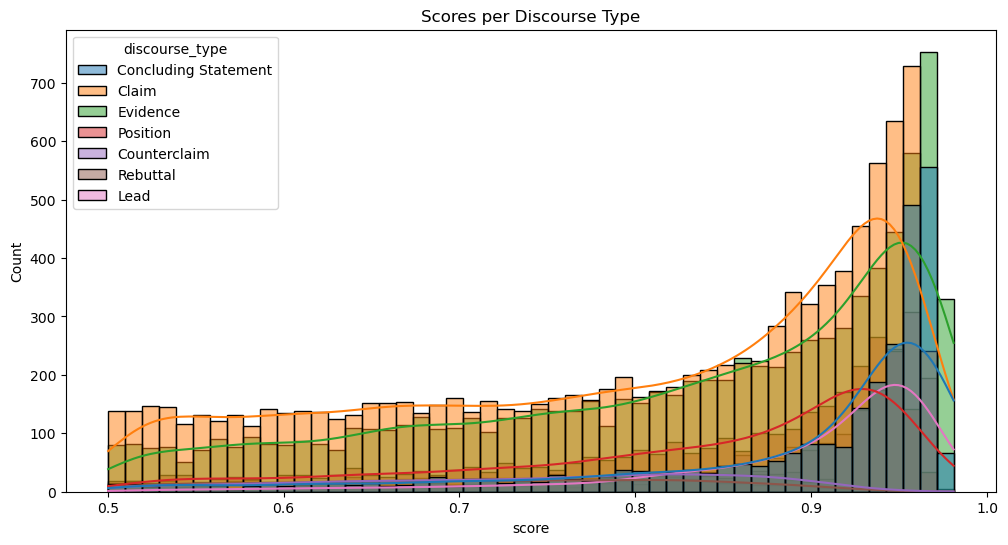

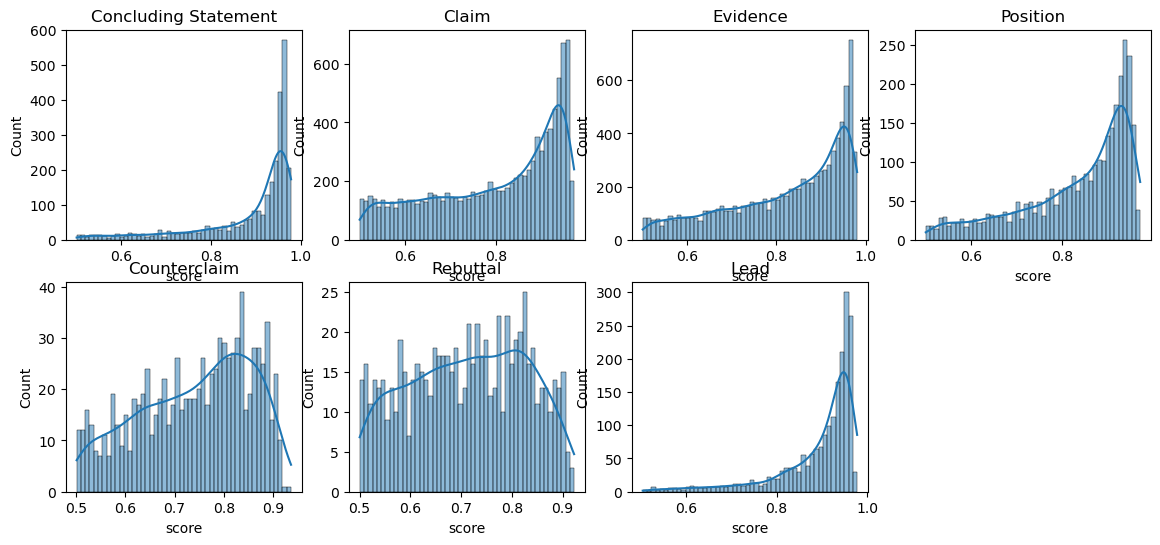

In [94]:
import matplotlib.pyplot as plt 
import seaborn as sns 

# create a histogram plot of 'score' per discourse_type
plt.figure(figsize=(12, 6))
sns.histplot(data=pred_df, x='score', hue='discourse_type', bins=50, kde=True)
plt.title('Scores per Discourse Type')

# same as above in subplot per discourse_type
plt.figure(figsize=(14, 6))
for i, dt in enumerate(pred_df['discourse_type'].unique()):
    plt.subplot(2, 4, i+1)
    sns.histplot(data=pred_df[pred_df['discourse_type']==dt], x='score', bins=50, kde=True)
    plt.title(f'{dt}')


<Axes: xlabel='score_eff_0', ylabel='Count'>

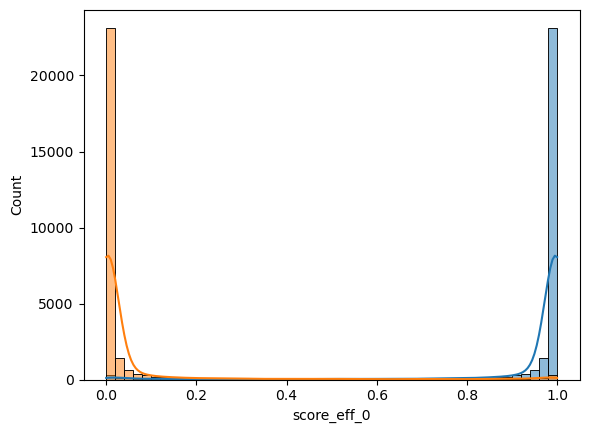

In [95]:
import seaborn as sns 

sns.histplot(data=pred_df, x='score_eff_0', bins=50, kde=True)
sns.histplot(data=pred_df, x='score_eff_1', bins=50, kde=True)

# Infer Test

In [ ]:
# CFG.infer = True
CFG.infer = False

In [96]:
class SpanDetectorDatasetTest(Dataset):
    def __init__(self, df, tokenizer,):
        
        self.df = df.copy() #pd.read_csv(csv_file)
        self.samples = list(self.df.groupby('id'))
        self.tokenizer = tokenizer
        print(f'Loaded {len(self)} samples.')


    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        text_id, df = self.samples[index]
        
        # text_path = os.path.join(self.text_dir, f'{text_id}.txt')
        # with open(text_path) as f:
        #     text = f.read().rstrip()
        text = df['essay_text'].values[0].rstrip()

        tokens = self.tokenizer(text, return_offsets_mapping=True)
        
        input_ids = torch.LongTensor(tokens['input_ids'])
        attention_mask = torch.LongTensor(tokens['attention_mask'])
        offset_mapping = np.array(tokens['offset_mapping'])
        offset_mapping = self.strip_offset_mapping(text, offset_mapping)
        num_tokens = len(input_ids)

        # token slices of words
        woff = self.get_word_offsets(text)
        toff = offset_mapping
        wx1, wx2 = woff.T
        tx1, tx2 = toff.T
        ix1 = np.maximum(wx1[..., None], tx1[None, ...])
        ix2 = np.minimum(wx2[..., None], tx2[None, ...])
        ux1 = np.minimum(wx1[..., None], tx1[None, ...])
        ux2 = np.maximum(wx2[..., None], tx2[None, ...])
        ious = (ix2 - ix1).clip(min=0) / (ux2 - ux1 + 1e-12)
        assert (ious > 0).any(-1).all()

        word_boxes = []
        for row in ious:
            inds = row.nonzero()[0]
            word_boxes.append([inds[0], 0, inds[-1] + 1, 1])
        word_boxes = torch.FloatTensor(word_boxes)


        return dict(
            text=text,
            text_id=text_id,
            input_ids=input_ids,
            attention_mask=attention_mask,
            word_boxes=word_boxes)
    

    def strip_offset_mapping(self, text, offset_mapping):
        ret = []
        for start, end in offset_mapping:
            match = list(re.finditer('\S+', text[start:end]))
            if len(match) == 0:
                ret.append((start, end))
            else:
                span_start, span_end = match[0].span()
                ret.append((start + span_start, start + span_end))
        return np.array(ret)

    def get_word_offsets(self, text):
        matches = re.finditer("\S+", text)
        spans = []
        words = []
        for match in matches:
            span = match.span()
            word = match.group()
            spans.append(span)
            words.append(word)
        assert tuple(words) == tuple(text.split())
        return np.array(spans)
    


class CustomCollatorTest(object):
    def __init__(self, tokenizer, model_name): #model
        self.pad_token_id = tokenizer.pad_token_id

        config_model = config = AutoConfig.from_pretrained(model_name)
        # if hasattr(model.config, 'attention_window'):
        if hasattr(config_model, 'attention_window'):
            # For longformer
            # https://github.com/huggingface/transformers/blob/v4.17.0/src/transformers/models/longformer/modeling_longformer.py#L1548
            self.attention_window = (
                config_model.attention_window if isinstance(
                    config_model.attention_window, int)
                else max(config_model.attention_window)
                )
        else:
            self.attention_window = None

    def __call__(self, samples):
        batch_size = len(samples)
        assert batch_size == 1, f'Only batch_size=1 supported, got batch_size={batch_size}.'

        sample = samples[0]

        max_seq_length = len(sample['input_ids'])
        if self.attention_window is not None:
            attention_window = self.attention_window
            padded_length = (attention_window -
                             max_seq_length % attention_window
                             ) % attention_window + max_seq_length
        else:
            padded_length = max_seq_length

        input_shape = (1, padded_length)
        input_ids = torch.full(input_shape,
                               self.pad_token_id,
                               dtype=torch.long)
        attention_mask = torch.zeros(input_shape, dtype=torch.long)
 
        seq_length = len(sample['input_ids'])
        input_ids[0, :seq_length] = sample['input_ids']
        attention_mask[0, :seq_length] = sample['attention_mask']
 
        text_id = sample['text_id']
        text = sample['text']
        word_boxes = sample['word_boxes']
        # gt_spans = sample['gt_spans']

        return dict(
            text_id=text_id,
            text=text,
            input_ids=input_ids,
            attention_mask=attention_mask,
            word_boxes=word_boxes,
            )
    

In [97]:
def generate_submission(df_sub, save_name=None, out_dir=OUTPUT, verbose=False):

    pred_df = df_sub.copy()
    print(pred_df.shape)
    print(pred_df.id.nunique())
    display(pred_df)

    # ## convert effective scores to RATER format 
    # pred_df['score_discourse_effectiveness_0'] = -100
    # pred_df['score_discourse_effectiveness_1'] = -100
    # for i, row in pred_df.iterrows():
    #     if row['class_eff'] == 2: #'Effective':  
    #         pred_df.loc[i, 'score_discourse_effectiveness_1'] = row['score_eff']
    #         pred_df.loc[i, 'score_discourse_effectiveness_0'] = 1 - row['score_eff']
    #     else:
    #         pred_df.loc[i, 'score_discourse_effectiveness_0'] = row['score_eff']
    #         pred_df.loc[i, 'score_discourse_effectiveness_1'] = 1 - row['score_eff']


    sample_sub = pd.read_csv(DIR / 'sample_submission.csv')

    sub = pred_df.copy()
    sub = sub.rename(columns={'id': 'essay_id_comp'})

    sub['score_discourse_effectiveness_0'] = pred_df['score_eff_0']
    sub['score_discourse_effectiveness_1'] = pred_df['score_eff_1']


    # sub["discourse_type"] = sub["class"].map(discourse_type_to_int)
    # sub["discourse_type"] = sub["discourse_type"].map(discourse_type_to_int)
    sub["discourse_type"] = sub["class"]

    sub = sub[sample_sub.columns]
    # if sub.essay_id_comp.nunique() == 10402:
    #     sub.to_csv(f'{out_dir}/{save_name}.csv', index=False)
    # else:
    #     print("check ids", sub.essay_id_comp.nunique())

    display(sub.head())
    print(sub.essay_id_comp.nunique() == 10402)
    
    ###
    if verbose:
        print(pred_df['class'].value_counts())
        print()
        print(pred_df['class_eff'].value_counts())
        print(pred_df['class_eff'].value_counts(normalize=True))
        print(sub.dtypes)

        import seaborn as sns 
        import matplotlib.pyplot as plt

        sns.histplot(sub.score_discourse_effectiveness_0)
        sns.histplot(sub.score_discourse_effectiveness_1)
        plt.show()

    return sub

In [99]:
if CFG.infer:

    test = pd.read_csv('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/input/test.csv')
    test.columns = ['id', 'essay_text']
    test['essay_id'] = test['id'] 

    print(test.shape)
    display(test.head())

    test_ds = SpanDetectorDatasetTest(test, tokenizer=CFG.tokenizer)
    # print(test_ds[0].keys())
    
    test_loader = DataLoader(test_ds,
                            batch_size=1,
                            shuffle=False,
                            num_workers=2,
                            collate_fn=CustomCollatorTest(CFG.tokenizer, CFG.model_name)
                            )

(10402, 3)


,id,essay_text,essay_id
0,BC75783F96E3,This essay will explain if drivers should or s...,BC75783F96E3
1,74C8BC7417DE,Driving while the use of cellular devices\n\nT...,74C8BC7417DE
2,97C1CFD04E4B,Cell phone use should not be legal while drivi...,97C1CFD04E4B
3,2CE1FE38D0E7,Phones and Driving\n\nDriving is a good way to...,2CE1FE38D0E7
4,30A8FB981469,PHONES AND DRIVING\n\nIn this world in which w...,30A8FB981469


In [102]:
if CFG.infer:

    print('test th:', model.test_score_thr)

    res = trainer.predict(model, test_loader, return_predictions=True)  
    pred_df = pd.concat([format_result(res[i]) for i in range(len(res)) if res[i] is not None])

    ####
    # sub = generate_submission(pred_df, test)

test th: 0.5


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: 0it [00:00, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (548 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (621 > 512). Running this sequence through the model will result in indexing errors


In [ ]:
# res = trainer.predict(model, test_loader, return_predictions=True)  

In [103]:
pred_df

,id,start,end,predictionstring,score,class,class_eff,score_eff,score_eff_0,score_eff_1,discourse_type
0,0006ED03C701,215,264,215 216 217 218 219 220 221 222 223 224 225 22...,0.949661,6,0,0.000869,0.999131,0.000869,Concluding Statement
1,0006ED03C701,73,88,73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88,0.860936,2,0,0.003743,0.996256,0.003743,Claim
2,0006ED03C701,90,187,90 91 92 93 94 95 96 97 98 99 100 101 102 103 ...,0.855816,3,0,0.001325,0.998675,0.001325,Evidence
3,0006ED03C701,59,73,59 60 61 62 63 64 65 66 67 68 69 70 71 72 73,0.832389,1,0,0.001464,0.998536,0.001464,Position
4,0006ED03C701,0,45,0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18...,0.766422,0,0,0.000734,0.999266,0.000734,Lead
...,...,...,...,...,...,...,...,...,...,...,...
4,FFFF690EF7F8,59,118,59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 7...,0.675318,3,0,0.000710,0.999290,0.000710,Evidence
5,FFFF690EF7F8,122,133,122 123 124 125 126 127 128 129 130 131 132 133,0.594777,2,0,0.000224,0.999776,0.000224,Claim
6,FFFF690EF7F8,11,19,11 12 13 14 15 16 17 18 19,0.551543,2,0,0.001510,0.998490,0.001510,Claim
7,FFFF690EF7F8,209,213,209 210 211 212 213,0.516335,1,0,0.000062,0.999938,0.000062,Position


In [107]:
pred_df.id.nunique()

10399

In [108]:
pred_df['class_eff'].value_counts()

class_eff
0    89163
1     3659
Name: count, dtype: int64

In [ ]:
# pred_df['score_eff'].hist(bins=50)
# pred_df['score_eff_1'].hist(bins=50)

In [ ]:
# sns.histplot(data=pred_df, x='score_eff_0', bins=50, kde=True)
# sns.histplot(data=pred_df, x='score_eff_1', bins=50, kde=True)

In [ ]:
# pred_df.rename(columns={
#     "score_eff_0": "score_discourse_effectiveness_0",
#     "score_eff_1": "score_discourse_effectiveness_1",
# }).to_csv(OUTPUT / f"test_preds_fold2_th05.csv", index=False)

In [ ]:
### stop here!

In [109]:
sub = generate_submission(pred_df)

(92822, 11)
10399


,id,start,end,predictionstring,score,class,class_eff,score_eff,score_eff_0,score_eff_1,discourse_type
0,0006ED03C701,215,264,215 216 217 218 219 220 221 222 223 224 225 22...,0.949661,6,0,0.000869,0.999131,0.000869,Concluding Statement
1,0006ED03C701,73,88,73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88,0.860936,2,0,0.003743,0.996256,0.003743,Claim
2,0006ED03C701,90,187,90 91 92 93 94 95 96 97 98 99 100 101 102 103 ...,0.855816,3,0,0.001325,0.998675,0.001325,Evidence
3,0006ED03C701,59,73,59 60 61 62 63 64 65 66 67 68 69 70 71 72 73,0.832389,1,0,0.001464,0.998536,0.001464,Position
4,0006ED03C701,0,45,0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18...,0.766422,0,0,0.000734,0.999266,0.000734,Lead
...,...,...,...,...,...,...,...,...,...,...,...
4,FFFF690EF7F8,59,118,59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 7...,0.675318,3,0,0.000710,0.999290,0.000710,Evidence
5,FFFF690EF7F8,122,133,122 123 124 125 126 127 128 129 130 131 132 133,0.594777,2,0,0.000224,0.999776,0.000224,Claim
6,FFFF690EF7F8,11,19,11 12 13 14 15 16 17 18 19,0.551543,2,0,0.001510,0.998490,0.001510,Claim
7,FFFF690EF7F8,209,213,209 210 211 212 213,0.516335,1,0,0.000062,0.999938,0.000062,Position


,essay_id_comp,predictionstring,score_discourse_effectiveness_0,score_discourse_effectiveness_1,discourse_type
0,0006ED03C701,215 216 217 218 219 220 221 222 223 224 225 22...,0.999131,0.000869,6
1,0006ED03C701,73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88,0.996256,0.003743,2
2,0006ED03C701,90 91 92 93 94 95 96 97 98 99 100 101 102 103 ...,0.998675,0.001325,3
3,0006ED03C701,59 60 61 62 63 64 65 66 67 68 69 70 71 72 73,0.998536,0.001464,1
4,0006ED03C701,0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18...,0.999266,0.000734,0


False


In [110]:
### Check missing ids 
missing_ids = list(set(test.id) - set(sub.essay_id_comp))
print(missing_ids)

if len(missing_ids)>0:

    dummy_sub = pd.read_csv('/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/submissions/sub_wbf_exp18_exp22_6ckp.csv')
    dummy_sub = dummy_sub[dummy_sub.essay_id_comp.isin(missing_ids)]
    dummy_sub = dummy_sub.reset_index(drop=True)
    display(dummy_sub)

    sub = pd.concat([sub, dummy_sub], ignore_index=True)

    print(sub.essay_id_comp.nunique() == 10402)

    # ['A32121C1963B', '17025BA7A3B3', 'E8C25EDACD20']
    # ['DEC69C9D9F72', '93E547BF9654', 'CCD8783CF958', '261DCD26AE0C', 'E8C25EDACD20', '178BED4E1487', '7572D2FA0521', '7EEF18A458A3']

['A32121C1963B', '17025BA7A3B3', 'E8C25EDACD20']


,essay_id_comp,predictionstring,score_discourse_effectiveness_0,score_discourse_effectiveness_1,discourse_type
0,A32121C1963B,16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 3...,0.995491,0.004509,3
1,17025BA7A3B3,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...,0.988291,0.011709,3
2,E8C25EDACD20,14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 2...,0.971349,0.028651,3


True


<Axes: xlabel='score_discourse_effectiveness_0', ylabel='Count'>

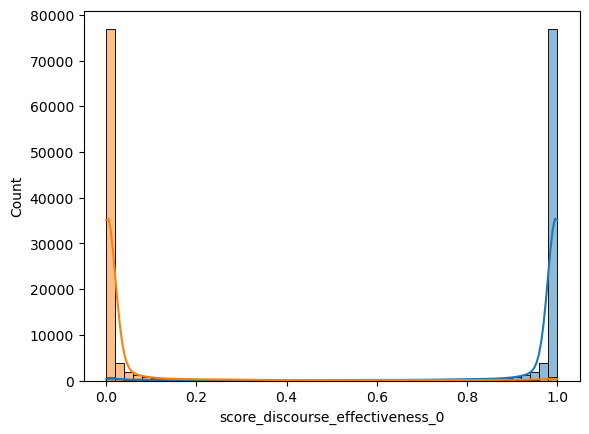

In [111]:
import seaborn as sns 

sns.histplot(data=sub, x='score_discourse_effectiveness_0', bins=50, kde=True)
sns.histplot(data=sub, x='score_discourse_effectiveness_1', bins=50, kde=True)

In [112]:
sub['discourse_type'].value_counts()

discourse_type
2    33446
3    28492
1    10474
6     9325
0     6094
4     2712
5     2282
Name: count, dtype: int64

In [113]:
sub.isnull().sum()

essay_id_comp                      0
predictionstring                   0
score_discourse_effectiveness_0    0
score_discourse_effectiveness_1    0
discourse_type                     0
dtype: int64

In [116]:
# OUTPUT
MDL_PATH[1]

'/mnt/md1/Work/dev_IME/Git_hacks/Feedback3/output/exp36_base/weights_f0/checkpoint-epoch=1-val_loss=6.3044.ckpt'

In [115]:
model.test_score_thr

0.5

In [117]:
# # sub.to_csv(OUTPUT / "sub_fold2_th04_2class_soft_f1_7715.csv", index=False)
# # sub.to_csv(OUTPUT / "sub_fold2_th05_2class_soft_f1_7774.csv", index=False)
# sub.to_csv(OUTPUT / "sub_fold0_th04.csv", index=False)

# sub.to_csv(OUTPUT / f"sub_fold0_th05_ckp0.csv", index=False)
sub.to_csv(OUTPUT / f"sub_fold0_th05_ckp1.csv", index=False)